# 2-motor: inductance

Measure the winding's inductance and the time constant of its current rise from a duty step into the locked rotor, with the ADC free running on the shunt and both terminals, and find out whether the rise is one pole on the time scale of the burst.

## Purpose

The current in a winding does not follow the voltage at once. It rises with a time constant $\tau = L / R$, the inductance over the resistance, and that time constant sets how much the current ripples inside one PWM window, how fast a duty step turns into torque, and how fast a current loop can be closed. The stage 5 current loop and the stage 6 trip timing are designed on it, and the in situ identification of stage 3 has to find the same number through a gear train and a case, so it is measured first on the bare motor where nothing else is in the way.

A brushed motor with an iron rotor is not always one pole. Eddy currents in the laminations and the brush contact can add terms on other time scales, and a design that assumes one pole where there are two reads the inductance from whatever stretch of the rise it happened to fit. So the second question here is whether $R$ and $L$ hold still over the time scales one burst covers, and if not, how far they move.

The rotor is locked by the rig's bar, so there is no back-EMF (electromotive force, the voltage a turning rotor generates) and the terminal voltage divides only between the resistance and the inductance. The bar's twelve holes, a full turn in 30 degree steps, put the commutator under the brushes at twelve angles. Three segments under two brushes repeat their pattern every 60 degrees, so holes of the same parity sit in the same phase of that pattern, six holes in each. Two duties and both signs separate what scales with the step from what depends on the angle. The groups of bursts at each hole come in an order that puts a different change before each group's first burst, so the step before a burst can be told apart from the burst itself.

What earlier work established, in conclusions only. A duty ramp read through the control-rate samples gave no inductance. The fitted time constant grew with the length of the fit and never flattened, and after a step the current kept creeping for 100 to 200 ms, far beyond any one-pole rise, with eddy currents in the rotor iron and a contact settling under its new current as the candidates. A free-running burst into the locked rotor shows the rise at a resolution the control-rate samples never have, and this experiment is that burst at the length the capture allows.

## Procedure

The bare motor in the rig with its leads on the board's motor connector, the bar on the pinion at hole 0 with its clamp snug, the board on the DPS with the adapter on its bus at 3 Mbps, and no meter. `capture.py` powers the board and trims the DPS until the rail reads 5.0 V. At each of the twelve holes it runs five groups of bursts with `osc-lab burst`, the shunt and both taps interleaved, each group one call into its own folder, in this order.

- `g1-fwd-25`, five bursts at 25 % forward. The bar has just moved and the motor has rested 20 s, and the hole before ended in reverse, so this group also follows a reversal.
- `g2-fwd-40`, five bursts at 40 % forward. A duty change with the sign kept.
- `g3-rev-40`, five bursts at 40 % reverse. A reversal with the duty kept.
- `g4-rev-25`, five bursts at 25 % reverse. A duty change with the sign kept.
- `g5-rev-25-rested`, three bursts at 25 % reverse after a 20 s rest. A rest alone, the same step as the group before it.

After the fifth group the motor rests 20 s and the bar moves to the next hole. `capture.py reversal`, run after the main capture with the bar left at hole 11 and nothing moved, runs six groups of five bursts, all at 25 %. The first keeps the sign the main run ended on, so it follows no reversal. Each later one reverses the sign of the one before it, after no rest, 5 s, 20 s and 50 s, and the last repeats the reversal with no rest, so a drift through the run would show.

Two more runs came after that, also at hole 11 with nothing moved. `capture.py steps` runs thirteen groups of five bursts with no rest between them, every forward group a 25 % step after a reverse group at 10, 25 or 40 %, so the first burst after a reversal can be read against the old sign's step. `capture.py fast` runs the main run's four groups in fast decay, and then a forward 25 % and a forward 40 % group in slow decay at the same seat.

An earlier four-hole capture first showed the jump of the first burst after a sign change, with a duty change mixed into the same step, and this capture separates the two.

1. The motor in the rig, leads on the connector, the bar at hole 0 with its clamp snug.
2. `capture.py`. It asks for the leads on the DPS, powers up, and prompts at each of holes 1 to 11 for the pins to come out, the bar to be turned to the hole and the pins to go back in, nothing pushing along the shaft.
3. `capture.py reversal`, with the bar left at hole 11.
4. `capture.py steps`, then `capture.py fast`, with the bar still at hole 11.

Each burst is about half a millisecond of drive at under half an amp, and the bursts of a group come 150 ms apart, so the copper stays within a fraction of a degree of the can.

## Data

- `capture-1/hole-<K>/<group>/burst-<k>.csv`: one file per burst, five per group and three in the rested group. `k` is the sample index, `code` the raw ADC sample, and the meta fields repeat on the first row. `step_q15` is the step's duty and sign, `step_index` the sample at which the step was applied, `start_cnt` and `start_dir` the PWM counter at the first sample, `pwm_arr` the counter's crest, `chans` and `frame_len` the frame, `vbus_raw` the rail read before the arm, `bias` and `vmotor_bias` the shunt and tap bias readings, `pos` the pot and `drive_polarity` the wiring's sign.
- `capture-1/hole-<K>/<group>/meta.json`: the servo's sense constants and the group's settings, not read here.
- `capture-1/marks.csv`: the host time at which each group and each rest began, and the end of each hole.
- `reversal-1/hole-11/<group>/` and `reversal-1/marks.csv`: the same for the reversal run.
- `steps-1/hole-11/<group>/`, `fast-1/hole-11/<group>/` and their `marks.csv`: the same for the two later runs. Their `meta.json` is read for the decay each group ran.
- From stage 1, `dev-v006-2A-D/bridge-states/capture-1/ra/bursts-fast/`, the fast-decay bursts on one 1 mH inductor and the resistor, drawn beside the motor's, and bridge-states' result file, the same method on its fixed inductors.

One group is left out of every fit. During `capture-1/hole-9/g5-rev-25-rested` a pin screw of the rig's bar was being unscrewed, so the rotor was not held the way it was for every other group. Its files stay in the dataset, the section on every burst shows how it reads against the group before it, and the figures draw it marked as excluded.

How the cells below read a burst's timing.

- A frame is the shunt, tap A, the shunt, tap B, one conversion every 26 ADC clocks at 24 MHz, which is 52 timer ticks or 1.083 us at 48 ticks per microsecond. The shunt is every second sample and each tap every fourth, so the shunt is read 23 times per 50 us PWM period and each tap 11 to 12 times.
- A burst holds 960 samples, 1.04 ms, and the step is applied near the buffer's half, so the first half is the amplifier's zero and the second half, about 0.52 ms or ten PWM periods, is the rise.
- The duty written at the step takes effect at the next PWM update, at the crest or the trough, so the drive may start with a half window. The analysis starts its period grid at the first commanded window start after the first trough after the step sample and reads each period on its own from there, so whatever came before the grid enters only as the current the first period starts from.
- The phase of each sample comes from the counter at the first sample and the fixed sample spacing, as `oscnb.bursts.phase` computes it, with the aperture of 13.5 ADC clocks added so a sample is placed where its aperture closed.
- The decay is slow, so the drive window is centered on the crest and between windows the bridge shorts the winding through its two low-side switches. The shunt sits in the common return of the low side, so it should carry the winding current only inside the window, and the terminals should read near zero between windows. The fold of one burst below checks both. `fast-1`'s first four groups run in fast decay, where the window sits on the trough and the bridge opens all four switches between windows, and the section on fast decay reads them.

In [1]:
import json
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

from oscnb import boards, bursts as bu, motors, results, tel

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"   # the house colors
MOTOR = motors.MOTORS[motors.DEFAULT]                                  # the motor, a parts count and nothing measured
BOARD = boards.BOARDS[boards.DEFAULT]                                  # the board, with the parts' nominal values
CAPTURE = (Path("../../../telemetry") / f"{MOTOR.key}__{BOARD.key}" / "inductance" / "capture-1").resolve()   # twelve holes, five groups each
REVERSAL = (Path("../../../telemetry") / f"{MOTOR.key}__{BOARD.key}" / "inductance" / "reversal-1").resolve()  # hole 11, the sign flipped after rests
STEPS = (Path("../../../telemetry") / f"{MOTOR.key}__{BOARD.key}" / "inductance" / "steps-1").resolve()        # hole 11, the old sign's step varied
FAST = (Path("../../../telemetry") / f"{MOTOR.key}__{BOARD.key}" / "inductance" / "fast-1").resolve()          # hole 11, fast decay, then two slow groups
BRIDGE = (Path("../../../telemetry") / BOARD.key / "bridge-states" / "capture-1").resolve()   # stage 1's RL dummy, for its fast-decay fold
RESISTOR = (Path("../../../telemetry") / BOARD.key / "sample-timing" / "capture-1").resolve()   # stage 1's bursts into the bare resistor load
LAPS = (Path("../../../telemetry") / BOARD.key / "current-scale" / "capture-1" / "bare").resolve()   # stage 1's 100 % laps into the same load
HOLES = sorted(int(p.name.split("-")[1]) for p in CAPTURE.glob("hole-*"))   # the bar's holes, a full turn in 30 degree steps
EXCLUDED = ("capture-1", 9, "g5-rev-25-rested")                        # a pin screw of the bar was being unscrewed during this group
# the change before each group's first burst, in capture order, as the figures label it
CHANGE = {"g1-fwd-25": "bar move\n+ reversal", "g2-fwd-40": "duty\n25 to 40 %", "g3-rev-40": "reversal",
          "g4-rev-25": "duty\n40 to 25 %", "g5-rev-25-rested": "20 s rest"}
RUN = {"r0-rev-25": "r0 reverse\nno reversal", "r1-fwd-25": "r1 forward\nno rest", "r2-rev-25-5s": "r2 reverse\nafter 5 s",
       "r3-fwd-25-20s": "r3 forward\nafter 20 s", "r4-rev-25-50s": "r4 reverse\nafter 50 s", "r5-fwd-25": "r5 forward\nno rest"}
ARR = BOARD.pwm_arr                                                    # ticks from the trough to the crest
PERIOD = 2 * ARR                                                       # ticks per PWM period, trough to trough
US = bu.STEP_TICKS / bu.TICKS_PER_US                                   # microseconds from one sample to the next
PERIOD_US = PERIOD / bu.TICKS_PER_US                                   # microseconds per PWM period
T_S = PERIOD_US * 1e-6                                                 # the same period in seconds, for the fit
print(MOTOR.key, "on", BOARD.key, "from", ", ".join(str(results.rel(p)) for p in (CAPTURE, REVERSAL, STEPS, FAST)))
print(f"a sample every {US:.3f} us, {PERIOD / bu.STEP_TICKS:.1f} samples per {PERIOD_US:.0f} us period, {bu.CONVERSION_CLK} ADC clocks each")

# the stage 1 conversions this notebook reads counts through: measured, from the result files, never the registry's nominal
CS = results.read("1-board", "current-scale", pair=BOARD.key)         # counts per amp on the meter, and the in-drive offset
TC = results.read("1-board", "terminal-chain", pair=BOARD.key)        # terminal counts per volt on the meter, and its offset
ST = results.read("1-board", "sample-timing", pair=BOARD.key)         # the bridge's edge lags and the shunt's settle, per rail
RR = results.read("2-motor", "rest-resistance", pair=MOTOR.key)       # the motor's resistance at 100 %, for the comparison
KE = results.read("2-motor", "bemf-coast", pair=MOTOR.key)["ke_v_s_per_rad"]["value"]   # volts per rad/s of the rotor, for the leftover volts
J_LO = RR["j_runup_kg_m2"]["lo"]                                       # the rotor's inertia, the smallest of rest-resistance's run-ups
BSR = results.read("1-board", "bridge-states", pair=BOARD.key)        # the same method on fixed inductors
COUNTS_PER_A, DRIVE_OFF = CS["counts_per_a"]["value"], CS["drive_offset_counts"]["value"]
COUNTS_PER_V, TERM_OFF = TC["terminal_counts_per_v"]["value"], TC["terminal_offset_counts"]["value"]
# 5.0 V sits between the two rails sample-timing graded, so the lags are the mean of the two
ON_LAG = np.mean([ST["on_edge_lag_7v4"]["value"], ST["on_edge_lag_3v7"]["value"]])            # the shunt's half crossing, amplifier included
TAP_ON_LAG = np.mean([ST["tap_on_edge_lag_7v4"]["value"], ST["tap_on_edge_lag_3v7"]["value"]])   # the bridge's own edge, from the tap
OFF_LAG = np.mean([ST["off_edge_lag_7v4"]["value"], ST["off_edge_lag_3v7"]["value"]])
SETTLE = np.mean([ST["shunt_settle_7v4"]["value"], ST["shunt_settle_3v7"]["value"]])
print(f"current, counts over the zero = {DRIVE_OFF:+.1f} + {COUNTS_PER_A:.1f} x amps. Terminals, tap difference = {TERM_OFF:+.1f} + {COUNTS_PER_V:.2f} x volts")
print(f"bridge ON edge {TAP_ON_LAG:.0f} ticks after the commanded start, shunt crossing {ON_LAG:.0f}, OFF edge {OFF_LAG:.0f} after the commanded end, "
      f"shunt settled {SETTLE:.0f} ticks after the commanded start")
print(f"Ke from bemf-coast {KE * 1e3:.4f} mV s/rad")

mg90-b on dev-v006-2A-D from telemetry/mg90-b__dev-v006-2A-D/inductance/capture-1, telemetry/mg90-b__dev-v006-2A-D/inductance/reversal-1, telemetry/mg90-b__dev-v006-2A-D/inductance/steps-1, telemetry/mg90-b__dev-v006-2A-D/inductance/fast-1
a sample every 1.083 us, 46.2 samples per 50 us period, 26 ADC clocks each
current, counts over the zero = +5.3 + 1135.0 x amps. Terminals, tap difference = +2.4 + 248.37 x volts
bridge ON edge 40 ticks after the commanded start, shunt crossing 44, OFF edge 14 after the commanded end, shunt settled 72 ticks after the commanded start
Ke from bemf-coast 1.1684 mV s/rad


### The order of the groups

Every group and rest of both runs on one time axis per hole, from the host times in `marks.csv`. Each bar runs from the mark of its group to the next mark, so it holds the group's bursts and the host's time around them. Filled bars are forward, hatched bars reverse, blue 25 % and orange 40 %, gray the rests.

capture-1, 276 bursts in 60 groups at 12 holes, 3 to 5 bursts each, 960 to 960 samples, frame of 4 to 4, step at sample 484 to 484, rail 4.98 to 5.01 V before the arm
reversal-1, 30 bursts in 6 groups at 1 holes, 5 to 5 bursts each, 960 to 960 samples, frame of 4 to 4, step at sample 484 to 484, rail 4.99 to 5.01 V before the arm
left out of every fit, 3 bursts of capture-1 hole 9 g5-rev-25-rested


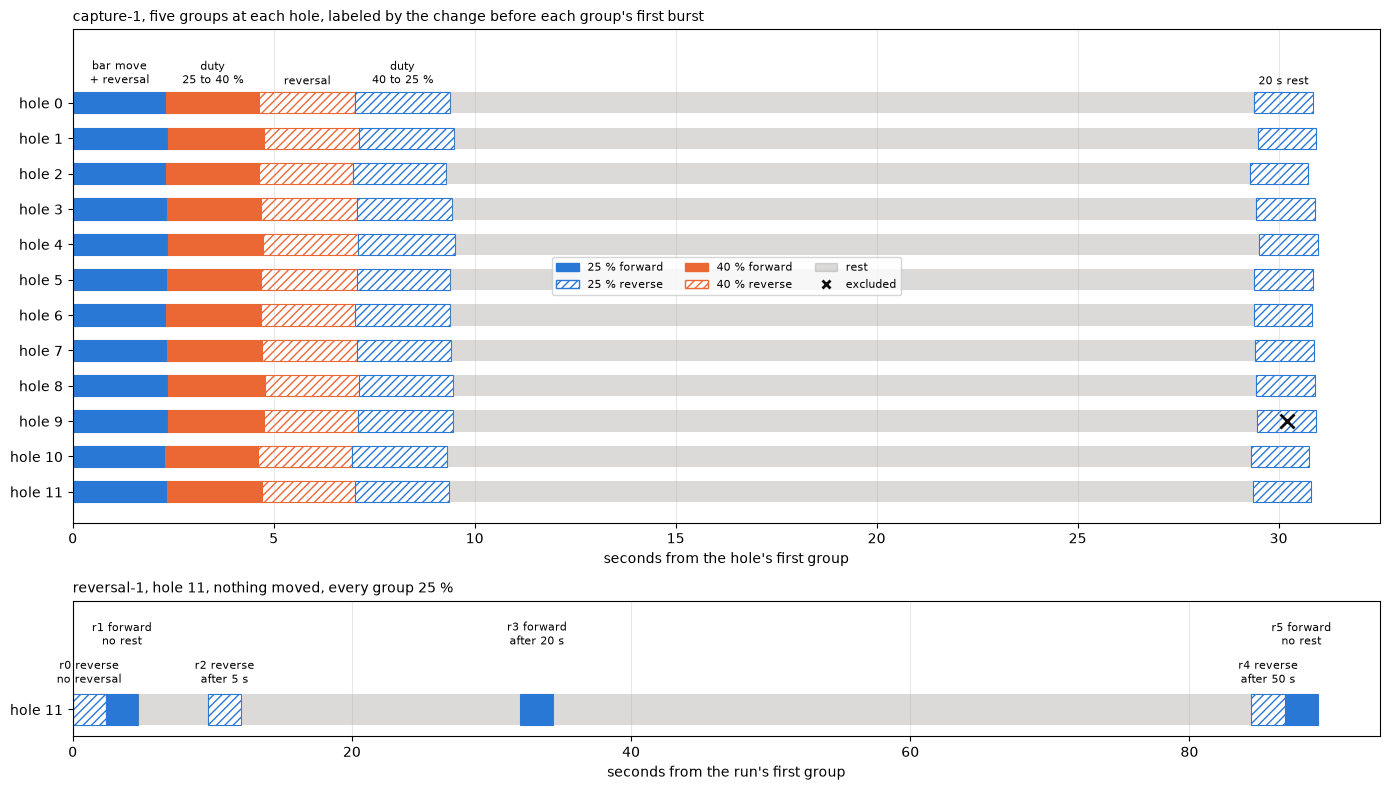

groups 2.30 to 2.40 s apart when no rest separates them. From the end of one hole to the next hole's first group 44 to 133 s, the 20 s rest and the bar move. Reversal-1 began 21 min after capture-1 ended


In [2]:
rows = []
for name, root in (("capture-1", CAPTURE), ("reversal-1", REVERSAL)):
    for hdir in sorted(root.glob("hole-*"), key=lambda p: int(p.name.split("-")[1])):
        for gdir in sorted(p for p in hdir.iterdir() if p.is_dir()):    # the group folders sort in capture order, g1 to g5 and r0 to r5
            for k, df in enumerate(bu.load(gdir)):
                m = bu.meta(df)
                rows.append({"set": name, "hole": int(hdir.name.split("-")[1]), "group": gdir.name, "k": k,
                             "pct": int(round(abs(m["step_q15"]) * 100 / 32768)), "sign": 1 if m["step_q15"] > 0 else -1,
                             "samples": len(df), "step_index": m["step_index"], "frame_len": m["frame_len"],
                             "rail_v": float(BOARD.rail_v(m["vbus_raw"])), "df": df})
B = pd.DataFrame(rows)
B["first"] = B["k"] == 0                                               # the first burst of its group, the one a change comes before
B["excluded"] = (B["set"] == EXCLUDED[0]) & (B["hole"] == EXCLUDED[1]) & (B["group"] == EXCLUDED[2])
DUTIES = sorted(B["pct"].unique())
COLOR = dict(zip(DUTIES, (BLUE, ORANGE)))                              # one color per duty, fixed through the notebook
for name, g in B.groupby("set", sort=False):
    size = g.groupby(["hole", "group"]).size()
    print(f"{name}, {len(g)} bursts in {len(size)} groups at {g['hole'].nunique()} holes, {size.min()} to {size.max()} bursts each, "
          f"{g['samples'].min()} to {g['samples'].max()} samples, frame of {g['frame_len'].min()} to {g['frame_len'].max()}, "
          f"step at sample {g['step_index'].min()} to {g['step_index'].max()}, rail {g['rail_v'].min():.2f} to {g['rail_v'].max():.2f} V before the arm")
print(f"left out of every fit, {B['excluded'].sum()} bursts of {EXCLUDED[0]} hole {EXCLUDED[1]} {EXCLUDED[2]}")

def marks(root):
    # the host time each group and rest began, split into the hole and the mark's name
    mk = pd.read_csv(root / "marks.csv")
    mk["hole"] = mk["mark"].str.split("/").str[0].str.removeprefix("hole-").astype(int)
    mk["name"] = mk["mark"].str.split("/").str[1]
    return mk

fig, ax = plt.subplots(2, 1, figsize=(14, 8), gridspec_kw={"height_ratios": [4, 1.1]})
for a, (name, root) in zip(ax, (("capture-1", CAPTURE), ("reversal-1", REVERSAL))):
    mk = marks(root)
    for h, g in mk.groupby("hole"):
        t0 = g["t_host"].iloc[0]                                           # the hole's first group
        for (_, r), t_end in zip(g.iloc[:-1].iterrows(), g["t_host"].iloc[1:]):
            x, w = r["t_host"] - t0, t_end - r["t_host"]
            if r["name"] == "rest":
                a.barh(h, w, left=x, height=0.6, color=MUTED, alpha=0.3)
                continue
            e = B[(B["set"] == name) & (B["hole"] == h) & (B["group"] == r["name"])].iloc[0]
            c = COLOR[e["pct"]]
            a.barh(h, w, left=x, height=0.6, color=c if e["sign"] > 0 else "white", edgecolor=c, hatch=None if e["sign"] > 0 else "////", lw=0.8)
            if (name, h, r["name"]) == EXCLUDED:
                a.plot(x + w / 2, h, "x", color=INK, ms=10, mew=2)
            if name == "reversal-1":                                       # two rows of labels, the groups sit close together
                j = list(RUN).index(r["name"])
                a.annotate(RUN[r["name"]], (x + w / 2, h - 0.45 - 0.75 * (j % 2)), ha="center", va="bottom", fontsize=8)
            elif h == HOLES[0]:
                a.annotate(CHANGE[r["name"]], (x + w / 2, h - 0.45), ha="center", va="bottom", fontsize=8)
    a.set_yticks(sorted(mk["hole"].unique()), [f"hole {h}" for h in sorted(mk["hole"].unique())])
    a.invert_yaxis(); a.grid(alpha=0.3, axis="x")
lo, hi = ax[0].get_ylim(); ax[0].set_ylim(lo, hi - 1.2)                # room above hole 0 for the labels of the change before each group
lo, hi = ax[1].get_ylim(); ax[1].set_ylim(lo + 0.2, hi - 1.8)
ax[0].set_xlabel("seconds from the hole's first group"); ax[1].set_xlabel("seconds from the run's first group")
ax[0].set_title("capture-1, five groups at each hole, labeled by the change before each group's first burst", loc="left", fontsize=10)
ax[1].set_title("reversal-1, hole 11, nothing moved, every group 25 %", loc="left", fontsize=10)
ax[0].legend(handles=[Patch(color=BLUE, label="25 % forward"), Patch(facecolor="white", edgecolor=BLUE, hatch="////", label="25 % reverse"),
                      Patch(color=ORANGE, label="40 % forward"), Patch(facecolor="white", edgecolor=ORANGE, hatch="////", label="40 % reverse"),
                      Patch(color=MUTED, alpha=0.3, label="rest"),
                      plt.Line2D([], [], ls="none", marker="x", color=INK, mew=2, label="excluded")], fontsize=8, loc="center", ncol=3)
plt.tight_layout(); plt.show()

mk = marks(CAPTURE)
starts = mk[mk["name"] == "g1-fwd-25"].set_index("hole")["t_host"]
ends = mk[mk["name"] == "done"].set_index("hole")["t_host"]
gaps = [starts[h] - ends[h - 1] for h in HOLES[1:]]                   # the 20 s rest and the bar move between two holes
spacing = mk[~mk["name"].isin(["rest", "done"])].groupby("hole")["t_host"].diff().dropna()
spacing = spacing[spacing < 5]                                         # group to group with no rest between them
mr = marks(REVERSAL)
print(f"groups {spacing.min():.2f} to {spacing.max():.2f} s apart when no rest separates them. From the end of one hole to the next hole's first group "
      f"{min(gaps):.0f} to {max(gaps):.0f} s, the 20 s rest and the bar move. Reversal-1 began {(mr['t_host'].iloc[0] - ends[HOLES[-1]]) / 60:.0f} min "
      f"after capture-1 ended")

Every hole ran the same sequence. The groups came 2.3 to 2.4 s apart when no rest separated them, so a group's first burst followed the last burst of the group before it by about 2 s. From the end of one hole to the first group of the next took 44 to 133 s, the 20 s rest and the bar move. Hole 0's first group is the first step after the power-up, and the sign before it is not in this dataset. The reversal run began 21 minutes after capture-1 ended, at the same hole with nothing moved, so its first group follows capture-1's last sign across that pause.

### One burst

The second burst of the forward 25 % group at hole 0 as recorded, the shunt and the two taps against time from the step. The second rather than the first, since the first burst of a group can read apart from the others, which a later section shows.

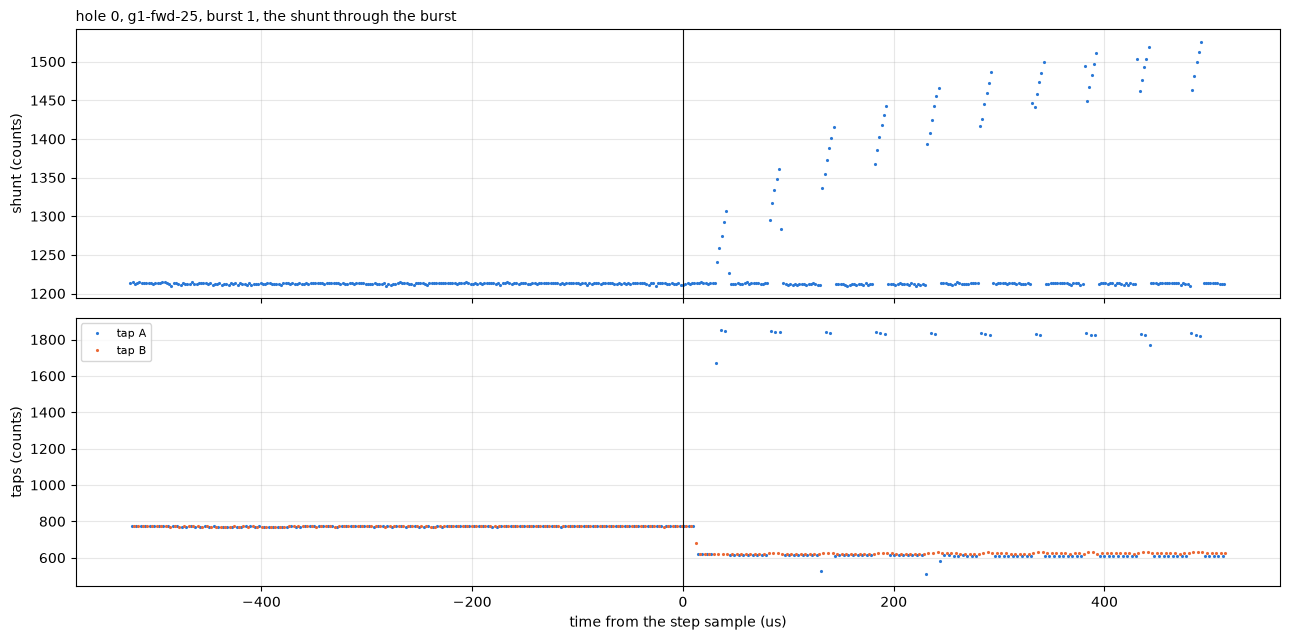

zero 1213.0 counts over the pre-step half, 516 us after the step, 10.3 periods. Taps before the step, A 772, B 772 counts, after it tap B 625 counts


In [3]:
def one(hole, group, k=1, name="capture-1"):
    # the k-th burst of one group; the second by default, since the first of a group can read apart (below)
    return B[(B["set"] == name) & (B["hole"] == hole) & (B["group"] == group)].iloc[k]

ex = one(0, "g1-fwd-25")
df = ex["df"]
m, ph, sh, ta, tb = bu.phase(df, ARR)
t = (np.arange(len(df)) - m["step_index"]) * US                        # microseconds from the step sample
y = df["code"].to_numpy(float)
fig, ax = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)
ax[0].plot(t[sh], y[sh], ".", ms=2.5, color=COLOR[ex["pct"]])
ax[0].axvline(0, color=INK, lw=0.8); ax[0].set_ylabel("shunt (counts)")
ax[0].set_title(f"hole {ex['hole']}, {ex['group']}, burst {ex['k']}, the shunt through the burst", loc="left", fontsize=10)
ax[1].plot(t[ta], y[ta], ".", ms=2.5, color=BLUE, label="tap A"); ax[1].plot(t[tb], y[tb], ".", ms=2.5, color=ORANGE, label="tap B")
ax[1].axvline(0, color=INK, lw=0.8); ax[1].set_ylabel("taps (counts)"); ax[1].legend(fontsize=8, loc="upper left")
ax[1].set_xlabel("time from the step sample (us)")
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"zero {bu.zero(df, ARR):.1f} counts over the pre-step half, {(len(df) - m['step_index']) * US:.0f} us after the step, "
      f"{(len(df) - m['step_index']) * US / PERIOD_US:.1f} periods. Taps before the step, A {np.median(y[ta][:m['step_index'] // 4]):.0f}, "
      f"B {np.median(y[tb][:m['step_index'] // 4]):.0f} counts, after it tap B {np.median(y[tb][m['step_index'] // 4 + 30:]):.0f} counts")

The amplifier's zero for half a millisecond, then a window every 50 us. Inside each window the shunt jumps up and keeps climbing, and the level it jumps to climbs from window to window as the current builds. Before the step the bridge is off and both taps read the bias node, about 772 counts. After it tap A is the driven terminal and sits near the rail inside each window. Tap B is the return, and it and tap A between windows read about 620 counts, a terminal held at ground. The few tap A samples far under that sit on the edges, which a later section looks at.

### The same burst folded onto the PWM period

Every sample after the step at its phase in the period, colored from the first full period to the last, the shunt on the left and the terminal difference on the right.

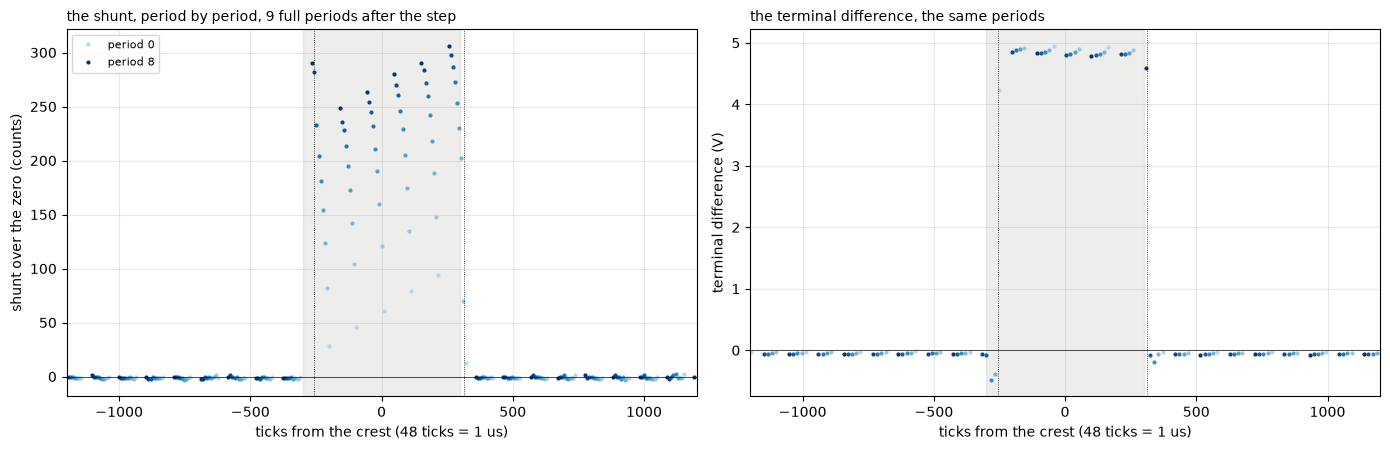

the shunt between windows -0.6 counts over the zero (sd 0.9), against the rest floor of about a count


In [4]:
def samples(df, center="crest"):
    # one row per sample: its stream, its code, the tick its aperture closed on an unwrapped axis, its phase from the center of
    # the drive window (the crest in slow decay, the trough in fast), and its period on a grid that starts at the first full
    # commanded window after the step. The duty written at the step takes effect at the next trough, so the grid starts at the
    # crest window after it in slow decay and at the trough window one period later in fast decay, where the first trough's
    # window holds only its second half
    m, ph, sh, ta, tb = bu.phase(df, ARR)
    half = int(BOARD.drive_ticks(m["step_q15"]))                         # the window's half-width in ticks
    k = np.arange(len(df))
    phi0 = m["start_cnt"] if m["start_dir"] == 0 else PERIOD - m["start_cnt"]   # the counter's phase at the first sample, 0 at the trough
    tick = phi0 + bu.STEP_TICKS * k + bu.APERTURE_CLK * bu.TICKS_PER_ADC_CLK   # when each aperture closed, never wrapped
    trough = PERIOD * np.ceil(tick[m["step_index"]] / PERIOD)             # the first trough after the step sample
    c = ARR if center == "crest" else PERIOD                               # the first full window's center after that trough
    origin = trough + c - half                                            # its commanded start
    n = np.floor((tick - origin) / PERIOD).astype(int)                    # period index on the window-aligned grid, negative before it
    last = int(np.floor((tick[-1] - origin) / PERIOD))                    # the partial period at the end is dropped
    tc = ((tick - c) % PERIOD + PERIOD // 2) % PERIOD - PERIOD // 2       # ticks from the nearest window center
    stream = np.where(sh, "sh", np.where(ta, "ta", "tb"))
    s = pd.DataFrame({"k": k, "stream": stream, "code": df["code"].to_numpy(float), "tick": tick, "tc": tc, "n": n,
                      "t_us": (tick - origin) / bu.TICKS_PER_US, "full": n < last})
    return s, m, half

s, m, half = samples(df)
zero = bu.zero(df, ARR)
post = s[(s["n"] >= 0) & s["full"]]
N = post["n"].max() + 1
shade = plt.cm.Blues(np.linspace(0.3, 1.0, N)) if COLOR[ex["pct"]] == BLUE else plt.cm.Oranges(np.linspace(0.3, 1.0, N))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for n, g in post.groupby("n"):
    g_sh = g[g["stream"] == "sh"]
    ax[0].plot(g_sh["tc"], g_sh["code"] - zero, ".", ms=4, color=shade[n], label=f"period {n}" if n in (0, N - 1) else None)
    # the taps are read 52 ticks apart, so the difference is drawn at tap A's phase against the nearest tap B sample
    a, b = g[g["stream"] == "ta"], g[g["stream"] == "tb"]
    vb = np.interp(a["tick"], b["tick"], b["code"]) if len(b) > 1 else np.nan
    ax[1].plot(a["tc"], (ex["sign"] * (a["code"] - vb) - TERM_OFF) / COUNTS_PER_V, ".", ms=4, color=shade[n])
for a in ax:
    a.axvspan(-half, half, color=MUTED, alpha=0.15)                      # the commanded window
    a.axvline(-half + ON_LAG, color=INK, lw=0.6, ls=":"); a.axvline(half + OFF_LAG, color=INK, lw=0.6, ls=":")   # the edges sample-timing found
    a.axhline(0, color=INK, lw=0.5); a.set_xlabel("ticks from the crest (48 ticks = 1 us)"); a.grid(alpha=0.3); a.set_xlim(-ARR, ARR)
ax[0].set_ylabel("shunt over the zero (counts)"); ax[0].legend(fontsize=8, loc="upper left")
ax[0].set_title(f"the shunt, period by period, {N} full periods after the step", loc="left", fontsize=10)
ax[1].set_ylabel("terminal difference (V)"); ax[1].set_title("the terminal difference, the same periods", loc="left", fontsize=10)
plt.tight_layout(); plt.show()
clear = (post["tc"] > half + OFF_LAG + 100) | (post["tc"] < -half - 100)   # well clear of both edges
off = post[(post["stream"] == "sh") & clear]
print(f"the shunt between windows {off['code'].mean() - zero:+.1f} counts over the zero (sd {off['code'].std():.1f}), against the rest floor of about a count")

Each period draws the window once, the commanded window shaded and the dotted lines the edges sample-timing found on a resistor, and the color walks from light to dark as the current rises. On the left the shunt jumps at the ON edge to a level that climbs from period to period, ramps up through the window, and falls back to its zero at the OFF edge. Between windows it stays at the zero to within a count. On the right the terminal difference is near the rail inside the window and a few tens of millivolts under zero outside it, where the bridge shorts the winding through the low side and the current crossing the two low-side switches drops a little voltage on them. A few samples at the ON edge dip under zero, which the section on the bridge's edges returns to.

## Method

### The window level is the winding current

The fold settles which reading of the shunt is the winding current. Between windows the shunt reads its zero, so the current that keeps circulating through the low side during the brake interval does not cross it. The shunt's mean over a period is therefore the window's share of the winding current, about a quarter of it at 25 %, and not the current itself. Inside the window the whole winding current crosses the shunt, so the window's level is the winding current.

The winding current also ripples inside the period. It rises through the window and falls through the brake interval after it. With a time constant of a few periods both parts are close to straight lines. The mean of a rising line over the window is its value at the window's middle, and for a ripple made of two straight segments that is also the current's mean over the period. So each period's current $i_n$ is read as a line through the window's settled shunt samples, evaluated at the middle between the bridge's two edges, which sample-timing placed from the commanded edges. The in-drive offset of the current-scale result is taken off and the counts go through its counts per amp.

### The applied volts

The volts each period applies are the tap difference over the whole period, read in two parts weighted by their durations. The window between the bridge's edges carries the mean of its settled tap samples, and the brake interval carries the mean of the samples clear of both edges, both through the terminal-chain result with its offset taken off. The period mean, $V_n$, is not the duty times the rail. The bridge's switches and the supply drop more as the current grows, so $V_n$ falls through the burst, and a fit of the rise against one fixed voltage would fold that fall into $\tau$. The fit below takes the volts each period actually applied.

### The fit

The winding is a resistance and an inductance in series, with the rotor locked so no speed voltage enters:

$$v = R\,i + L\,\frac{di}{dt}$$

Over one period, from the middle of window $n$ to the middle of window $n+1$, the volt-seconds the period applied go into the resistance and into the change of current:

$$L\,(i_{n+1} - i_n) = T\left(V_n - R\,\frac{i_n + i_{n+1}}{2}\right)$$

with $T$ the 50 us period. That is linear in $R$ and $L$, so one least squares over a burst's period pairs gives both, and $\tau = L / R$. Nothing is extrapolated to an asymptote and no time origin is fitted. A one-pole winding gives the same $R$ and $L$ from any stretch of the burst. So the same fit is also run over the first 3, 4 and more pairs, and $R$ and $L$ against the number of pairs is the test of one pole.

### The ripple

The slope of the line inside each window is the current's rise while the window applies $V_\mathrm{on}$, so the window on its own gives a second inductance,

$$L_\mathrm{ripple} = \frac{V_\mathrm{on} - R\,i_n}{(di/dt)_\mathrm{window}}$$

with $R$ from the burst's fit. It reads the winding over the 12 to 20 us of one window, where the fit reads it over 50 us periods and a rise of half a millisecond. A one-pole winding gives the same $L$ both ways.

### The window's scale

Both $R$ and $L$ are volts over amps read inside a short window, and stage 1 graded the chains at 100 % duty, where nothing switches. Any difference between the two readings shows on a load with no inductance. Sample-timing recorded bursts into the bare resistor load with the same frame, and the current-scale laps of stage 1 drove the same load at 100 %. The window's $V_\mathrm{on} / i$ on those bursts over the laps' $V / I$ is the window's scale $k$, and $R$ and $L$ from the motor's bursts are divided by it. It cancels in $\tau$.

### Error bars

A group of five bursts gives one first burst and four others, three others in the rested groups. The summaries of $L$, $\tau$ and $R$ take the others only, since the first burst of a group can read apart from them, and the first burst is read on its own against the median of its group's others. The error bar is the agreement between the bursts or the groups, the median with the range, and not a standard deviation, which four or five values do not support. The spread across the holes is what the commutator's angle does to the number.

### The window's scale on the resistor

The bare load read both ways. On the left, the window's $V_\mathrm{on} / i$ for every sample-timing burst at 15 % and up, against the duty, at the 7.4 V and the 3.7 V rail. On the right, the laps' $V / I$ at every graded level, both directions. The shaded band on the left is the range of the laps.

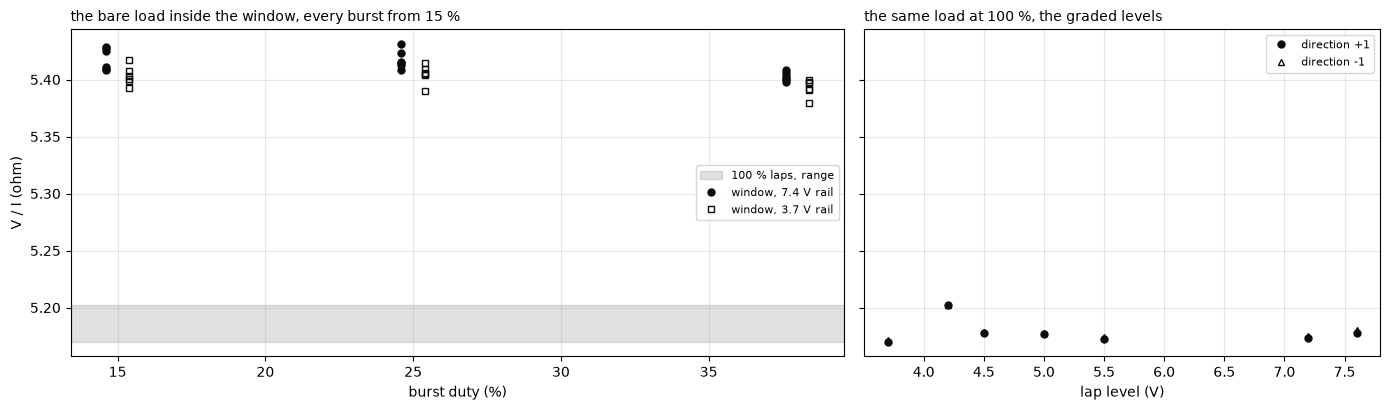

window 5.406 ohm (5.379 to 5.431) over 36 bursts at 0.61 to 1.24 A. 100 % laps 5.177 ohm (5.170 to 5.202) over 14 laps at 0.63 to 1.31 A
k = 1.0442 (1.0391 to 1.0491). The window's slope on the resistor, per amp of level, 15 % -3119 A/s, 25 % -1091 A/s, 38 % -333 A/s


In [5]:
def periods(df, sign, edge=0.0):
    # one row per full period after the step: the winding current at the middle of the bridge's window, the volts the
    # period applied, the window's own volts and slope, and what the shunt reads between windows. `edge` is the volt-ticks
    # the two edges hold beyond the two-part mean, from the pooled edge profile below; 0 for a load with no inductance
    s, m, half = samples(df)
    zero = bu.zero(df, ARR)                                                # the amplifier's zero from the pre-step shunt samples
    a, b = -half + TAP_ON_LAG, half + OFF_LAG                              # the bridge's ON and OFF edges in ticks from the crest
    on_span = b - a                                                        # ticks the bridge drives in each period
    s = s[(s["n"] >= 0) & s["full"]].assign(y=lambda d: d["code"] - zero)
    settled = (s["tc"] >= -half + SETTLE) & (s["tc"] <= half)              # inside the window, after the amplifier's settle, before the OFF edge
    clear = (s["tc"] >= b + SETTLE - ON_LAG) | (s["tc"] <= -half - 10)    # the brake interval, clear of the OFF edge's tail and before the next commanded start
    rows = []
    for n, g in s.groupby("n"):
        sh = g[(g["stream"] == "sh") & settled[g.index]]
        line = np.polyfit(sh["tc"], sh["y"], 1)                            # the ramp inside the window, which a line follows over 25 us
        i_on = (np.polyval(line, (a + b) / 2) - DRIVE_OFF) / COUNTS_PER_A  # at the window's middle, less the in-drive offset, in amps
        i_off = g[(g["stream"] == "sh") & clear[g.index]]["y"].mean() / COUNTS_PER_A   # the shunt between windows, in amps
        d_on, d_off = ((g[(g["stream"] == "ta") & w[g.index]]["code"].mean() - g[(g["stream"] == "tb") & w[g.index]]["code"].mean())
                       for w in (settled, clear))                          # tap A less tap B, inside the window and between windows
        v_on, v_off = ((sign * d - TERM_OFF) / COUNTS_PER_V for d in (d_on, d_off))   # the terminal-chain line inverted, signed by the step
        rows.append({"n": n, "t_us": (n * PERIOD + half + (a + b) / 2) / bu.TICKS_PER_US,   # the window's middle, from the first commanded start
                     "i_a": i_on, "v_v": (v_on * on_span + v_off * (PERIOD - on_span) + edge) / PERIOD,
                     "v_on_v": v_on, "v_off_v": v_off, "i_off_a": i_off,
                     "slope_a_per_s": line[0] * bu.TICKS_PER_US * 1e6 / COUNTS_PER_A, "on_n": len(sh)})
    return pd.DataFrame(rows)

# the bursts sample-timing recorded into the bare load, read the same way; 10 % leaves one or two settled shunt samples in a
# window, too few for the line, so the comparison starts at 15 %
rows = []
for folder, rail in (("bursts", 7.4), ("bursts-1s", 3.7)):
    for df_r in bu.load(RESISTOR / folder):
        m_r = bu.meta(df_r)
        pct = int(round(abs(m_r["step_q15"]) * 100 / 32768))
        if pct < 15:
            continue
        P = periods(df_r, 1 if m_r["step_q15"] > 0 else -1).iloc[1:]      # the first period left out, the rail still taking the step
        rows.append({"rail": rail, "pct": pct, "r_ohm": P["v_on_v"].median() / P["i_a"].median(), "i_a": P["i_a"].median(),
                     "slope_a_per_s": P["slope_a_per_s"].median()})
RW = pd.DataFrame(rows)

# the same load at 100 %: stage 1's current-scale laps, each direction's V/I as the median over 60 to 300 ms after the drive's
# first row, the stretch rest-resistance reads its laps over; only the levels stage 1 graded, 3.7 V and up
levels = pd.read_csv(LAPS / "levels.csv")
rows = []
for _, L in levels[levels["volts_set"] >= TC["rail_range_v"]["lo"]].iterrows():
    d_l, meta_l = tel.load(LAPS / L["folder"], BOARD)                    # checks the sense block against the board entry
    zero_l = float(tel.baseline(d_l)["current_raw"].median())           # the lap's own torque-off zero
    fs = meta_l.get("tick_hz", 20_000)
    for seg, g in d_l[d_l["seg"] > 0].groupby("seg"):
        d = int(g["dir"].iloc[0])
        on = int(np.flatnonzero(g["duty_counts"].to_numpy() != 0)[0])   # the drive's first row
        g = g.iloc[on + int(0.060 * fs):on + int(0.300 * fs)]
        i = (g["current_raw"].to_numpy(float) - zero_l - DRIVE_OFF) / COUNTS_PER_A
        v = ((g["vmotor_a"] - g["vmotor_b"]).to_numpy(float) * d - TERM_OFF) / COUNTS_PER_V
        rows.append({"level": float(L["volts_set"]), "dir": d, "r_ohm": float(np.median(v / i)), "i_a": float(np.median(i))})
RL = pd.DataFrame(rows)
K = RW["r_ohm"].median() / RL["r_ohm"].median()                       # the window's scale over the 100 % reading
K_LO, K_HI = RW["r_ohm"].min() / RL["r_ohm"].median(), RW["r_ohm"].max() / RL["r_ohm"].median()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True, gridspec_kw={"width_ratios": [3, 2]})
ax[0].axhspan(RL["r_ohm"].min(), RL["r_ohm"].max(), color=MUTED, alpha=0.25, label="100 % laps, range")
for rail, mk in ((7.4, "o"), (3.7, "s")):
    g = RW[RW["rail"] == rail]
    ax[0].plot(g["pct"] + (0.4 if rail < 5 else -0.4), g["r_ohm"], mk, ms=5, color=INK, mfc="none" if rail < 5 else INK, ls="none",
               label=f"window, {rail} V rail")
ax[0].set_xlabel("burst duty (%)"); ax[0].set_ylabel("V / I (ohm)"); ax[0].legend(fontsize=8, loc="center right")
ax[0].set_title("the bare load inside the window, every burst from 15 %", loc="left", fontsize=10)
for d, mk in ((1, "o"), (-1, "^")):
    g = RL[RL["dir"] == d]
    ax[1].plot(g["level"], g["r_ohm"], mk, ms=5, color=INK, mfc=INK if d > 0 else "none", ls="none", label=f"direction {d:+d}")
ax[1].set_xlabel("lap level (V)"); ax[1].legend(fontsize=8)
ax[1].set_title("the same load at 100 %, the graded levels", loc="left", fontsize=10)
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"window {RW['r_ohm'].median():.3f} ohm ({RW['r_ohm'].min():.3f} to {RW['r_ohm'].max():.3f}) over {len(RW)} bursts at "
      f"{RW['i_a'].min():.2f} to {RW['i_a'].max():.2f} A. 100 % laps {RL['r_ohm'].median():.3f} ohm ({RL['r_ohm'].min():.3f} to {RL['r_ohm'].max():.3f}) "
      f"over {len(RL)} laps at {RL['i_a'].min():.2f} to {RL['i_a'].max():.2f} A")
print(f"k = {K:.4f} ({K_LO:.4f} to {K_HI:.4f}). The window's slope on the resistor, per amp of level, "
      + ", ".join(f"{p} % {(g['slope_a_per_s'] / g['i_a']).median():+.0f} A/s" for p, g in RW.groupby("pct")))

The window reads the bare load about 4 % high against the 100 % laps, by close to the same amount at every duty from 15 to 38 % and at both rails. The window's readings spread over about a percent with no trend in duty or rail, and the laps over about half that, so $k$ is known to about half a percent either way. It is the factor the motor's $R$ and $L$ are divided by. Bridge-states reads it another way, and the section on the method on a fixed inductor carries the difference.

Which chain owns the factor, the shunt inside the window or the taps, is not separated here. It makes no difference to $R$ and $L$, which are both a volts-over-amps reading. The printed slopes are what the shunt's line reads inside the window on a load that has no inductance. A resistor's current is flat across the window, so this is the chain's own drift through the window, steepest in the shortest window. Scaled to the motor's currents it is about 4 % of the motor's own ramp at 25 % and about 2 % at 40 %, and it sits under $L_\mathrm{ripple}$ as a floor.

### The bridge's edges

The fold showed the terminal difference dipping under zero at the ON edge. Under an inductive load the current keeps flowing through the bridge's dead time at each edge, when neither switch of the driven half is on, so it runs through a switch's body diode and the driven terminal sits a diode drop under ground. The two-part mean gives those ticks the brake level. Below, the driven terminal around each commanded edge, pooled over every full period of every burst of one duty and sign in capture-1, against the two-part model's levels for the same samples. The difference between the two, summed over both edges, is added to each period's volts. The taps' own settling smears each edge, but a linear smear keeps the area, so a zone wide enough to hold the whole edge holds its true volt-seconds. The reversal run is pooled the same way on its own bursts.

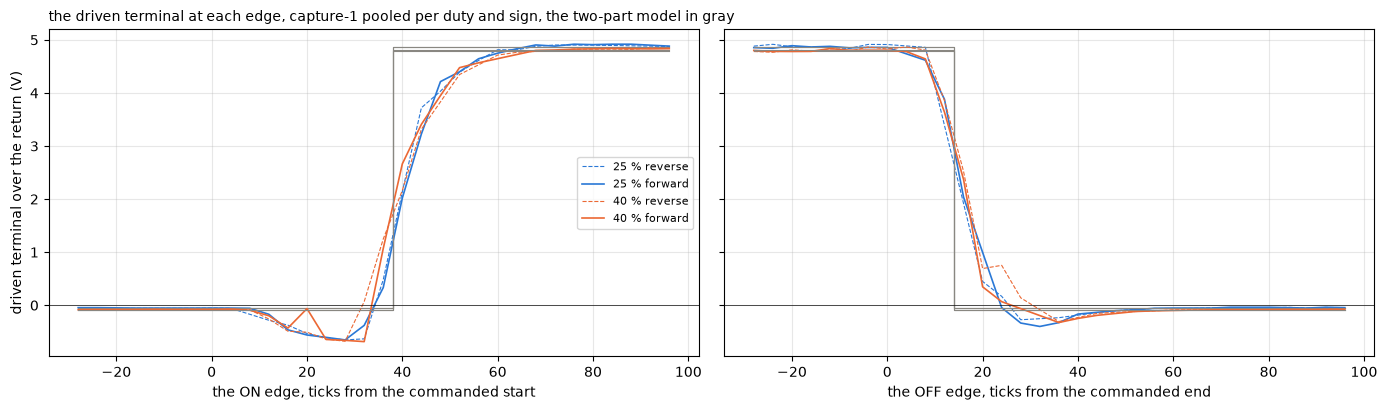

capture-1, 25 % reverse, the edges hold -28.9 V ticks beyond the two-part mean, -12.1 mV on each period's volts, -1.0 % of duty x rail
capture-1, 25 % forward, the edges hold -29.5 V ticks beyond the two-part mean, -12.3 mV on each period's volts, -1.0 % of duty x rail
capture-1, 40 % reverse, the edges hold -13.5 V ticks beyond the two-part mean, -5.6 mV on each period's volts, -0.3 % of duty x rail
capture-1, 40 % forward, the edges hold -20.8 V ticks beyond the two-part mean, -8.7 mV on each period's volts, -0.4 % of duty x rail
reversal-1, 25 % reverse, the edges hold -11.7 V ticks beyond the two-part mean, -4.9 mV on each period's volts, -0.4 % of duty x rail
reversal-1, 25 % forward, the edges hold -28.2 V ticks beyond the two-part mean, -11.8 mV on each period's volts, -0.9 % of duty x rail


In [6]:
def edge_samples(grp):
    # the driven terminal in volts around both commanded edges, pooled over every full period of every burst in grp, in ticks
    # from each edge, and the two-part model's window and brake levels for the same samples
    on, off, lv_on, lv_off = [], [], [], []
    for _, e in grp.iterrows():
        s, m, half = samples(e["df"])
        s = s[(s["n"] >= 0) & s["full"]]
        drv, ret = ("ta", "tb") if e["sign"] > 0 else ("tb", "ta")      # the driven tap, and the return tap the low side holds at ground
        r = s[s["stream"] == ret]["code"].median()
        d = s[s["stream"] == drv]
        v = ((d["code"] - r - TERM_OFF) / COUNTS_PER_V).to_numpy()       # the terminal difference at each driven-tap sample
        tc = d["tc"].to_numpy()
        on.append(np.c_[tc + half, v]); off.append(np.c_[tc - half, v])   # ticks from the commanded start and from the commanded end
        lv_on.append(np.median(v[(tc >= -half + SETTLE) & (tc <= half)]))
        lv_off.append(np.median(v[(tc >= half + OFF_LAG + SETTLE - ON_LAG) | (tc <= -half - 10)]))
    return np.vstack(on), np.vstack(off), float(np.median(lv_on)), float(np.median(lv_off))

ZONE, W = (-30, 100), 4                                                # the zone around each commanded edge in ticks, and the profile's bin
def edge_profiles(grp):
    # the pooled profile of each edge with the two-part model's levels beside it, and the volt-ticks both edges hold beyond the model
    on, off, v_on, v_off = edge_samples(grp)
    curves = []
    for pts, model in ((on, lambda x: np.where(x < TAP_ON_LAG, v_off, v_on)), (off, lambda x: np.where(x < OFF_LAG, v_on, v_off))):
        pts = pts[(pts[:, 0] >= ZONE[0]) & (pts[:, 0] < ZONE[1])]       # only the zone, so no sample lands in an end bin from outside it
        x, p = bu.profile(pts[:, 0], pts[:, 1], ZONE[0], ZONE[1] - W, W)  # the median per bin, one curve per edge
        curves.append((x, p, model(x)))
    return sum(((p - mdl) * W).sum() for x, p, mdl in curves), curves

EDGES, PROF = {}, {}
# pooled per run, duty and sign; the excluded group stays out of the pool as it stays out of every fit
for (name, pct, sgn), grp in B[~B["excluded"]].groupby(["set", "pct", "sign"]):
    EDGES[(name, pct, sgn)], PROF[(name, pct, sgn)] = edge_profiles(grp)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for (name, pct, sgn), curves in PROF.items():
    if name != "capture-1":
        continue
    for a, (x, p, mdl) in zip(ax, curves):
        a.plot(x, p, color=COLOR[pct], lw=1.2 if sgn > 0 else 0.8, ls="-" if sgn > 0 else "--",
               label=f"{pct} % {'forward' if sgn > 0 else 'reverse'}")
        a.plot(x, mdl, "-", color=MUTED, lw=0.8, drawstyle="steps-mid")
for a, title in zip(ax, ("the ON edge, ticks from the commanded start", "the OFF edge, ticks from the commanded end")):
    a.axhline(0, color=INK, lw=0.5); a.grid(alpha=0.3); a.set_xlabel(title)
ax[0].set_ylabel("driven terminal over the return (V)"); ax[0].legend(fontsize=8, loc="center right")
ax[0].set_title("the driven terminal at each edge, capture-1 pooled per duty and sign, the two-part model in gray", loc="left", fontsize=10)
plt.tight_layout(); plt.show()
for (name, pct, sgn), e_vt in EDGES.items():
    print(f"{name}, {pct} % {'forward' if sgn > 0 else 'reverse'}, the edges hold {e_vt:+.1f} V ticks beyond the two-part mean, "
          f"{e_vt / PERIOD * 1e3:+.1f} mV on each period's volts, {e_vt / PERIOD / (pct / 100 * B['rail_v'].mean()) * 100:+.1f} % of duty x rail")

At the ON edge the driven terminal drops to about 0.6 V under ground from some 8 to 33 ticks after the commanded start, half a microsecond, close to the 0.5 us dead time of the bridge's datasheet, before it rises to the rail. At the OFF edge it falls through zero and dips a few tenths of a volt under it before it settles at the brake level. Both dips are what a current carried through a body diode looks like, with high confidence. Together the two edges take 5 to 12 mV off each period's volts, at most about a percent of what the period applies, and the fit below includes them. The reversal run's own pools land in the same range.

### The periods of one burst

The fit on the second burst of the forward 25 % and 40 % groups at hole 0. The top row is the window current per period with the fit run forward from the first period's current through the measured volts, the bottom row the volts each period applied.

25 %, 9 periods, 5 to 6 settled shunt samples in a window. Applied volts 1.153 V in the first period and 1.090 V in the last against 1.251 V of duty x rail. Inside the window 4.939 to 4.812 V, between windows -0.023 to -0.066 V. The shunt between windows -0.6 mA. The fit run forward misses by 1.8 mA at most
40 %, 9 periods, 8 to 9 settled shunt samples in a window. Applied volts 1.887 V in the first period and 1.771 V in the last against 1.998 V of duty x rail. Inside the window 4.921 to 4.720 V, between windows -0.035 to -0.096 V. The shunt between windows +0.6 mA. The fit run forward misses by 2.1 mA at most


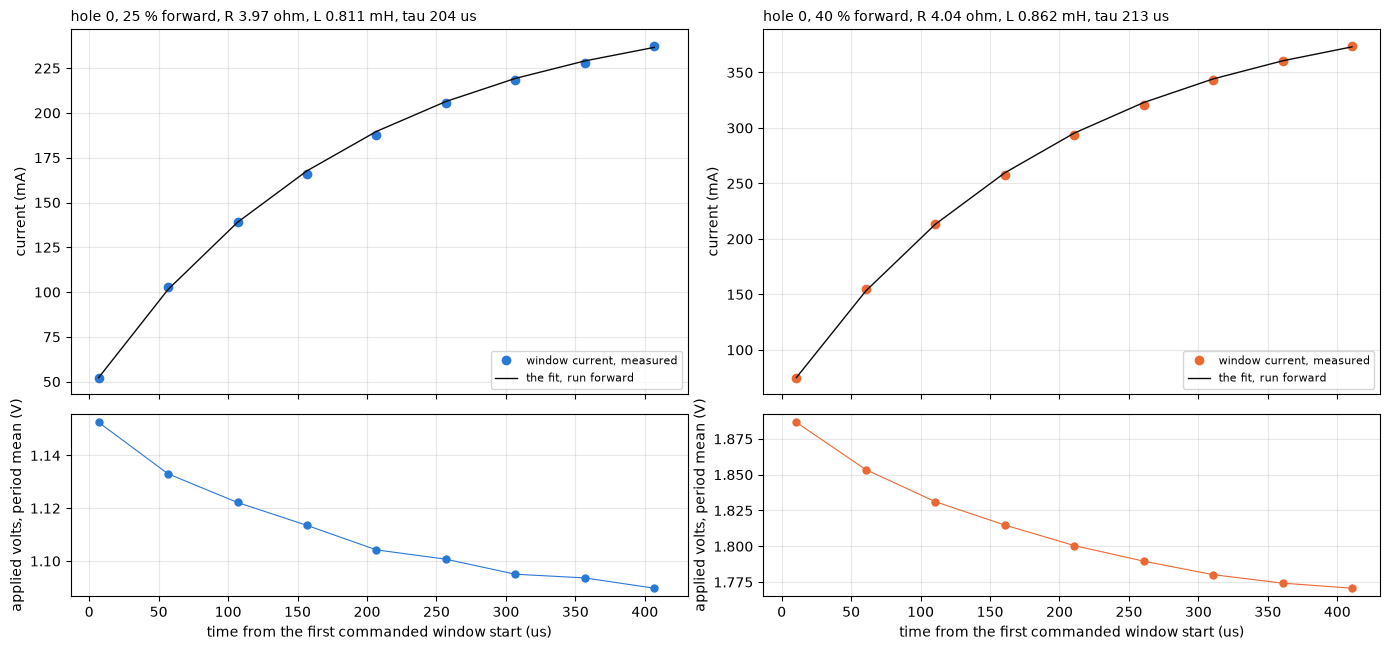

In [7]:
def fit(P, pairs=None):
    # R and L by least squares over the first `pairs` period pairs (all of them by default), each divided by the window's scale
    i, v = P["i_a"].to_numpy(), P["v_v"].to_numpy()
    p = len(i) - 1 if pairs is None else pairs
    di, im = i[1:p + 1] - i[:p], (i[1:p + 1] + i[:p]) / 2                 # the change over each pair and the pair's mean current
    (r, l), *_ = np.linalg.lstsq(np.c_[im, di / T_S], v[:p], rcond=None)  # V_n = R i_mean + L di / T
    return {"r_ohm": r / K, "l_mh": l / K * 1e3, "tau_us": l / r * 1e6, "pairs": p}

def run(P, f):
    # the current the fit predicts, stepped forward from the first period's measurement through each period's measured volts
    r, l = f["r_ohm"] * K, f["l_mh"] * K * 1e-3                          # back to the window's own scale, the one the volts are in
    i = [P["i_a"].iloc[0]]
    for v in P["v_v"].iloc[:-1]:
        i.append((v + i[-1] * (l / T_S - r / 2)) / (l / T_S + r / 2))
    return np.array(i)

fig, ax = plt.subplots(2, 2, figsize=(14, 6.6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for col, group in enumerate(("g1-fwd-25", "g2-fwd-40")):
    e = one(0, group)
    pct = e["pct"]
    P = periods(e["df"], e["sign"], EDGES[(e["set"], pct, e["sign"])])
    f = fit(P)
    ax[0, col].plot(P["t_us"], P["i_a"] * 1e3, "o", color=COLOR[pct], ms=6, label="window current, measured")
    pred = run(P, f)
    ax[0, col].plot(P["t_us"], pred * 1e3, "-", color=INK, lw=1, label="the fit, run forward")
    ax[0, col].set_ylabel("current (mA)"); ax[0, col].legend(fontsize=8, loc="lower right"); ax[0, col].grid(alpha=0.3)
    ax[0, col].set_title(f"hole 0, {pct} % forward, R {f['r_ohm']:.2f} ohm, L {f['l_mh']:.3f} mH, tau {f['tau_us']:.0f} us", loc="left", fontsize=10)
    ax[1, col].plot(P["t_us"], P["v_v"], "o-", color=COLOR[pct], ms=5, lw=0.8)
    ax[1, col].set_ylabel("applied volts, period mean (V)"); ax[1, col].set_xlabel("time from the first commanded window start (us)")
    ax[1, col].grid(alpha=0.3)
    print(f"{pct} %, {len(P)} periods, {P['on_n'].min()} to {P['on_n'].max()} settled shunt samples in a window. Applied volts "
          f"{P['v_v'].iloc[0]:.3f} V in the first period and {P['v_v'].iloc[-1]:.3f} V in the last against {pct / 100 * e['rail_v']:.3f} V of duty x rail. "
          f"Inside the window {P['v_on_v'].iloc[0]:.3f} to {P['v_on_v'].iloc[-1]:.3f} V, between windows {P['v_off_v'].iloc[0]:+.3f} to {P['v_off_v'].iloc[-1]:+.3f} V. "
          f"The shunt between windows {P['i_off_a'].mean() * 1e3:+.1f} mA. The fit run forward misses by {np.abs(pred - P['i_a']).max() * 1e3:.1f} mA at most")
plt.tight_layout(); plt.show()

Run forward from the first period through the measured volts, the fit follows the measured current at both duties to within the printed miss, so over a single burst the series model draws the rise well. The applied volts fall smoothly through the burst. Inside the window the terminals lose 0.13 V at 25 % and 0.20 V at 40 % from the first period to the last, and between windows the brake level sinks from 23 to 66 mV under zero at 25 % and from 35 to 96 mV at 40 %. Both are the bridge's switches and the supply carrying the current, and they are why the fit takes the volts period by period. Whether the same $R$ and $L$ hold over every stretch of the burst is a different question, and a later section asks it.

### Every burst

The same fit over every burst of both runs, the excluded group included so it can be looked at. One check comes before anything is summarized. The rested group repeats the step of the group before it after 20 s with nothing changed, so at every hole its median should land on the median of the group before it. Below, the rested group's median over the median of the group before it, all bursts of each, at each hole, for $L$, $\tau$, $R$ and the last window current.

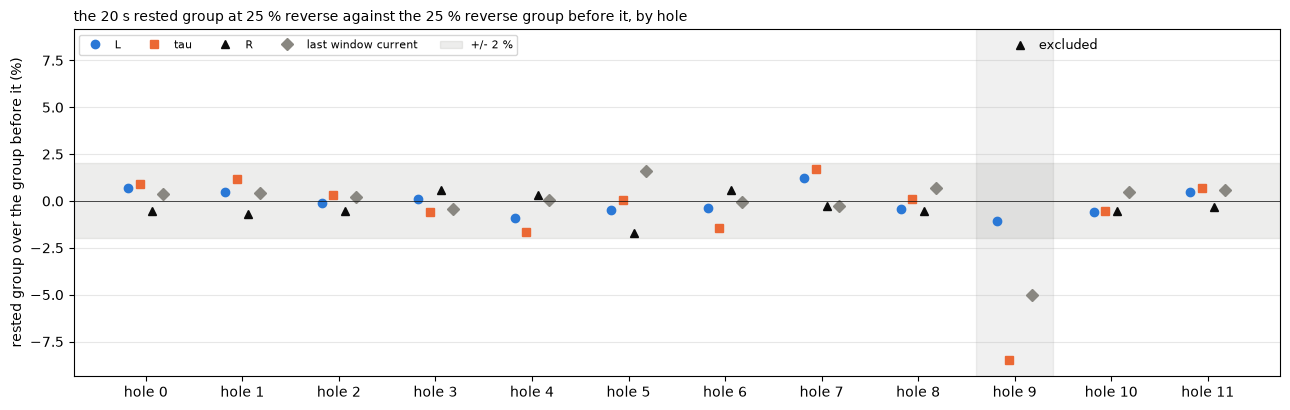

hole 9, L -1.0 %, tau -8.5 %, R +8.3 %, last window current -5.0 %. The other 11 holes, largest move 1.7 %, L -0.9 to +1.2, tau -1.7 to +1.7, R -1.7 to +0.6, last window current -0.4 to +1.6
last window current 25 % 214 to 240 mA, 40 % 343 to 378 mA
fitted 306 bursts, 3 of them excluded. The summaries read 214 capture-1 bursts, the first of each group left out


In [8]:
QTY = {"l_mh": "L", "tau_us": "tau", "r_ohm": "R", "l_ripple_mh": "ripple L"}   # the four quantities each burst is read for
PER, rows = {}, []
for idx, e in B.iterrows():
    P = periods(e["df"], e["sign"], EDGES[(e["set"], e["pct"], e["sign"])])   # the excluded group too, read with its run's pooled edges
    PER[idx] = P                                                           # kept, so the sections below reuse the periods
    f = fit(P)
    s_ = P["slope_a_per_s"].to_numpy()
    l_rip = (P["v_on_v"].to_numpy() - f["r_ohm"] * K * P["i_a"].to_numpy()) / s_ / K * 1e3   # the window's own L per period, mH
    rows.append({"idx": idx, **e[["set", "hole", "group", "k", "pct", "sign", "first", "excluded"]].to_dict(), **f, "i_last_a": P["i_a"].iloc[-1],
                 "v_mean_v": P["v_v"].mean(), "v_drop_pct": (P["v_v"].iloc[-1] / P["v_v"].iloc[0] - 1) * 100,
                 "l_ripple_mh": float(np.median(l_rip[-3:])), "l_ripple_first_mh": float(np.median(l_rip[:3])),
                 "early_r_ohm": fit(P, 3)["r_ohm"], "early_l_mh": fit(P, 3)["l_mh"]})
FITS = pd.DataFrame(rows)
OTHERS = FITS[~FITS["first"] & ~FITS["excluded"]]                      # every burst but the first of its group, the excluded group out
C2 = OTHERS[OTHERS["set"] == "capture-1"]                              # the summaries of L, tau and R read these

# the rested group against the group before it, every burst of each, so the check does not lean on the first-burst question
cols = ["l_mh", "tau_us", "r_ohm", "i_last_a"]
c2 = FITS[FITS["set"] == "capture-1"]
g4 = c2[c2["group"] == "g4-rev-25"].groupby("hole")[cols].median()
g5 = c2[c2["group"] == "g5-rev-25-rested"].groupby("hole")[cols].median()
REST = (g5 / g4 - 1) * 100
fig, ax = plt.subplots(figsize=(13, 4.2))
for j, (c, lab, mk) in enumerate(zip(cols, ("L", "tau", "R", "last window current"), ("o", "s", "^", "D"))):
    ax.plot(np.array(HOLES) + (j - 1.5) * 0.12, REST[c], mk, ms=6, color=(BLUE, ORANGE, INK, MUTED)[j], ls="none", label=lab)
ax.axhspan(-2, 2, color=MUTED, alpha=0.15, label="+/- 2 %")
ax.annotate("excluded", (EXCLUDED[1], REST.loc[EXCLUDED[1], "r_ohm"]), xytext=(EXCLUDED[1] + 0.25, REST.loc[EXCLUDED[1], "r_ohm"]), fontsize=9, va="center")
ax.axvspan(EXCLUDED[1] - 0.4, EXCLUDED[1] + 0.4, color=INK, alpha=0.06)
ax.axhline(0, color=INK, lw=0.5); ax.set_xticks(HOLES, [f"hole {h}" for h in HOLES]); ax.grid(alpha=0.3, axis="y")
ax.set_ylabel("rested group over the group before it (%)"); ax.legend(fontsize=8, ncol=5, loc="upper left")
ax.set_title("the 20 s rested group at 25 % reverse against the 25 % reverse group before it, by hole", loc="left", fontsize=10)
plt.tight_layout(); plt.show()
ok = REST.drop(index=EXCLUDED[1])
LAB = {**QTY, "i_last_a": "last window current"}
print(f"hole {EXCLUDED[1]}, " + ", ".join(f"{LAB[c]} {REST.loc[EXCLUDED[1], c]:+.1f} %" for c in cols)
      + f". The other {len(ok)} holes, largest move {ok.abs().max().max():.1f} %, " + ", ".join(f"{LAB[c]} {ok[c].min():+.1f} to {ok[c].max():+.1f}" for c in cols))
print("last window current " + ", ".join(f"{p} % {g.min() * 1e3:.0f} to {g.max() * 1e3:.0f} mA" for p, g in C2.groupby("pct")["i_last_a"]))
print(f"fitted {len(FITS)} bursts, {FITS['excluded'].sum()} of them excluded. The summaries read {len(C2)} capture-1 bursts, the first of each group left out")

The data agree with the bench note. At eleven holes the rested group lands within 1.7 % of the group before it on all four quantities. At hole 9 it reads $R$ 8.3 % high, $\tau$ 8.5 % short and the last window current 5.0 % low, while $L$ moves 1.0 %. That group is left out of every number below, and the figures that follow draw it as excluded.

### The first burst of each group

Each group's first burst over the median of the group's other bursts, in percent, at every hole, by the change that came before the group. The four panels are $L$ and $\tau$ from the fit over the whole burst, $R$ from the same fit, and $L_\mathrm{ripple}$ from inside the windows. A dot is one hole, the black bar the median over the holes. Hole 0's first group is drawn open, since it follows the power-up and the sign before it is not in this dataset. The excluded group is drawn as a gray cross and stays out of the median.

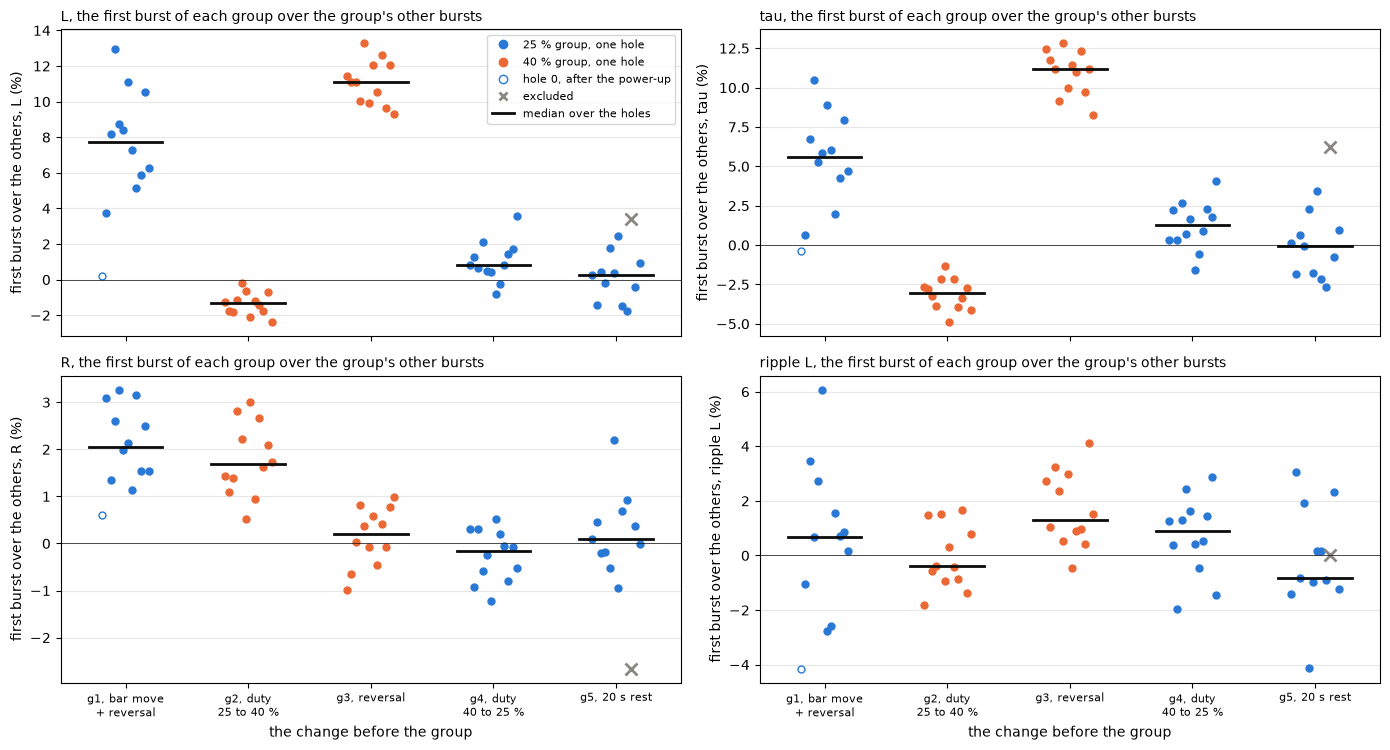

g1-fwd-25 (bar move + reversal), 12 holes, L +7.7 % (+0.2 to +12.9), tau +5.6 % (-0.4 to +10.5), R +2.1 % (+0.6 to +3.3), ripple L +0.7 % (-4.1 to +6.1)
g2-fwd-40 (duty 25 to 40 %), 12 holes, L -1.3 % (-2.4 to -0.2), tau -3.0 % (-4.9 to -1.3), R +1.7 % (+0.5 to +3.0), ripple L -0.4 % (-1.8 to +1.7)
g3-rev-40 (reversal), 12 holes, L +11.1 % (+9.3 to +13.3), tau +11.2 % (+8.2 to +12.8), R +0.2 % (-1.0 to +1.0), ripple L +1.3 % (-0.5 to +4.1)
g4-rev-25 (duty 40 to 25 %), 12 holes, L +0.8 % (-0.8 to +3.6), tau +1.3 % (-1.6 to +4.1), R -0.2 % (-1.2 to +0.5), ripple L +0.9 % (-2.0 to +2.9)
g5-rev-25-rested (20 s rest), 11 holes, L +0.2 % (-1.8 to +2.4), tau -0.0 % (-2.7 to +3.4), R +0.1 % (-0.9 to +2.2), ripple L -0.8 % (-4.1 to +3.0)
g1 without hole 0, 11 holes, L +8.2 % (+3.7 to +12.9). Hole 0's g1, L +0.2 %


In [9]:
def jumps(F):
    # each group's first burst over the median of the same group's other bursts, in percent, for the four quantities
    out = []
    for (name, h, g), grp in F.groupby(["set", "hole", "group"], sort=False):
        first, rest = grp[grp["first"]].iloc[0], grp[~grp["first"]]
        out.append({"set": name, "hole": h, "group": g, "pct": first["pct"], "excluded": bool(first["excluded"]),
                    **{c: (first[c] / rest[c].median() - 1) * 100 for c in QTY}})
    return pd.DataFrame(out)

J = jumps(FITS)
JC = J[(J["set"] == "capture-1")]
JK = JC[~JC["excluded"]]                                                 # the medians below leave the excluded group out
fig, ax = plt.subplots(2, 2, figsize=(14, 7.6), sharex=True)
for a, (c, lab) in zip(ax.flat, QTY.items()):
    for x, g in enumerate(CHANGE):
        rows_ = JC[JC["group"] == g]
        dx = (rows_["hole"].to_numpy() - 5.5) * 0.035                   # spread the twelve holes across the slot, hole 0 on the left
        col = COLOR[rows_["pct"].iloc[0]]
        for (_, r), d in zip(rows_.iterrows(), dx):
            if r["excluded"]:
                a.plot(x + d, r[c], "x", color=MUTED, ms=8, mew=2)
            else:
                a.plot(x + d, r[c], "o", ms=5, color=col, mfc="none" if (r["hole"] == HOLES[0] and g == "g1-fwd-25") else col)
        med = JK[JK["group"] == g][c].median()
        a.plot([x - 0.3, x + 0.3], [med, med], color=INK, lw=2)
    a.axhline(0, color=INK, lw=0.5); a.grid(alpha=0.3, axis="y")
    a.set_ylabel(f"first burst over the others, {lab} (%)")
    a.set_title(f"{lab}, the first burst of each group over the group's other bursts", loc="left", fontsize=10)
for a in ax[1]:
    a.set_xticks(range(len(CHANGE)), [f"{g[:2]}, {CHANGE[g]}" for g in CHANGE], fontsize=8)
    a.set_xlabel("the change before the group")
ax[0, 0].legend(handles=[plt.Line2D([], [], ls="none", marker="o", color=BLUE, label="25 % group, one hole"),
                         plt.Line2D([], [], ls="none", marker="o", color=ORANGE, label="40 % group, one hole"),
                         plt.Line2D([], [], ls="none", marker="o", color=BLUE, mfc="none", label="hole 0, after the power-up"),
                         plt.Line2D([], [], ls="none", marker="x", color=MUTED, mew=2, label="excluded"),
                         plt.Line2D([], [], color=INK, lw=2, label="median over the holes")], fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()
for g in CHANGE:
    r_ = JK[JK["group"] == g]
    print(f"{g} ({CHANGE[g].replace(chr(10), ' ')}), {len(r_)} holes, "
          + ", ".join(f"{lab} {r_[c].median():+.1f} % ({r_[c].min():+.1f} to {r_[c].max():+.1f})" for c, lab in QTY.items()))
r_ = JK[(JK["group"] == "g1-fwd-25") & (JK["hole"] != HOLES[0])]
print(f"g1 without hole 0, {len(r_)} holes, L {r_['l_mh'].median():+.1f} % ({r_['l_mh'].min():+.1f} to {r_['l_mh'].max():+.1f}). Hole 0's g1, L "
      f"{JK[(JK['group'] == 'g1-fwd-25') & (JK['hole'] == HOLES[0])]['l_mh'].iloc[0]:+.1f} %")

The reversal with the duty kept, g3, reads the first burst's $L$ 11.1 % over the group's other bursts in the median, 9.3 to 13.3 % across the twelve holes, and its $\tau$ 11.2 % long. Its $R$ moves 0.2 % and its $L_\mathrm{ripple}$ 1.3 %, inside the scatter every group shows. The changes with the sign kept do not do that. After the duty change from 25 to 40 %, g2, the first burst reads $L$ 1.3 % low, with $R$ 1.7 % high and $\tau$ 3.0 % short at every hole, a small shift of another shape. After the change from 40 to 25 %, g4, it reads $L$ 0.8 % high, and after the 20 s rest with nothing changed, g5, 0.2 %.

The first group of a hole, g1, follows the bar move, a 20 s rest and the last hole's reverse group. It reads $L$ 7.7 % high in the median, 3.7 to 12.9 % at holes 1 to 11, and its $R$ about 2 % high. Hole 0's g1 follows the power-up with an unknown sign before it and reads 0.2 %.

So the jump follows a change of sign, and a change of duty or a rest alone moves $L$ by about a percent or less, with high confidence on these twelve holes. With a bar move and a rest between the reversal and the burst the jump is smaller and more scattered, so a bar move does not reliably clear it. The jump sits in the slow part of the rise, since the window's own $L$ does not move with it.

### The reversal at one hole after a rest

The reversal run at hole 11, the same quantities, each group's first burst over the median of its other four, in the order the groups ran. The first group keeps the sign of the main run's last group and follows no reversal. Each later group reverses the sign after the rest its label names.

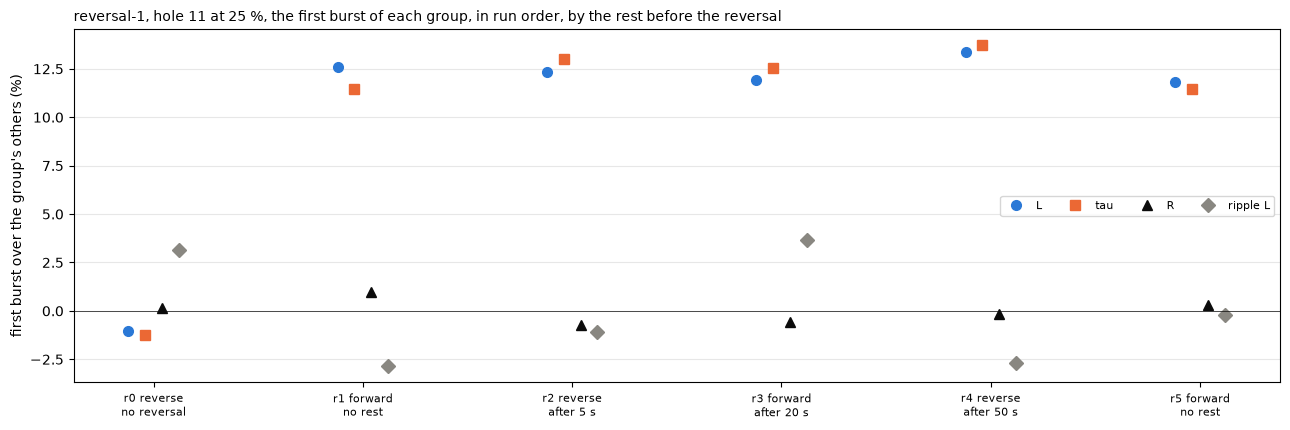

r0-rev-25, L -1.0 %, tau -1.3 %, R +0.2 %, ripple L +3.1 %
r1-fwd-25, L +12.6 %, tau +11.4 %, R +1.0 %, ripple L -2.9 %
r2-rev-25-5s, L +12.4 %, tau +13.0 %, R -0.7 %, ripple L -1.1 %
r3-fwd-25-20s, L +11.9 %, tau +12.6 %, R -0.6 %, ripple L +3.6 %
r4-rev-25-50s, L +13.4 %, tau +13.7 %, R -0.1 %, ripple L -2.7 %
r5-fwd-25, L +11.8 %, tau +11.5 %, R +0.3 %, ripple L -0.2 %


In [10]:
JR = J[J["set"] == "reversal-1"].set_index("group").loc[list(RUN)]
fig, ax = plt.subplots(figsize=(13, 4.4))
for j, ((c, lab), mk, col) in enumerate(zip(QTY.items(), ("o", "s", "^", "D"), (BLUE, ORANGE, INK, MUTED))):
    ax.plot(np.arange(len(RUN)) + (j - 1.5) * 0.08, JR[c], mk, ms=7, color=col, ls="none", label=lab)
ax.axhline(0, color=INK, lw=0.5); ax.grid(alpha=0.3, axis="y")
ax.set_xticks(range(len(RUN)), list(RUN.values()), fontsize=8)
ax.set_ylabel("first burst over the group's others (%)"); ax.legend(fontsize=8, ncol=4, loc="center right")
ax.set_title("reversal-1, hole 11 at 25 %, the first burst of each group, in run order, by the rest before the reversal", loc="left", fontsize=10)
plt.tight_layout(); plt.show()
for g, r in JR.iterrows():
    print(f"{g}, " + ", ".join(f"{lab} {r[c]:+.1f} %" for c, lab in QTY.items()))

With nothing moved at hole 11, the group that keeps the sign reads its first burst's $L$ 1.0 % low. Every group after a reversal reads it 11.8 to 13.4 % high and $\tau$ 11.4 to 13.7 % long, after no rest, 5 s, 20 s and 50 s alike, and the last no-rest reversal repeats the first within a percent. $R$ stays within 1 % and $L_\mathrm{ripple}$ within 3.6 %, the scatter $L_\mathrm{ripple}$ shows in every group. So a rest of up to 50 s does not clear the jump and the jump does not drift through the run, with high confidence at this hole. At the same hole, capture-1's g1, the reversal after the bar move into the hole, read 6.3 %, about half of what a reversal reads here with nothing moved.

### What the first burst's extra volts amount to

The first burst after a reversal reads a higher $L$ from the same currents, so its periods applied more volt-seconds than the group's other bursts needed for the same rise. Below, every burst is run against the median $R$ and $L$ of its group's other bursts, and the volts each period pair applied beyond $R\,i + L\,di/dt$ are what is left over. On the left the leftover per pair, the median over the holes of each group's first burst, against the spread of every other burst. On the right the leftover summed over the burst into volt-seconds, one dot per hole. The right-hand scale reads the same volt-seconds as the angle the rotor would have to turn through during the burst for its back-EMF to supply them, with $K_e$, the back-EMF constant, from bemf-coast.

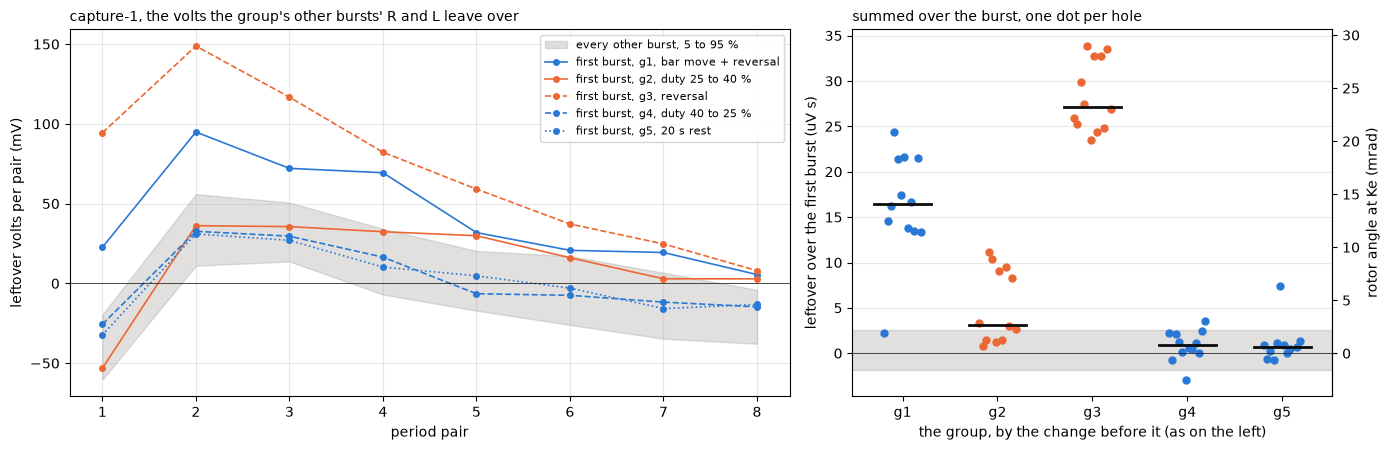

capture-1 g1-fwd-25, first burst +16.4 uV s (+2.2 to +24.4), +8.8 % of L i at the last period, a rotor angle of +14.1 mrad (+0.81 degrees)
capture-1 g2-fwd-40, first burst +3.1 uV s (+0.8 to +11.1), +0.9 % of L i at the last period, a rotor angle of +2.7 mrad (+0.15 degrees)
capture-1 g3-rev-40, first burst +27.2 uV s (+23.5 to +33.8), +8.9 % of L i at the last period, a rotor angle of +23.3 mrad (+1.33 degrees)
capture-1 g4-rev-25, first burst +0.9 uV s (-2.9 to +3.6), +0.5 % of L i at the last period, a rotor angle of +0.7 mrad (+0.04 degrees)
capture-1 g5-rev-25-rested, first burst +0.7 uV s (-0.7 to +7.4), +0.4 % of L i at the last period, a rotor angle of +0.6 mrad (+0.04 degrees)
reversal-1 r0-rev-25, first burst -0.9 uV s (-0.9 to -0.9), -0.5 % of L i at the last period, a rotor angle of -0.7 mrad (-0.04 degrees)
reversal-1 r1-fwd-25, first burst +20.4 uV s (+20.4 to +20.4), +11.3 % of L i at the last period, a rotor angle of +17.5 mrad (+1.00 degrees)
reversal-1 r2-rev-25-5s, f

In [11]:
rows = []
for (name, h, g), grp in FITS[~FITS["excluded"]].groupby(["set", "hole", "group"], sort=False):
    rest = grp[~grp["first"]]
    r, l = rest["r_ohm"].median() * K, rest["l_mh"].median() * K * 1e-3   # the others' R and L, back on the window's own scale
    for _, f in grp.iterrows():
        P = PER[f["idx"]]
        i, v = P["i_a"].to_numpy(), P["v_v"].to_numpy()
        e_ = v[:-1] - r * (i[1:] + i[:-1]) / 2 - l * np.diff(i) / T_S     # volts per pair the others' R and L leave unexplained
        rows.append({"set": name, "hole": h, "group": g, "first": f["first"], "pct": f["pct"], "e_mv": e_ * 1e3,
                     "flux_uvs": e_.sum() * T_S * 1e6,                     # the leftover volt-seconds over the burst
                     "li_uvs": l * i[-1] * 1e6})                           # the flux the others' L holds at the burst's last current
EMF = pd.DataFrame(rows)
EMF["share_pct"] = EMF["flux_uvs"] / EMF["li_uvs"] * 100
EC = EMF[EMF["set"] == "capture-1"]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [3, 2]})
E_o = np.vstack(EC[~EC["first"]]["e_mv"].to_numpy())
pairs = np.arange(1, E_o.shape[1] + 1)
ax[0].fill_between(pairs, np.quantile(E_o, 0.05, axis=0), np.quantile(E_o, 0.95, axis=0), color=MUTED, alpha=0.25, label="every other burst, 5 to 95 %")
for g, ls in zip(CHANGE, ("-", "-", "--", "--", ":")):
    E_f = np.vstack(EC[EC["first"] & (EC["group"] == g)]["e_mv"].to_numpy())
    ax[0].plot(pairs, np.median(E_f, axis=0), ls, marker="o", ms=4, lw=1.2, color=COLOR[int(g.split("-")[2])],
               label=f"first burst, {g[:2]}, {CHANGE[g].replace(chr(10), ' ')}")
ax[0].axhline(0, color=INK, lw=0.5); ax[0].grid(alpha=0.3); ax[0].legend(fontsize=8, loc="upper right")
ax[0].set_xlabel("period pair"); ax[0].set_ylabel("leftover volts per pair (mV)")
ax[0].set_title("capture-1, the volts the group's other bursts' R and L leave over", loc="left", fontsize=10)
for x, g in enumerate(CHANGE):
    r_ = EC[EC["first"] & (EC["group"] == g)]
    ax[1].plot(x + (r_["hole"].to_numpy() - 5.5) * 0.035, r_["flux_uvs"], "o", ms=5, color=COLOR[r_["pct"].iloc[0]])
    ax[1].plot([x - 0.3, x + 0.3], [r_["flux_uvs"].median()] * 2, color=INK, lw=2)
o = EC[~EC["first"]]["flux_uvs"]
ax[1].axhspan(o.quantile(0.05), o.quantile(0.95), color=MUTED, alpha=0.25)
ax[1].axhline(0, color=INK, lw=0.5); ax[1].grid(alpha=0.3, axis="y")
ax[1].set_xticks(range(len(CHANGE)), [g[:2] for g in CHANGE]); ax[1].set_xlabel("the group, by the change before it (as on the left)")
ax[1].set_ylabel("leftover over the first burst (uV s)")
ax[1].set_title("summed over the burst, one dot per hole", loc="left", fontsize=10)
sec = ax[1].secondary_yaxis("right", functions=(lambda f: f * 1e-6 / KE * 1e3, lambda th: th * 1e-3 * KE * 1e6))
sec.set_ylabel("rotor angle at Ke (mrad)")
plt.tight_layout(); plt.show()
for name, E in EMF.groupby("set", sort=False):
    for g, r_ in E[E["first"]].groupby("group", sort=False):
        print(f"{name} {g}, first burst {r_['flux_uvs'].median():+.1f} uV s ({r_['flux_uvs'].min():+.1f} to {r_['flux_uvs'].max():+.1f}), "
              f"{r_['share_pct'].median():+.1f} % of L i at the last period, a rotor angle of {r_['flux_uvs'].median() * 1e-6 / KE * 1e3:+.1f} mrad "
              f"({np.degrees(r_['flux_uvs'].median() * 1e-6 / KE):+.2f} degrees)")
print("first bursts above the other bursts' 95 % point, " + ", ".join(f"{g[:2]} {(EF_[EF_['group'] == g]['flux_uvs'] > o.quantile(0.95)).sum()} of {(EF_['group'] == g).sum()}" for g in CHANGE for EF_ in [EC[EC["first"]]]))
print(f"every other burst of capture-1 {o.median():+.1f} uV s, 5 to 95 % {o.quantile(0.05):+.1f} to {o.quantile(0.95):+.1f}")

Every other burst leaves a shape of its own, negative on the first pair, positive over the next three and negative again at the end, within about 60 mV per pair. That is the constant-parameter fit not following the rise, which the section on the time scale takes up, and every burst carries it, so it drops out of the comparison. The first burst after a reversal leaves more on top of that shape, most of it over pairs 1 to 4, the first 200 us, and close to nothing by pair 8. Summed over the burst that is 27 uV s after the reversal with the duty kept, 23 to 34 uV s across the holes and 8.9 % of the flux $L\,i$ the others' $L$ holds at the burst's last current. After the bar move it is 16 uV s, and after reversal-1's five reversals at 25 % it is 16 to 20 uV s. The other changes leave 3 uV s or less in the median. After the 25 to 40 % duty change the first burst still sits above the other bursts' spread at 8 of the 12 holes, by up to 11 uV s, in the shape the small shift of $R$ and $\tau$ above gives it, a deficit on the first pair and a surplus after.

Two readings fit the jump. The leading one is magnetic history in the iron, with moderate confidence. The last current leaves the rotor and stator iron with a remanent flux of its own sign. The first burst of the other sign drives the iron back through that remanence before its flux builds as it does on the next burst, and the extra volt-seconds read as a higher $L$ on the slow time scale of the rise. The window's own $L$ reads small loops around the present operating point and stays where it was, which fits the same reading. The alternative this data does not exclude is the rotor turning inside the rig's play. A reversal flips the torque, a rotor held with play would move through the play on the first burst of the new sign, and a turning rotor makes a back-EMF against the drive. At $K_e$ from bemf-coast the 27 uV s equal 23 mrad of rotor travel, 1.3 degrees, during the half millisecond of the burst, and the bar-move and reversal-1 values equal 13 to 18 mrad. The leftover after a reversal at 40 % is about 1.5 times the leftover after one at 25 %, close to the ratio of the two currents. Remanence predicts that, and so does a rotor held by a springy compliance rather than a fixed play, so the ratio does not separate the two. The next section varies the old step to tell them apart.

### The old sign's step

`steps-1` varies the step before the reversal and keeps the step after it. It ran at hole 11 with the bar left where reversal-1 had it, about 70 minutes later, thirteen groups of five bursts a little over 2 s apart with no rest between them. Every forward group is the same 25 % step, and each one follows a reverse group at 10, 25 or 40 %. The three old steps run once in rising order and once in falling order, so a drift through the run does not line up with the old step. The two reverse groups at 25 % follow a forward 25 % group, so they are reversals after 25 % of the other sign. The two reverse groups at 40 % are reversals too, but with a 40 % step after them, so they are printed apart. The first group, `s00`, sets the forward sign, and the sign before it is not in this dataset.

Magnetic history in the iron predicts extra volt-seconds that grow with the old step's flux. Rotor travel inside a fixed play predicts about the same extra once the old step is large enough to push the rotor to its side of the play. The old step is read by its last window current, the median over its five bursts. At 10 % a window holds one or two settled shunt samples, too few for the line `periods` draws, so this current is the plain mean of the last window's settled samples at every duty.

On the left, the first burst's $L$ over its group's other bursts. On the right, its leftover volt-seconds against its group's others' $R$ and $L$, read the way the section above reads them. The dashed line on the right is the most a turning rotor could supply. It is the back-EMF of a rotor that starts from rest one period before the grid and turns freely under the burst's own measured current, with no friction and no stop, and with the smallest inertia rest-resistance's run-ups give. The rotor's angle is then $\theta = (K_t / J) \iint i\,dt\,dt$ and the volt-seconds are $K_e\,\theta$, with $K_t = K_e$ in SI units.

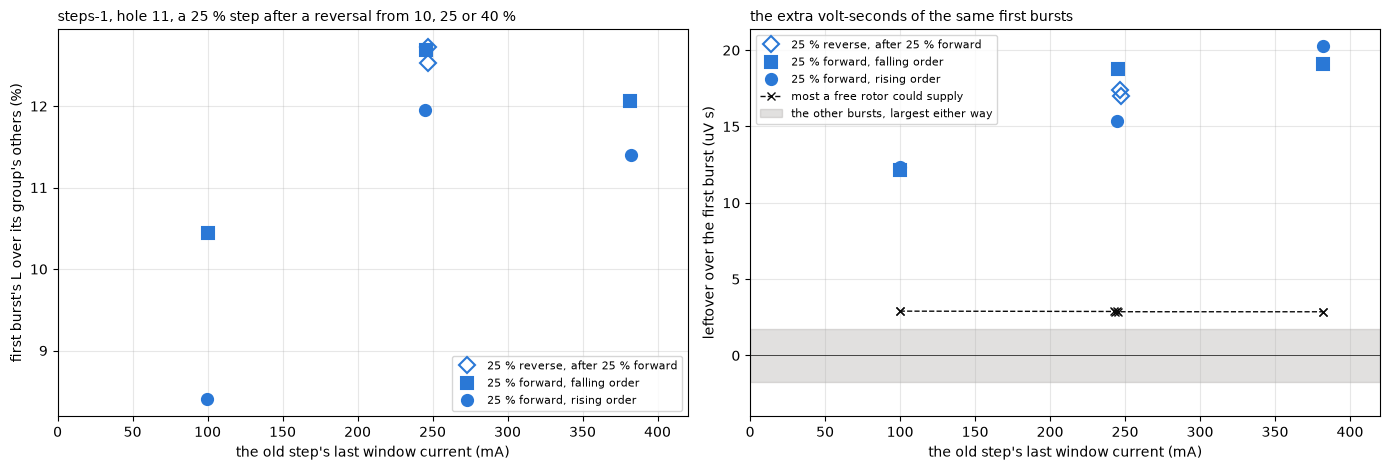

steps-1 began 72 min after reversal-1 ended, groups 2.3 to 2.4 s apart
65 bursts in 13 groups, rail 4.97 to 5.01 V. Window current, plain mean over the line at the window's middle, last four periods, +0.1 to +2.0 %
old step's last window current, 10 % 100 mA, 25 % 244 mA, 40 % 382 mA
s02-fwd-25 (rising), after 10 % reverse at 100 mA, L +8.4 %, tau +8.5 %, R -0.0 %, ripple L +3.8 %, leftover +12.3 uV s against a free-rotor bound of 2.9, late current -2.1 %
s03-rev-25 (rising), after 25 % forward at 243 mA, L +12.5 %, tau +12.8 %, R -0.2 %, ripple L +1.3 %, leftover +17.4 uV s against a free-rotor bound of 2.9, late current -3.0 %
s04-fwd-25 (rising), after 25 % reverse at 245 mA, L +11.9 %, tau +12.8 %, R -0.7 %, ripple L +2.4 %, leftover +15.3 uV s against a free-rotor bound of 2.9, late current -2.5 %
s06-fwd-25 (rising), after 40 % reverse at 382 mA, L +11.4 %, tau +10.1 %, R +1.3 %, ripple L -3.2 %, leftover +20.3 uV s against a free-rotor bound of 2.9, late current -3.7 %
s08-fwd-2

In [12]:
def load_run(root):
    # every burst of a one-hole run in capture order, one row each, with the decay the tool ran from the group's meta.json
    rows = []
    for gdir in sorted(p for p in (root / f"hole-{HOLES[-1]}").iterdir() if p.is_dir()):
        decay = json.loads((gdir / "meta.json").read_text())["decay"]
        for k, df in enumerate(bu.load(gdir)):
            m = bu.meta(df)
            rows.append({"set": root.name, "hole": HOLES[-1], "group": gdir.name, "k": k, "first": k == 0, "decay": decay,
                         "pct": int(round(abs(m["step_q15"]) * 100 / 32768)), "sign": 1 if m["step_q15"] > 0 else -1,
                         "rail_v": float(BOARD.rail_v(m["vbus_raw"])), "df": df})
    return pd.DataFrame(rows)

def window_level(df):
    # each full period's window current as the plain mean of its settled shunt samples, less the in-drive offset, in amps. A 10 %
    # window holds one or two settled samples, too few for the line `periods` draws, so the old step is read this way at every duty
    s, m, half = samples(df)
    s = s[(s["n"] >= 0) & s["full"] & (s["stream"] == "sh") & (s["tc"] >= -half + SETTLE) & (s["tc"] <= half)]
    return ((s.groupby("n")["code"].mean() - bu.zero(df, ARR) - DRIVE_OFF) / COUNTS_PER_A).to_numpy()

def read_run(R_, edges):
    # every burst at 25 % and up read as capture-1's are: the period fit, the ripple L, and the leftover volt-seconds against the
    # median R and L of the group's other bursts
    rows, per = [], {}
    for idx, e in R_[R_["pct"] >= 25].iterrows():
        P = periods(e["df"], e["sign"], edges[(e["pct"], e["sign"])])
        per[idx] = P
        f = fit(P)
        l_rip = (P["v_on_v"].to_numpy() - f["r_ohm"] * K * P["i_a"].to_numpy()) / P["slope_a_per_s"].to_numpy() / K * 1e3
        rows.append({"idx": idx, **e[["group", "k", "first", "decay", "pct", "sign"]].to_dict(), **f,
                     "l_ripple_mh": float(np.median(l_rip[-3:])), "i_late_a": P["i_a"].iloc[-4:].mean()})
    F = pd.DataFrame(rows)
    for g, grp in F.groupby("group"):
        rest = grp[~grp["first"]]
        r, l = rest["r_ohm"].median() * K, rest["l_mh"].median() * K * 1e-3   # back on the window's own scale
        for j, f in grp.iterrows():
            i, v = per[f["idx"]]["i_a"].to_numpy(), per[f["idx"]]["v_v"].to_numpy()
            F.loc[j, "flux_uvs"] = (v[:-1] - r * (i[1:] + i[:-1]) / 2 - l * np.diff(i) / T_S).sum() * T_S * 1e6
    return F, per

def travel_bound(P):
    # the most volt-seconds a turning rotor could add to a burst: a rotor free from rest one period before the grid, no friction and
    # no stop, the smallest inertia rest-resistance allows, driven by the burst's own measured current. Ke theta, with
    # theta = Kt / J times the double integral of i over time and Kt = Ke in SI units
    t = np.r_[P["t_us"].iloc[0] - PERIOD_US, P["t_us"].to_numpy()] * 1e-6
    tt = np.linspace(t[0], t[-1], 4000)
    dt = tt[1] - tt[0]
    w = np.cumsum(np.interp(tt, t, np.r_[0.0, P["i_a"].to_numpy()])) * dt * KE / J_LO   # the rotor's speed, rad/s
    return KE * w.sum() * dt * 1e6

SB = load_run(STEPS)
SB["level_a"] = [window_level(d)[-1] for d in SB["df"]]                 # the last window's current, every duty alike
SEDGES = {(p, s): edge_profiles(g)[0] for (p, s), g in SB[SB["pct"] >= 25].groupby(["pct", "sign"])}   # this run's own edge pools
SF, SPER = read_run(SB, SEDGES)

# one row per 25 % group with a known group before it: the old step and what the new group's first burst reads against its others
order = list(dict.fromkeys(SB["group"]))
rows = []
for j, g in enumerate(order[1:], start=1):
    if SB[SB["group"] == g]["pct"].iloc[0] != 25:                       # the 25 % groups, the same new step every time
        continue
    old, new = SB[SB["group"] == order[j - 1]], SF[SF["group"] == g]
    first, rest = new[new["first"]].iloc[0], new[~new["first"]]
    rows.append({"group": g, "order": "rising" if j <= 6 else "falling", "sign": int(first["sign"]),
                 "old_pct": int(old["pct"].iloc[0]), "old_ma": old["level_a"].median() * 1e3,
                 **{c: (first[c] / rest[c].median() - 1) * 100 for c in QTY},
                 "flux_uvs": first["flux_uvs"], "flux_rest_uvs": rest["flux_uvs"].abs().max(),
                 "bound_uvs": travel_bound(SPER[first["idx"]]),
                 "late_pct": (first["i_late_a"] / rest["i_late_a"].median() - 1) * 100})
STEP = pd.DataFrame(rows)
NEW_MA = SB[SB["pct"] == 25]["level_a"].median() * 1e3                  # the new step's own last window current

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for a, c, lab in ((ax[0], "l_mh", "first burst's L over its group's others (%)"), (ax[1], "flux_uvs", "leftover over the first burst (uV s)")):
    # forward groups by the order the old steps ran in, the reverse 25 % groups (a reversal after 25 % forward) as open diamonds
    for (sgn, od), g in STEP.groupby(["sign", "order"]):
        mk = "D" if sgn < 0 else ("o" if od == "rising" else "s")
        a.plot(g["old_ma"] + (4 if sgn < 0 else 0), g[c], mk, ms=8, color=BLUE, mfc=BLUE if sgn > 0 else "none", mew=1.5, ls="none",
               label=(f"25 % forward, {od} order" if sgn > 0 else ("25 % reverse, after 25 % forward" if od == "rising" else None)))
    a.set_xlabel("the old step's last window current (mA)"); a.set_ylabel(lab); a.grid(alpha=0.3); a.set_xlim(0, 420)
b = STEP.sort_values("old_ma")
ax[1].plot(b["old_ma"], b["bound_uvs"], "--", color=INK, lw=1, marker="x", ms=6, label="most a free rotor could supply")
ax[1].axhspan(-STEP["flux_rest_uvs"].max(), STEP["flux_rest_uvs"].max(), color=MUTED, alpha=0.25, label="the other bursts, largest either way")
ax[1].axhline(0, color=INK, lw=0.5); ax[1].set_ylim(bottom=-4)
ax[0].legend(fontsize=8, loc="lower right"); ax[1].legend(fontsize=8, loc="upper left")
ax[0].set_title("steps-1, hole 11, a 25 % step after a reversal from 10, 25 or 40 %", loc="left", fontsize=10)
ax[1].set_title("the extra volt-seconds of the same first bursts", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

ctrl = SB[SB["pct"] >= 25].groupby("group").apply(lambda g: pd.Series({"line": SF[SF["group"] == g.name]["i_late_a"].median(),
                                                                        "mean": np.median([window_level(d)[-4:].mean() for d in g["df"]])}))
ms, mr = marks(STEPS), marks(REVERSAL)
print(f"steps-1 began {(ms['t_host'].iloc[0] - mr['t_host'].iloc[-1]) / 60:.0f} min after reversal-1 ended, groups {ms['t_host'].diff().min():.1f} to "
      f"{ms['t_host'].diff().max():.1f} s apart")
print(f"{len(SB)} bursts in {SB['group'].nunique()} groups, rail {SB['rail_v'].min():.2f} to {SB['rail_v'].max():.2f} V. Window current, plain mean over "
      f"the line at the window's middle, last four periods, {(ctrl['mean'] / ctrl['line'] - 1).min() * 100:+.1f} to {(ctrl['mean'] / ctrl['line'] - 1).max() * 100:+.1f} %")
print("old step's last window current, " + ", ".join(f"{p} % {g['level_a'].median() * 1e3:.0f} mA" for p, g in SB.groupby("pct")))
for _, r in STEP.iterrows():
    print(f"{r['group']} ({r['order']}), after {r['old_pct']} % {'forward' if r['sign'] < 0 else 'reverse'} at {r['old_ma']:.0f} mA, "
          + ", ".join(f"{lab} {r[c]:+.1f} %" for c, lab in QTY.items())
          + f", leftover {r['flux_uvs']:+.1f} uV s against a free-rotor bound of {r['bound_uvs']:.1f}, late current {r['late_pct']:+.1f} %")
s00 = SF[SF["group"] == order[0]]
print(f"{order[0]}, the sign before it not in this dataset, L {(s00[s00['first']]['l_mh'].iloc[0] / s00[~s00['first']]['l_mh'].median() - 1) * 100:+.1f} %, "
      f"leftover {s00[s00['first']]['flux_uvs'].iloc[0]:+.1f} uV s")
rows = []
for g in [g for g in order if SB[SB["group"] == g]["pct"].iloc[0] == 40]:          # the 40 % reversals after 25 % forward, a new step of their own
    x = SF[SF["group"] == g]
    first = x[x["first"]].iloc[0]
    rows.append({"group": g, "l_mh": (first["l_mh"] / x[~x["first"]]["l_mh"].median() - 1) * 100, "flux_uvs": first["flux_uvs"],
                 "bound_uvs": travel_bound(SPER[first["idx"]])})
    print(f"{g}, a 40 % reversal after 25 % forward, L {rows[-1]['l_mh']:+.1f} %, leftover {rows[-1]['flux_uvs']:+.1f} uV s, bound {rows[-1]['bound_uvs']:.1f}")
REV40 = pd.DataFrame(rows)
fw = STEP[STEP["sign"] > 0].groupby("old_pct")
print("forward groups by the old step, L " + ", ".join(f"{p} % {g['l_mh'].mean():+.1f}" for p, g in fw) + " %, leftover "
      + ", ".join(f"{p} % {g['flux_uvs'].mean():.1f}" for p, g in fw) + " uV s, the leftover per amp of old and new step together "
      + ", ".join(f"{p} % {(g['flux_uvs'] / ((g['old_ma'] + NEW_MA) * 1e-3)).mean():.0f}" for p, g in fw) + " uV s/A")
print(f"other bursts' leftover within +/- {STEP['flux_rest_uvs'].max():.1f} uV s. Inertia {J_LO:.2e} kg m^2, the smallest of rest-resistance's run-ups")
# the same per amp for the earlier reversals: capture-1's g3 after g2 at each hole, 40 % after 40 %, and reversal-1's five reversals at
# 25 %, the old and the new current each the median last window current of the group's other bursts
last = FITS[~FITS["first"] & ~FITS["excluded"]].groupby(["set", "hole", "group"])["i_last_a"].median()
per_a = [EC[EC["first"] & (EC["group"] == "g3-rev-40") & (EC["hole"] == h)]["flux_uvs"].iloc[0]
         / (last[("capture-1", h, "g2-fwd-40")] + last[("capture-1", h, "g3-rev-40")]) for h in HOLES]
ER = EMF[EMF["first"] & (EMF["set"] == "reversal-1")].set_index("group")
per_r = [ER.loc[g, "flux_uvs"] / (last[("reversal-1", HOLES[-1], o)] + last[("reversal-1", HOLES[-1], g)]) for o, g in zip(list(RUN)[:-1], list(RUN)[1:])]
print(f"per amp of old and new step together, capture-1 g3 {np.median(per_a):.0f} uV s/A ({min(per_a):.0f} to {max(per_a):.0f} over the holes), "
      f"reversal-1's reversals {min(per_r):.0f} to {max(per_r):.0f} uV s/A")
PER_AMP = np.array([*per_a, *per_r, *(STEP["flux_uvs"] / ((STEP["old_ma"] + NEW_MA) * 1e-3))])   # every reversal above
c_ = np.median(PER_AMP)
print(f"over all of them {c_:.0f} uV s/A ({PER_AMP.min():.0f} to {PER_AMP.max():.0f}), {c_ / (C2['l_mh'].median() * 1e3) * 100:.1f} % of the flux per amp "
      f"the period fit's L holds. The same constant puts a duty change from 25 to 40 % at {c_ * (last.xs('g2-fwd-40', level='group').median() - last.xs('g1-fwd-25', level='group').median()):+.1f} uV s "
      f"and 40 to 25 % at {c_ * (last.xs('g4-rev-25', level='group').median() - last.xs('g3-rev-40', level='group').median()):+.1f}, where capture-1 read "
      f"{EC[EC['first'] & (EC['group'] == 'g2-fwd-40')]['flux_uvs'].median():+.1f} and {EC[EC['first'] & (EC['group'] == 'g4-rev-25')]['flux_uvs'].median():+.1f}")

The first burst after a reversal grows with the old step. After a 10 % step, whose last window current is 100 mA, the forward 25 % group's first burst reads $L$ 8.4 and 10.4 % over its group's others and leaves 12.3 and 12.2 uV s. After 25 %, at 244 mA, it reads 11.9 and 12.7 % and leaves 15.3 and 18.7 uV s, and the two reverse 25 % groups after a forward 25 % group read the same, 12.5 and 12.7 % with 17.4 and 17.0 uV s. After 40 %, at 382 mA, it reads 11.4 and 12.1 % and leaves 20.3 and 19.1 uV s. The rising and the falling order agree within about 3 uV s at every old step, so the growth belongs to the old step and not to a drift through the run. $R$ stays within 1.3 % and $L_\mathrm{ripple}$ within 3.8 %, as in capture-1. The late window currents tell the same story. The first burst's last four periods sit 1.8 and 2.1 % under its group's others after 10 %, 2.5 to 3.5 % after 25 % and 3.5 and 3.7 % after 40 %. Every other burst of the run leaves under 1.8 uV s either way.

The $L$ jump flattens from 25 to 40 % while the leftover keeps growing, so the leftover is the better of the two measures. It is close to proportional to the old step's current plus the new step's. Per amp of the two together it reads 36, 35 and 31 uV s/A after 10, 25 and 40 %. The same reading gives 38 uV s/A in the median for capture-1's reversal at 40 % with the duty kept, 32 to 47 over the twelve holes, and 33 to 43 for reversal-1's five reversals at 25 %. So one number of about 36 uV s per amp covers every reversal in the three runs, with moderate confidence.

The free-rotor bound is 2.9 uV s at every old step, and 4.5 uV s for the 40 % reversals. A rotor turning from rest under the burst's own torque, with nothing holding it back, makes under a quarter of the smallest leftover after a reversal and about a seventh of the largest. Its back-EMF would also grow through the burst as the rotor speeds up, and the leftover sits in the first four pairs. So rotor travel inside the rig's play is not the bulk of the jump, with high confidence on the measured inertia and $K_e$.

Magnetic history fits what is left. Say the iron keeps a remanent flux in proportion to the current that last flowed. A burst of the same sign then starts from the new step's own remanence, and the first burst of the other sign starts from the old step's remanence of the opposite sign. Both end on the same rise, so the first burst's extra flux is the two remanences added, the sum of the two currents times one constant. At 36 uV s/A that remanence is about 4.6 % of the flux the period fit's $L$ holds per amp. The same picture puts the first burst after a duty change from 25 to 40 % at about +5 uV s and after 40 to 25 % at about -5. Capture-1 read +3 and +1 there, so the first follows it and the second does not. `s00`, with no known sign before it after more than an hour, reads 3.1 % and 2.0 uV s. Magnetic history is the leading hypothesis for the jump, with moderate to high confidence, and bridge-states' inductors below show the same signature with no rotor at all.

### Every group by hole

The group medians of the bursts after the first, every group at every hole. Top left $L$, top right $R$ with the rest-resistance result for the same hole as the black line, bottom left $L_\mathrm{ripple}$. Blue is 25 %, orange 40 %, filled forward and open reverse, the small diamond the rested group. Odd holes are shaded, so the two phases of the 60 degree pattern alternate across the axis. Bottom right, the repeatability at hole 11. The reversal run's six groups, median and range of each group's others, against the three 25 % groups of capture-1 at the same hole, about 20 minutes earlier, as the gray band.

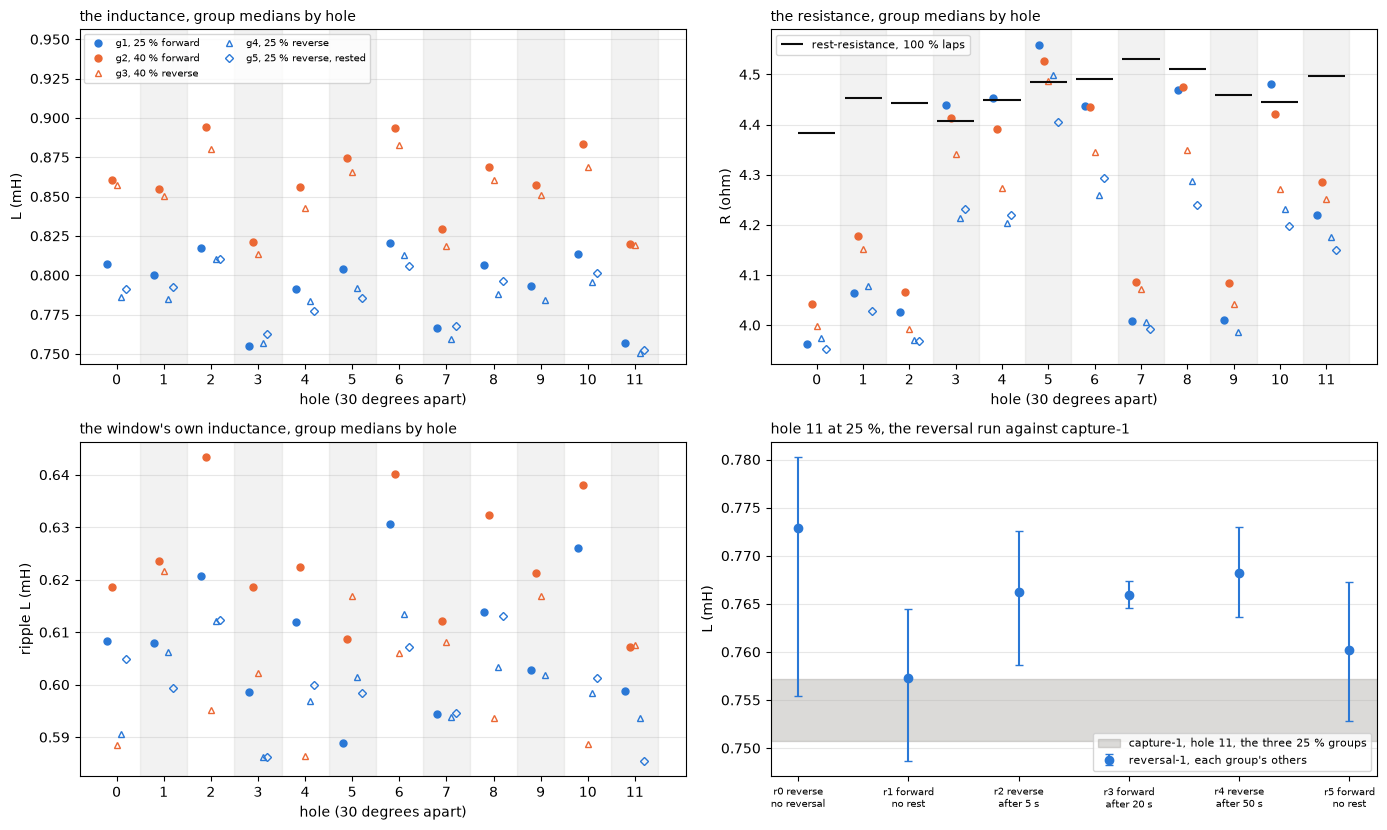

L at 25 % 0.755 to 0.814 over the holes (7.8 %), even holes over odd +3.4 %, permutation p = 0.01
L at 40 % 0.818 to 0.889 over the holes (8.6 %), even holes over odd +3.8 %, permutation p = 0.03
tau at 25 % 176.119 to 203.321 over the holes (15.4 %), even holes over odd +2.2 %, permutation p = 0.46
R 3.987 to 4.510 over the holes (13.1 %), even holes over odd +0.3 %, permutation p = 0.90
ripple L 0.600 to 0.621 over the holes (3.6 %), even holes over odd +1.1 %, permutation p = 0.12
group medians at 25 %, L 0.751 to 0.821 mH, tau 169 to 204 us
group medians at 40 %, L 0.814 to 0.894 mH, tau 186 to 220 us
group medians, every group, R 3.953 to 4.560 ohm (15 %), ripple L 0.585 to 0.643 mH
L at 25 %, the triples 120 degrees apart, holes 0, 4, 8 0.792, holes 1, 5, 9 0.790, holes 2, 6, 10 0.811, holes 3, 7, 11 0.760 mH. Holes 3, 7, 11 sit -4.7 % against the other nine, permutation p = 0.005
L at 40 %, the triples 120 degrees apart, holes 0, 4, 8 0.858, holes 1, 5, 9 0.859, holes 2, 6, 10 0

In [13]:
GM = C2.groupby(["hole", "group"])[["l_mh", "tau_us", "r_ohm", "l_ripple_mh"]].median().reset_index()   # group medians, first burst out
STYLE = {"g1-fwd-25": ("o", True), "g2-fwd-40": ("o", True), "g3-rev-40": ("^", False), "g4-rev-25": ("^", False), "g5-rev-25-rested": ("D", False)}
fig, ax = plt.subplots(2, 2, figsize=(14, 8.4))
for a, c, lab in ((ax[0, 0], "l_mh", "L (mH)"), (ax[0, 1], "r_ohm", "R (ohm)"), (ax[1, 0], "l_ripple_mh", "ripple L (mH)")):
    for h in HOLES[1::2]:
        a.axvspan(h - 0.5, h + 0.5, color=MUTED, alpha=0.1)              # odd holes shaded
    for j, (g, (mk, filled)) in enumerate(STYLE.items()):
        gg = GM[GM["group"] == g]
        col = COLOR[int(g.split("-")[2])]
        a.plot(gg["hole"] + (j - 2) * 0.1, gg[c], mk, ms=4 if mk == "D" else 5, color=col, mfc=col if filled else "none", ls="none",
               label=f"{g[:2]}, {int(g.split('-')[2])} % {'forward' if filled else 'reverse'}{', rested' if mk == 'D' else ''}")
    a.set_ylabel(lab); a.set_xticks(HOLES, [str(h) for h in HOLES]); a.set_xlabel("hole (30 degrees apart)"); a.grid(alpha=0.3, axis="y")
ax[0, 1].hlines(RR["r_term_by_hole"], np.array(HOLES) - 0.4, np.array(HOLES) + 0.4, color=INK, lw=1.5, label="rest-resistance, 100 % laps")
ax[0, 0].set_title("the inductance, group medians by hole", loc="left", fontsize=10)
ax[0, 1].set_title("the resistance, group medians by hole", loc="left", fontsize=10)
ax[1, 0].set_title("the window's own inductance, group medians by hole", loc="left", fontsize=10)
ax[0, 0].legend(fontsize=7, ncol=2, loc="upper left"); ax[0, 1].legend(handles=ax[0, 1].get_legend_handles_labels()[0][-1:], fontsize=8, loc="upper left")
lo, hi = ax[0, 0].get_ylim(); ax[0, 0].set_ylim(lo, hi + (hi - lo) * 0.35)   # room for the legend above the data

# repeatability: the reversal run's groups against capture-1's 25 % groups at hole 11
RV = OTHERS[OTHERS["set"] == "reversal-1"].groupby("group")["l_mh"].agg(["median", "min", "max"]).loc[list(RUN)]
h11 = GM[(GM["hole"] == HOLES[-1]) & GM["group"].isin(["g1-fwd-25", "g4-rev-25", "g5-rev-25-rested"])]
ax[1, 1].axhspan(h11["l_mh"].min(), h11["l_mh"].max(), color=MUTED, alpha=0.3, label="capture-1, hole 11, the three 25 % groups")
ax[1, 1].errorbar(range(len(RUN)), RV["median"], yerr=[RV["median"] - RV["min"], RV["max"] - RV["median"]], fmt="o", ms=6, color=BLUE, capsize=3,
                  label="reversal-1, each group's others")
ax[1, 1].set_xticks(range(len(RUN)), list(RUN.values()), fontsize=7); ax[1, 1].grid(alpha=0.3, axis="y"); ax[1, 1].legend(fontsize=8, loc="lower right")
ax[1, 1].set_ylabel("L (mH)"); ax[1, 1].set_title("hole 11 at 25 %, the reversal run against capture-1", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

def parity(v):
    # the even holes' mean less the odd holes' mean, in percent of the mean over all twelve, and the share of the 924 ways to
    # split the twelve holes into two sixes that give a difference at least as large, the exact permutation test
    v = np.asarray(v, float)
    d = v[0::2].mean() - v[1::2].mean()
    split = np.array([v[list(c)].mean() - np.delete(v, list(c)).mean() for c in combinations(range(len(v)), len(v) // 2)])
    return d / v.mean() * 100, float(np.mean(np.abs(split) >= abs(d) - 1e-12))

BYHOLE = {}
for lab, sel, c in (("L at 25 %", C2["pct"] == 25, "l_mh"), ("L at 40 %", C2["pct"] == 40, "l_mh"), ("tau at 25 %", C2["pct"] == 25, "tau_us"),
                    ("R", C2["pct"] > 0, "r_ohm"), ("ripple L", C2["pct"] > 0, "l_ripple_mh")):
    v = C2[sel].groupby("hole")[c].median().loc[HOLES]                     # one value per hole, the median over its bursts
    d, p = parity(v)
    BYHOLE[lab] = (v, d, p)
    print(f"{lab} {v.min():.3f} to {v.max():.3f} over the holes ({(v.max() / v.min() - 1) * 100:.1f} %), even holes over odd {d:+.1f} %, "
          f"permutation p = {p:.2f}")
for pct in DUTIES:
    g = GM[GM["group"].str.endswith(f"-{pct}") | GM["group"].str.contains(f"-{pct}-")]
    print(f"group medians at {pct} %, L {g['l_mh'].min():.3f} to {g['l_mh'].max():.3f} mH, tau {g['tau_us'].min():.0f} to {g['tau_us'].max():.0f} us")
print(f"group medians, every group, R {GM['r_ohm'].min():.3f} to {GM['r_ohm'].max():.3f} ohm ({(GM['r_ohm'].max() / GM['r_ohm'].min() - 1) * 100:.0f} %), "
      f"ripple L {GM['l_ripple_mh'].min():.3f} to {GM['l_ripple_mh'].max():.3f} mH")
# the same L split the other way the twelve holes allow, into four triples 120 degrees apart (holes h, h + 4, h + 8), with the
# share of the 220 ways to pick three holes of twelve whose mean sits as far under the rest as the lowest triple's
for lab in ("L at 25 %", "L at 40 %"):
    v = BYHOLE[lab][0]
    trip = {r: v.loc[[h for h in HOLES if h % 4 == r]].mean() for r in range(4)}
    low = min(trip, key=trip.get)
    p3 = float(np.mean(np.array([v.iloc[list(c)].mean() for c in combinations(range(len(v)), 3)]) <= trip[low] + 1e-12))
    print(f"{lab}, the triples 120 degrees apart, " + ", ".join(f"holes {r}, {r + 4}, {r + 8} {t:.3f}" for r, t in trip.items())
          + f" mH. Holes {low}, {low + 4}, {low + 8} sit {(trip[low] / v.drop(index=[low, low + 4, low + 8]).mean() - 1) * 100:+.1f} % against the other nine, "
          f"permutation p = {p3:.3f}")
fr = C2.groupby(["hole", "sign"])["r_ohm"].median().unstack()          # burst R per hole and sign, both duties together
print("burst R forward over reverse by hole, " + ", ".join(f"{h} {(fr.loc[h, 1] / fr.loc[h, -1] - 1) * 100:+.1f}" for h in HOLES) + " %")
rr = np.array(RR["r_term_by_hole"])
rb = BYHOLE["R"][0].to_numpy()
print(f"rest-resistance by hole {rr.min():.3f} to {rr.max():.3f} ohm ({(rr.max() / rr.min() - 1) * 100:.0f} %), burst R by hole over it "
      f"{(rb / rr - 1).min() * 100:+.0f} to {(rb / rr - 1).max() * 100:+.0f} %, correlation across the holes {np.corrcoef(rb, rr)[0, 1]:+.2f}")
print(f"by sign, every group, L forward {C2[C2['sign'] > 0]['l_mh'].median():.3f}, reverse {C2[C2['sign'] < 0]['l_mh'].median():.3f} mH, "
      f"R forward {C2[C2['sign'] > 0]['r_ohm'].median():.3f}, reverse {C2[C2['sign'] < 0]['r_ohm'].median():.3f} ohm")
print("reversal-1 groups, L of the others, " + ", ".join(f"{g[:2]} {r['median']:.3f}" for g, r in RV.iterrows())
      + f" mH. Capture-2 hole 11 at 25 %, " + ", ".join(f"{r['group'][:2]} {r['l_mh']:.3f}" for _, r in h11.iterrows()) + " mH")

$L$ moves with the hole by about 8 % at both duties, 0.755 to 0.814 mH at 25 % and 0.818 to 0.889 mH at 40 % in the medians by hole, and the groups of a hole move together. The even holes read 3.4 % over the odd holes at 25 % and 3.8 % at 40 %. Of the 924 ways to split the twelve holes into two sixes, 1 % and 3 % give a difference that large. The difference does not sit in all six odd holes, though. Holes 3, 7 and 11, 120 degrees apart, read 4.7 % under the other nine at 25 % and 5.5 % at 40 %, and holes 1, 5 and 9 read with the even holes. A 60 degree pattern gives every odd hole the same reading, so the data point to a pattern that repeats every 120 degrees, once per slot of the three-slot rotor, with moderate confidence. Only 0.5 % of the 220 ways to pick three holes of twelve sit that far under the rest, about 2 % once the choice of the lowest of four triples is counted. $L_\mathrm{ripple}$ moves by under 4 % across the holes and shows no parity, p = 0.12. Its group medians spread wider, 0.585 to 0.643 mH, with the forward 40 % group the highest at most holes.

$R$ tells a different story. The burst $R$ spreads 13 % over the holes, 3.99 to 4.51 ohm, where rest-resistance spread 3 % over the same twelve holes, and the two barely follow each other, a correlation of +0.24 across the holes. Holes 0, 1, 2, 7 and 9 read about 4.0 ohm, a tenth under rest-resistance, and the other seven read 4.2 to 4.6 ohm across their groups, against 4.41 to 4.51 ohm for rest-resistance at the same holes. At holes 3, 4, 6, 8 and 10 the forward groups read $R$ 3 to 5 % over the reverse groups, and at the other holes within 2 %. The forward groups always ran first, so sign and capture order go together in this run, and the data do not say which of the two the gap follows. Even and odd holes do not differ on $R$, p = 0.90. The next section shows the burst $R$ moving with the length of the fit, so this spread most likely belongs to the fit on these bursts and not to the copper, with moderate confidence. Why it moves with the hole is an open question.

Bottom right, the reversal run's groups read $L$ of 0.757 to 0.773 mH at hole 11 with nothing moved, against 0.751 to 0.757 mH for capture-1's three 25 % groups at the same hole 21 minutes earlier. The two agree within 3 %, with the reversal run's first group the highest of the six.

### R and L against the time scale

The fit over the first 3, 4 and more period pairs of every burst after the first of its group in capture-1, so $R$ and $L$ can be read against the stretch of the rise they come from, and the window's own $L_\mathrm{ripple}$ period by period. Each point is the median over every such burst of a duty and the whisker the range.

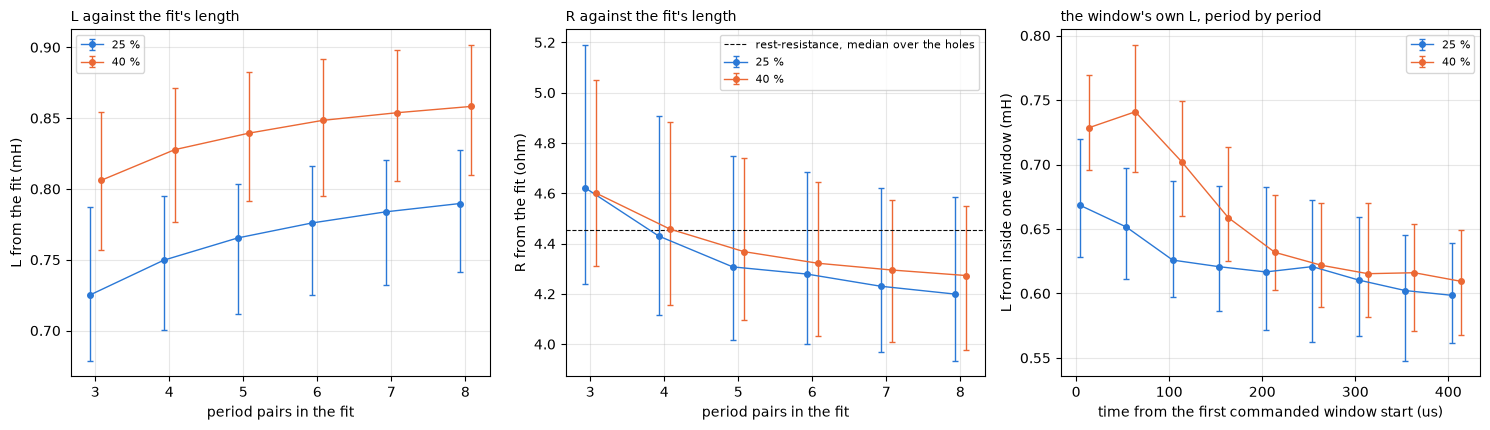

25 %, L 0.725 mH over 3 pairs, 0.790 over 8 (+9 %). R 4.623 ohm over 3, 4.199 over 8 (-9 %). The window's L 0.669 mH in the first period, 0.599 in the last
40 %, L 0.806 mH over 3 pairs, 0.858 over 8 (+6 %). R 4.601 ohm over 3, 4.273 over 8 (-7 %). The window's L 0.728 mH in the first period, 0.609 in the last
with a constant drop as a third term, both duties of each hole and sign together, drop -0.104 V (-0.124 to -0.038), R 4.551 ohm, L 0.888 mH


In [14]:
rows, rip = [], []
for _, f in C2.iterrows():
    P = PER[f["idx"]]
    for p in range(3, len(P)):
        rows.append({"pct": f["pct"], "pairs": p, **{c: fit(P, p)[c] for c in ("r_ohm", "l_mh")}})
    r = f["r_ohm"] * K
    for n, row in P.iterrows():
        rip.append({"pct": f["pct"], "t_us": row["t_us"], "n": row["n"],
                    "l_ripple_mh": (row["v_on_v"] - r * row["i_a"]) / row["slope_a_per_s"] / K * 1e3})
SCAN, RIP = pd.DataFrame(rows), pd.DataFrame(rip)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
for pct in DUTIES:
    dx = (DUTIES.index(pct) - 0.5) * 0.15
    for a, c in ((ax[0], "l_mh"), (ax[1], "r_ohm")):
        g = SCAN[SCAN["pct"] == pct].groupby("pairs")[c]
        m_, lo, hi = g.median(), g.min(), g.max()
        a.errorbar(m_.index + dx, m_, yerr=[m_ - lo, hi - m_], fmt="o-", ms=4, lw=1, color=COLOR[pct], capsize=2, label=f"{pct} %")
    g = RIP[RIP["pct"] == pct].groupby("n")
    m_, lo, hi = g["l_ripple_mh"].median(), g["l_ripple_mh"].min(), g["l_ripple_mh"].max()
    ax[2].errorbar(g["t_us"].median() + dx * 40, m_, yerr=[m_ - lo, hi - m_], fmt="o-", ms=4, lw=1, color=COLOR[pct], capsize=2, label=f"{pct} %")
ax[1].axhline(RR["r_term_median_ohm"]["value"], color=INK, lw=0.8, ls="--", label="rest-resistance, median over the holes")
ax[0].set_ylabel("L from the fit (mH)"); ax[0].set_xlabel("period pairs in the fit"); ax[0].set_title("L against the fit's length", loc="left", fontsize=10)
ax[1].set_ylabel("R from the fit (ohm)"); ax[1].set_xlabel("period pairs in the fit"); ax[1].set_title("R against the fit's length", loc="left", fontsize=10)
ax[2].set_ylabel("L from inside one window (mH)"); ax[2].set_xlabel("time from the first commanded window start (us)")
ax[2].set_title("the window's own L, period by period", loc="left", fontsize=10)
for a in ax:
    a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()
for pct in DUTIES:
    g = SCAN[SCAN["pct"] == pct].groupby("pairs")[["l_mh", "r_ohm"]].median()
    q = RIP[RIP["pct"] == pct].groupby("n")["l_ripple_mh"].median()
    print(f"{pct} %, L {g['l_mh'].iloc[0]:.3f} mH over {g.index[0]} pairs, {g['l_mh'].iloc[-1]:.3f} over {g.index[-1]} ({(g['l_mh'].iloc[-1] / g['l_mh'].iloc[0] - 1) * 100:+.0f} %). "
          f"R {g['r_ohm'].iloc[0]:.3f} ohm over {g.index[0]}, {g['r_ohm'].iloc[-1]:.3f} over {g.index[-1]} ({(g['r_ohm'].iloc[-1] / g['r_ohm'].iloc[0] - 1) * 100:+.0f} %). "
          f"The window's L {q.iloc[0]:.3f} mH in the first period, {q.iloc[-1]:.3f} in the last")

# a constant brush drop as a third term; one burst's volts and currents move together and leave it undetermined, so both duties
# of a hole and sign go into one fit, the first bursts and the excluded group left out
rows = []
for (h, sgn), grp in C2.groupby(["hole", "sign"]):
    X, Y = [], []
    for _, f in grp.iterrows():
        P = PER[f["idx"]]
        i, v = P["i_a"].to_numpy(), P["v_v"].to_numpy()
        X.append(np.c_[np.ones(len(i) - 1), (i[1:] + i[:-1]) / 2, np.diff(i) / T_S]); Y.append(v[:-1])   # V_n = V0 + R i_mean + L di / T
    (v0, r, l), *_ = np.linalg.lstsq(np.vstack(X), np.concatenate(Y), rcond=None)
    rows.append({"hole": h, "sign": sgn, "v0_v": v0, "r_ohm": r / K, "l_mh": l / K * 1e3})
V0 = pd.DataFrame(rows)
print(f"with a constant drop as a third term, both duties of each hole and sign together, drop {V0['v0_v'].median():+.3f} V "
      f"({V0['v0_v'].min():+.3f} to {V0['v0_v'].max():+.3f}), R {V0['r_ohm'].median():.3f} ohm, L {V0['l_mh'].median():.3f} mH")

A one-pole winding would draw three flat lines, the left two at the same $L$. None of them is flat. The earlier duty ramp showed the same shape, a time constant that grew with the length of the fit, and the burst now shows it inside the first half millisecond.

Read over the first three pairs, the first 150 us, the fit gives an $R$ of about 4.6 ohm, 3 to 4 % over the rest-resistance median of 4.46 ohm with a spread across the bursts that holds it, and an $L$ of 0.73 mH at 25 % and 0.81 mH at 40 %. As later periods enter the fit, $R$ falls and $L$ rises, and neither has settled when the burst runs out. Over all eight pairs $R$ reads 4.20 ohm at 25 % and 4.27 ohm at 40 %, 9 and 7 % under the three-pair value, and $L$ reads 0.79 and 0.86 mH, 9 and 6 % over it. The burst-length $R$ of the sections above is the end of this slide. So that $R$ is most likely the reading of a model that does not hold over the burst, and not the winding's resistance, with moderate confidence. The current late in the burst climbs more than an $R$ and $L$ fitted to the early periods would let it, and a constant-parameter fit accounts for that by lowering $R$ and raising $L$ together.

The window's own $L$ is lower than either. It starts near 0.67 mH at 25 % and 0.73 mH at 40 % and settles to about 0.6 mH at both duties by the end of the burst. Over 12 to 20 us the winding reads about 0.6 mH, over the first 150 us 0.73 to 0.81 mH, and over half a millisecond 0.79 to 0.86 mH. An inductance that grows with the time scale it is read over is what eddy currents in the rotor iron and the can would give, a frequency-dependent impedance that looks smaller to a fast change of current than to a slow one. A bias of the method itself would give the same picture if the line inside the window and the period means read the two time scales differently. The data here do not separate the two. The next sections do, first with the same method on a fixed inductor and then with a third reading of the window on the motor. A constant brush drop does not account for the slide. Fitted as a third term, with both duties of each hole and sign together, it comes out at -0.10 V, -0.12 to -0.04 V across the holes and signs, a drop of the wrong sign for a contact.

### The method on a fixed inductor

Stage 1's bridge-states ran this notebook's burst method, unchanged, on an RL dummy, the bare 5 ohm resistor in series with one or two 1 mH power inductors on powdered iron toroids, at the same rail, duties and frame. An inductor like that should read about the same $L$ on every time scale a burst covers, so whatever gap the two readings leave there is the method's own. The figure takes the ratio of the ripple $L$ to the period fit's $L$ from bridge-states' result file for its three inductive wirings, against the motor's from capture-1, one dot per group at each hole and the line the mean of the two signs' medians, as bridge-states reads it. The cell also reads the window's scale both ways and reads the motor once more without the second subtraction of the in-drive offset.

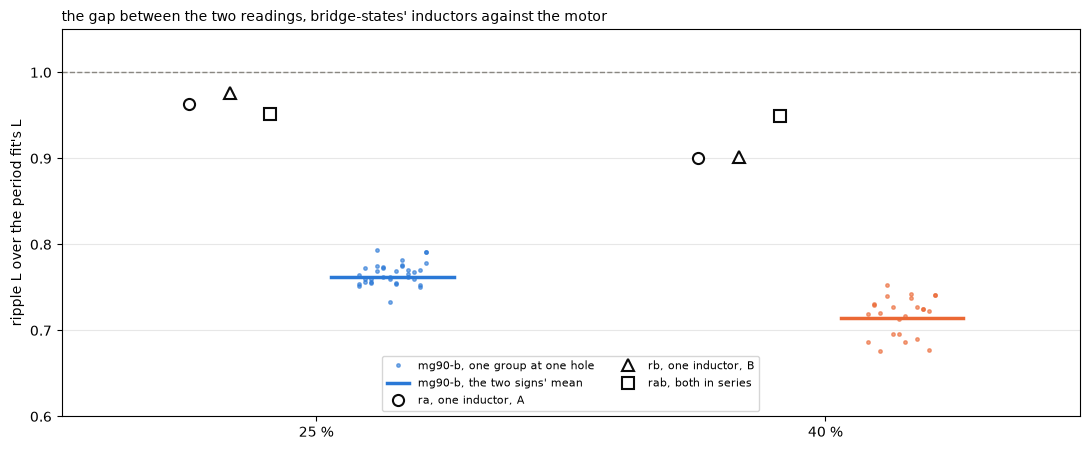

25 %, ripple over fit on the inductors 0.952 to 0.976, on the motor 0.763 (0.733 to 0.793 over its groups). The motor's gap 24 %, the inductors' 2 to 5 %
40 %, ripple over fit on the inductors 0.901 to 0.949, on the motor 0.714 (0.676 to 0.753 over its groups). The motor's gap 29 %, the inductors' 5 to 10 %
bridge-states, the first burst after a change of sign, L +3.8 % (+1.2 to +5.7), leftover 10.2 uV s, in fast decay -0.0 %
k here 1.0442 (1.0391 to 1.0491), bridge-states 1.0106 (1.0091 to 1.0136). At bridge-states' k the motor's R, L and ripple L read +3.3 %, L 0.841 mH, ripple L 0.626 mH, burst R 4.358 ohm


without the second subtraction, k 1.0387, and against the main read R -1.3 %, L -1.1 %, tau +0.1 %, ripple L +0.5 %, ripple over fit 25 % +0.013, 40 % +0.007


In [15]:
# the same method on bridge-states' fixed inductors, from its result file: the ripple over the period fit per wiring and duty
WIRES = {"ra": ("o", "one inductor, A"), "rb": ("^", "one inductor, B"), "rab": ("s", "both in series")}
IND_RATIO = {(w, p): BSR["ripple_over_fit"][f"{w}_{p}"]["value"] for w in WIRES for p in DUTIES}
# the motor's ratio per hole and group, the group medians of capture-1, and per duty the mean over the two signs as bridge-states reads it
GMR = GM.copy()
GMR["ratio"] = GMR["l_ripple_mh"] / GMR["l_mh"]
GMR["pct"] = GMR["group"].str.split("-").str[2].astype(int)
MOT_RATIO = {p: np.mean([C2[(C2["pct"] == p) & (C2["sign"] == s)]["l_ripple_mh"].median() / C2[(C2["pct"] == p) & (C2["sign"] == s)]["l_mh"].median()
                         for s in (1, -1)]) for p in DUTIES}

fig, ax = plt.subplots(figsize=(11, 4.6))
for x, pct in enumerate(DUTIES):
    g = GMR[GMR["pct"] == pct]
    ax.plot(x + 0.15 + (g["hole"].to_numpy() - 5.5) * 0.012, g["ratio"], ".", ms=5, color=COLOR[pct], alpha=0.6,
            label="mg90-b, one group at one hole" if x == 0 else None)
    ax.plot([x + 0.03, x + 0.27], [MOT_RATIO[pct]] * 2, color=COLOR[pct], lw=2.5, label="mg90-b, the two signs' mean" if x == 0 else None)
    for j, (w, (mk, lab)) in enumerate(WIRES.items()):
        ax.plot(x - 0.25 + j * 0.08, IND_RATIO[(w, pct)], mk, ms=8, color=INK, mfc="white", mew=1.5, label=f"{w}, {lab}" if x == 0 else None)
ax.axhline(1, color=MUTED, lw=1, ls="--")
ax.set_xticks(range(len(DUTIES)), [f"{p} %" for p in DUTIES]); ax.set_xlim(-0.5, 1.5); ax.set_ylim(0.6, 1.05)
ax.set_ylabel("ripple L over the period fit's L"); ax.grid(alpha=0.3, axis="y"); ax.legend(fontsize=8, ncol=2, loc="lower center")
ax.set_title("the gap between the two readings, bridge-states' inductors against the motor", loc="left", fontsize=10)
plt.tight_layout(); plt.show()
for p in DUTIES:
    here = [IND_RATIO[(w, p)] for w in WIRES]
    print(f"{p} %, ripple over fit on the inductors {min(here):.3f} to {max(here):.3f}, on the motor {MOT_RATIO[p]:.3f} "
          f"({GMR[GMR['pct'] == p]['ratio'].min():.3f} to {GMR[GMR['pct'] == p]['ratio'].max():.3f} over its groups). The motor's gap "
          f"{(1 - MOT_RATIO[p]) * 100:.0f} %, the inductors' {(1 - max(here)) * 100:.0f} to {(1 - min(here)) * 100:.0f} %")
print(f"bridge-states, the first burst after a change of sign, L {BSR['first_burst_l_jump_pct']['slow']['value']:+.1f} % "
      f"({BSR['first_burst_l_jump_pct']['slow']['lo']:+.1f} to {BSR['first_burst_l_jump_pct']['slow']['hi']:+.1f}), "
      f"leftover {BSR['first_burst_leftover_uvs']['value']:.1f} uV s, in fast decay {BSR['first_burst_l_jump_pct']['fast']['value']:+.1f} %")

# the window's scale two ways: this notebook's from sample-timing's bursts over current-scale's laps, bridge-states' from its own resistor
# wiring's bursts over the same wiring's laps in one sitting. R, L and the ripple L divide by it, tau and every ratio do not
K_BS = BSR["window_scale"]["value"]
K_MOVE = K / K_BS                                                      # what the motor's R and L read at bridge-states' k, over this notebook's
print(f"k here {K:.4f} ({K_LO:.4f} to {K_HI:.4f}), bridge-states {K_BS:.4f} ({BSR['window_scale']['lo']:.4f} to {BSR['window_scale']['hi']:.4f}). "
      f"At bridge-states' k the motor's R, L and ripple L read {(K_MOVE - 1) * 100:+.1f} %, L {C2['l_mh'].median() * K_MOVE:.3f} mH, "
      f"ripple L {C2['l_ripple_mh'].median() * K_MOVE:.3f} mH, burst R {C2['r_ohm'].median() * K_MOVE:.3f} ohm")

# the burst's zero, read before the step, already holds about the in-drive offset (bridge-states), and `periods` takes the offset off the
# window level again. The same reading with that second subtraction left out, k read again the same way from the resistor bursts
DRIVE_OFF_KEEP = DRIVE_OFF
DRIVE_OFF = 0.0                                                         # periods() reads this global, put back below
try:
    rw0 = []
    for folder in ("bursts", "bursts-1s"):
        for df_r in bu.load(RESISTOR / folder):
            m_r = bu.meta(df_r)
            if round(abs(m_r["step_q15"]) * 100 / 32768) >= 15:
                P = periods(df_r, 1 if m_r["step_q15"] > 0 else -1).iloc[1:]
                rw0.append(P["v_on_v"].median() / P["i_a"].median())
    K0 = np.median(rw0) / RL["r_ohm"].median()
    rows = []
    for _, f in C2.iterrows():
        e = B.loc[f["idx"]]
        P = periods(e["df"], e["sign"], EDGES[(e["set"], e["pct"], e["sign"])])
        g = fit(P)                                                        # divided by the main K, so rescaled to K0 below
        r, l = g["r_ohm"] * K / K0, g["l_mh"] * K / K0
        rip = np.median(((P["v_on_v"] - r * K0 * P["i_a"]) / P["slope_a_per_s"] / K0 * 1e3).iloc[-3:])
        rows.append({"pct": f["pct"], "r_ohm": r, "l_mh": l, "tau_us": g["tau_us"], "l_ripple_mh": rip})
finally:
    DRIVE_OFF = DRIVE_OFF_KEEP
NOOFF = pd.DataFrame(rows)
OFF_MOVE = {c: (NOOFF[c].median() / C2[c].median() - 1) * 100 for c in ("r_ohm", "l_mh", "tau_us", "l_ripple_mh")}
ratio0 = {p: NOOFF[NOOFF["pct"] == p]["l_ripple_mh"].median() / NOOFF[NOOFF["pct"] == p]["l_mh"].median() for p in DUTIES}
ratio1 = {p: C2[C2["pct"] == p]["l_ripple_mh"].median() / C2[C2["pct"] == p]["l_mh"].median() for p in DUTIES}
print(f"without the second subtraction, k {K0:.4f}, and against the main read " + ", ".join(f"{QTY[c]} {v:+.1f} %" for c, v in OFF_MOVE.items())
      + ", ripple over fit " + ", ".join(f"{p} % {ratio0[p] - ratio1[p]:+.3f}" for p in DUTIES))

On the inductors the ripple reads 0.952 to 0.976 of the fit at 25 % and 0.901 to 0.949 at 40 %. On the motor it reads 0.763 and 0.714, and no group at any hole comes within 0.15 of the inductors. So the method has a gap of its own, 2 to 5 % at 25 % and 5 to 10 % at 40 %, and the motor's gap of 24 and 29 % is mostly the motor's, with high confidence. Bridge-states also ran the fit over 3 to 8 period pairs on the same inductors and found $L$ within 2 % and $R$ within 4 % of the full-burst values on all but the slower two-inductor wiring at 25 %, where the motor's $L$ rises 8 % and its $R$ falls 9 % over the same pairs. So the slide of the fit with its length is the motor's too, with high confidence. Bridge-states' fast-decay ramp agreed with the period fit within 4 % on every wiring.

The first burst after a change of sign reads $L$ 3.8 % high on the inductors too, 1.2 to 5.7 % over twelve sets, with 10.2 uV s of leftover and no rotor at all. Powdered iron keeps a small remanence of its own, so this is most likely the same magnetic history at about a third of the motor's size, with moderate confidence. Bridge-states could not separate it from the set boundary, since every set there changed the sign. In fast decay its first bursts read within the others' scatter.

Two readings differ between the two notebooks. Both are carried as bounds and not changed here.

- The window's scale $k$. Bridge-states read it as 1.011 from its own resistor wiring's bursts over the same wiring's laps in one sitting. This notebook reads 1.044 from sample-timing's bursts over current-scale's laps, two captures with two wirings. $k$ divides $R$, $L$ and $L_\mathrm{ripple}$ alike, so at bridge-states' $k$ all three read 3.3 % higher, $L$ 0.841 mH, $L_\mathrm{ripple}$ 0.626 mH and the burst $R$ 4.36 ohm. $\tau$ and every ratio do not move. Neither $k$ was read from a resistor wired like the motor in the motor's sitting. With this notebook's $k$ bridge-states' inductors would land within a percent or two of their nominal, where its own $k$ puts them 3 to 6 % over it, and the parts' tolerance is not known well enough to choose. So this notebook keeps its own $k$ as the main read, with low confidence in either over the other, and the 3.3 % goes into the results as a bound on every absolute $R$ and $L$.
- The in-drive offset. The burst's zero, read before the step, already holds about the in-drive offset, and `periods` takes the offset off the window level a second time. Read without the second subtraction, with $k$ read again the same way, the motor's $R$ moves -1.3 %, $L$ -1.1 % and $L_\mathrm{ripple}$ +0.5 %, and the ratio of the ripple to the fit rises by 0.013 at 25 % and 0.007 at 40 %. Bridge-states found up to 2.8 % on $R$ on its wirings. The offset stays as this notebook has it, and the move goes into the results as a bound.

### Fast decay on the motor

`fast-1` ran at hole 11 less than a minute after `steps-1`. It runs the main run's four groups in fast decay, 25 and 40 % in both signs, and then a forward 25 % and a forward 40 % group in slow decay at the same seat. In fast decay the drive window sits on the PWM trough rather than the crest, and between windows the bridge opens all four switches, so the winding's current returns to the rail through the body diodes against the rail's voltage. The duty written at the step takes effect at the next trough, so the window centered on that trough holds only its second half, and the grid starts one period later at the first full window. `samples` takes the trough as the window's center for these bursts, as bridge-states reads them. On a 1 mH inductor below 50 % the current reaches zero before the next window, so each window's ramp starts from zero with no step in front of it for the shunt amplifier to settle from, and the line through the window gives a third $L$, as bridge-states computes it.

Below, every full period of every forward fast-decay burst pooled against the ticks from the trough, the motor beside bridge-states' `ra`, one 1 mH inductor and the resistor, with the commanded window shaded.

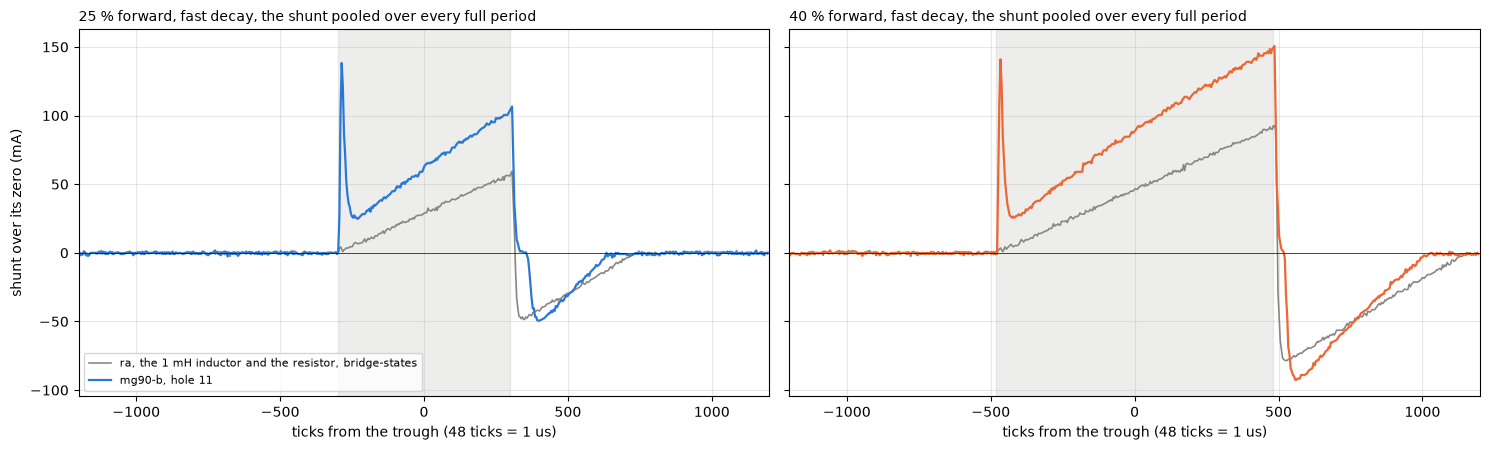

fast-1 began 47 s after steps-1 ended, f1-fwd-25 fast, f2-fwd-40 fast, f3-rev-40 fast, f4-rev-25 fast, f5-fwd-25 slow, f6-fwd-40 slow
25 %, the motor: spike 138 mA at the ON edge, the line through the window 17.5 mA at the bridge's ON edge and 103 mA at its OFF edge, the fold's top 107 mA, the return from 49 mA (0.46 of the top), ending 7.1 us after the OFF edge. The shunt then reads 0.5 counts from the zero in the median for 30 us until the next window
      ra: spike 7 mA, top 59 mA, return from 48 mA (0.81 of the top), 29 us at zero before the next window
      the spike's charge over the window's line, motor 42 nC, ra 1 nC. On the motor that is 9 nF at the window's 4.92 V
40 %, the motor: spike 141 mA at the ON edge, the line through the window 21.5 mA at the bridge's ON edge and 150 mA at its OFF edge, the fold's top 151 mA, the return from 93 mA (0.61 of the top), ending 10.5 us after the OFF edge. The shunt then reads 1.0 counts from the zero in the median for 19 us until the ne

In [16]:
FB = load_run(FAST)
R_SEAT = RR["r_term_by_hole"][HOLES[-1]]                                # hole 11's resistance at 100 % from rest-resistance, for V_on - R i

def fast_periods(df, sign, r_ohm, start=SETTLE):
    # bridge-states' reading of a fast-decay burst: one row per full period on the grid centered on the trough, the line through the
    # window's shunt samples from `start` ticks after the commanded start to the commanded end, the window's volts, and
    # L = (V_on - R i_mid) / slope divided by k as the slow readings are. The line also gives the current at the bridge's two edges
    s, m, half = samples(df, center="trough")
    s = s[(s["n"] >= 0) & s["full"]].assign(y=lambda d: d["code"] - bu.zero(df, ARR))
    a, b = -half + TAP_ON_LAG, half + OFF_LAG                              # the bridge's ON and OFF edges in ticks from the trough
    inside = (s["tc"] >= -half + start) & (s["tc"] <= half)
    rows = []
    for n, g in s.groupby("n"):
        sh = g[(g["stream"] == "sh") & inside[g.index]]
        line = np.polyfit(sh["tc"], sh["y"], 1)
        slope = line[0] * bu.TICKS_PER_US * 1e6 / COUNTS_PER_A               # A/s
        i_mid, i_on, i_off = ((np.polyval(line, x) - DRIVE_OFF) / COUNTS_PER_A for x in ((a + b) / 2, a, b))
        d = g[(g["stream"] == "ta") & inside[g.index]]["code"].mean() - g[(g["stream"] == "tb") & inside[g.index]]["code"].mean()
        v_on = (sign * d - TERM_OFF) / COUNTS_PER_V
        rows.append({"n": n, "slope_a_per_s": slope, "i_mid_a": i_mid, "i_on_a": i_on, "i_off_a": i_off, "v_on_v": v_on,
                     "l_mh": (v_on - r_ohm * K * i_mid) / slope / K * 1e3})
    return pd.DataFrame(rows)

def trough_fold(dfs, w=4):
    # every full period of every burst pooled, the shunt over its zero in counts against the ticks from the trough, the median per bin
    out = []
    for df in dfs:
        s, m, half = samples(df, center="trough")
        s = s[(s["n"] >= 0) & s["full"] & (s["stream"] == "sh")]
        out.append(np.c_[s["tc"], s["code"] - bu.zero(df, ARR)])
    pts = np.vstack(out)
    x, p = bu.profile(pts[:, 0], pts[:, 1], -ARR, ARR - w, w)
    return x, p, half

FAST_B = FB[FB["decay"] == "fast"]
rows = []
for idx, e in FAST_B.iterrows():
    for start in (SETTLE, 150):                                            # from the shunt's settle, and from well past the ON-edge spike
        F_ = fast_periods(e["df"], e["sign"], R_SEAT, start)
        rows.append({"idx": idx, **e[["group", "k", "first", "pct", "sign"]].to_dict(), "start": start, "l_mh": F_["l_mh"].median(),
                     "l_first3": F_["l_mh"].iloc[:3].median(), "l_last3": F_["l_mh"].iloc[-3:].median(),
                     **{c: F_[c].median() for c in ("i_on_a", "i_off_a", "i_mid_a", "v_on_v")}})
FR = pd.DataFrame(rows)
FRO = FR[~FR["first"] & (FR["start"] == SETTLE)]                         # the main read, the first burst of each group out

# the stage 1 RL dummy's fast bursts, one 1 mH inductor and the resistor, the same fold beside the motor's
RA = []
for df in bu.load(BRIDGE / "ra" / "bursts-fast"):
    m = bu.meta(df)
    RA.append({"pct": int(round(abs(m["step_q15"]) * 100 / 32768)), "sign": 1 if m["step_q15"] > 0 else -1, "df": df})
RA = pd.DataFrame(RA)

FOLD = {}
for pct in DUTIES:
    for name, dfs in (("motor", FAST_B[(FAST_B["pct"] == pct) & (FAST_B["sign"] > 0)]["df"]), ("ra", RA[(RA["pct"] == pct) & (RA["sign"] > 0)]["df"])):
        x, p, half = trough_fold(list(dfs))
        top = p[(x > half - 40) & (x < half + OFF_LAG)].max()              # the ramp's top, the bins just before the bridge's OFF edge
        after = x > half + OFF_LAG
        ret = -p[after].min()                                              # the return's largest reading, the shunt the wrong way
        end = x[after & (p < -3)].max()                                    # the return's end, the last bin more than 3 counts under the zero
        quiet = (x > end + 20) | (x < -half - 10)                          # from the return's end round to the next commanded start
        spike = p[(x >= -half) & (x <= -half + SETTLE)].max()
        # the charge in the spike, the fold over a line through the window's later part, from the commanded start to the shunt's settle
        ln = np.polyfit(x[(x > -half + SETTLE + 30) & (x < half - 10)], p[(x > -half + SETTLE + 30) & (x < half - 10)], 1)
        zone = (x >= -half) & (x <= -half + SETTLE)
        q_nc = ((p[zone] - np.polyval(ln, x[zone])).sum() * 4 / COUNTS_PER_A / bu.TICKS_PER_US * 1e3)   # counts x ticks -> nC
        FOLD[(name, pct)] = {"x": x, "p": p, "half": half, "top_ma": top / COUNTS_PER_A * 1e3, "return_ma": ret / COUNTS_PER_A * 1e3,
                             "end": end, "zero_us": (PERIOD - half - end) / bu.TICKS_PER_US, "quiet_counts": float(np.median(np.abs(p[quiet]))),
                             "spike_ma": spike / COUNTS_PER_A * 1e3, "spike_nc": q_nc}

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
for a, pct in zip(ax, DUTIES):
    for name, col, lw in (("ra", MUTED, 1.2), ("motor", COLOR[pct], 1.6)):
        f_ = FOLD[(name, pct)]
        a.plot(f_["x"], f_["p"] / COUNTS_PER_A * 1e3, "-", color=col, lw=lw,
               label="mg90-b, hole 11" if name == "motor" else "ra, the 1 mH inductor and the resistor, bridge-states")
    half = FOLD[("motor", pct)]["half"]
    a.axvspan(-half, half, color=MUTED, alpha=0.15); a.axhline(0, color=INK, lw=0.5); a.grid(alpha=0.3)
    a.set_xlabel("ticks from the trough (48 ticks = 1 us)"); a.set_xlim(-ARR, ARR)
    a.set_title(f"{pct} % forward, fast decay, the shunt pooled over every full period", loc="left", fontsize=10)
ax[0].set_ylabel("shunt over its zero (mA)"); ax[0].legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

mf = marks(FAST)
print(f"fast-1 began {mf['t_host'].iloc[0] - ms['t_host'].iloc[-1]:.0f} s after steps-1 ended, "
      + ", ".join(f"{g} {d}" for g, d in FB.groupby("group")["decay"].first().items()))
for pct in DUTIES:
    m_, r_ = FOLD[("motor", pct)], FOLD[("ra", pct)]
    g = FRO[FRO["pct"] == pct]
    print(f"{pct} %, the motor: spike {m_['spike_ma']:.0f} mA at the ON edge, the line through the window {g['i_on_a'].median() * 1e3:.1f} mA at the bridge's ON edge "
          f"and {g['i_off_a'].median() * 1e3:.0f} mA at its OFF edge, the fold's top {m_['top_ma']:.0f} mA, the return from {m_['return_ma']:.0f} mA "
          f"({m_['return_ma'] / m_['top_ma']:.2f} of the top), ending {(m_['end'] - m_['half'] - OFF_LAG) / bu.TICKS_PER_US:.1f} us after the OFF edge. "
          f"The shunt then reads {m_['quiet_counts']:.1f} counts from the zero in the median for {m_['zero_us']:.0f} us until the next window")
    print(f"      ra: spike {r_['spike_ma']:.0f} mA, top {r_['top_ma']:.0f} mA, return from {r_['return_ma']:.0f} mA ({r_['return_ma'] / r_['top_ma']:.2f} of the top), "
          f"{r_['zero_us']:.0f} us at zero before the next window")
    print(f"      the spike's charge over the window's line, motor {m_['spike_nc']:.0f} nC, ra {r_['spike_nc']:.0f} nC. On the motor that is "
          f"{m_['spike_nc'] / FRO[FRO['pct'] == pct]['v_on_v'].median():.0f} nF at the window's {FRO[FRO['pct'] == pct]['v_on_v'].median():.2f} V")

# the same ON-edge step read the teardown's way: one line per burst through every full period from 150 ticks after the commanded
# start, past the spike and the ring's slower charge, to 20 ticks before the commanded end, read at fast decay's own ON edge from the
# teardown's fit on stage 1's r and ra, over the burst's own pre-step zero, which already holds the in-drive offset, so nothing more
# comes off it. The step above, fast_on_edge_step_ma, stays as it was, at slow decay's lag with the offset taken off a second time
TD = results.read("2-motor", "teardown", pair=MOTOR.key)
FAST_ON_LAG = TD["fast_edge_lags_ticks"]["on"]["value"]                 # ticks after the commanded start, fast decay

def fast_step(df):
    # one burst's window line read back to the fast-decay ON edge, in amps over the burst's own zero
    s, m, half = samples(df, center="trough")
    sh = s[(s["n"] >= 0) & s["full"] & (s["stream"] == "sh")]
    win = (sh["tc"] >= -half + 150) & (sh["tc"] <= half - 20)
    line = np.polyfit(sh["tc"][win], sh["code"][win] - bu.zero(df, ARR), 1)
    return np.polyval(line, -half + FAST_ON_LAG) / COUNTS_PER_A

STEP_FAST = pd.DataFrame([{"pct": e["pct"], "i_on_a": fast_step(e["df"])} for _, e in FAST_B[~FAST_B["first"]].iterrows()])
STEP_FAST = STEP_FAST.groupby("pct")["i_on_a"].agg(mean="mean", se=lambda v: v.std(ddof=1) / np.sqrt(len(v)), n="size")   # mean and its standard error
for pct, r in STEP_FAST.iterrows():
    print(f"{pct} %, the step read the teardown's way, {r['mean'] * 1e3:.1f} +/- {r['se'] * 1e3:.1f} mA over {r['n']:.0f} bursts at the fast-decay ON edge, "
          f"{FAST_ON_LAG:.0f} ticks after the commanded start, against {FRO[FRO['pct'] == pct]['i_on_a'].median() * 1e3:.1f} mA at slow decay's {TAP_ON_LAG:.1f}")
WO = TD["window_offset_ma"]                                             # the teardown's step at the fast-decay ON edge, by run and duty
print("the teardown's step at the fast-decay ON edge, " + "; ".join(f"{run} " + ", ".join(f"{d} {q['value']:.1f} mA" for d, q in WO[run].items())
                                                                 for run in ("motor, fast-1 hole 11", "coil-noring-1", "coil-can-1")))
print(f"the teardown's iron-loss conductance on the motor {TD['iron_loss_g_ms']['motor, fast-1 hole 11']['value']:.2f} mS, "
      f"the drive-only current over the ring's swept current {TD['drive_only_over_ring_current']['lo']:.0f} to {TD['drive_only_over_ring_current']['hi']:.0f} times, "
      f"the ring's pad pair {TD['ring_pair_ua_by_v']['7.4 V']['value'] / 1e3:.2f} mA at 7.4 V and 1 mA at {TD['ring_v_at_1ma_v']['value']:.2f} V")

The motor's current is discontinuous at both duties, with high confidence. After each window the shunt reads the return the wrong way, as on the inductor, and the return ends 7.1 us after the bridge's OFF edge at 25 % and 10.5 us after it at 40 %. From there the shunt reads its zero, 0.5 and 1.0 counts off it in the median, for the last 30 us of the period at 25 % and 19 us at 40 %, until the next window starts. So every window starts with no current in the winding.

Two things differ from the inductor. At the ON edge the motor's shunt jumps to about 140 mA for under a microsecond, a spike that holds about 40 nC over the window's later line, and then it settles onto a ramp that does not start from zero. The line through the window reads 17.5 mA at the bridge's ON edge at 25 % and 21.5 mA at 40 %, where the inductor's starts within a count of zero. That reading places the ON edge at slow decay's lag from sample-timing, 39.5 ticks after the commanded start, and takes the in-drive offset off the burst's own zero, which already holds it, a second time. The [teardown](../teardown/teardown.ipynb) later found fast decay's ON edge 8 ticks after the commanded start and its OFF edge 12 ticks after the commanded end, since no dead time comes before an ON edge from all four switches open. Read at that edge over the burst's own zero, one line per burst from 150 ticks after the commanded start to 20 ticks before its end, the same windows give 18.0 $\pm$ 0.2 mA at 25 % and 23.2 $\pm$ 0.1 mA at 40 %, the teardown's own reading of them. The results carry that as `fast_on_edge_step_corrected_ma`, and `fast_on_edge_step_ma` keeps the first reading for the notebooks that read it. The main read in `fast_periods` takes the offset off a second time as well, and the method check above shows the size of that, read without the second subtraction. The fast-decay edges would also move the window's middle and OFF-edge currents there slightly. Neither is recomputed here, so `fast_l_ramp_mh` and the main $R$ and $L$ stay as they were. The spike is where the largest shunt readings of a fast-decay burst come from, so those readings run past what a winding of 0.6 to 0.7 mH ramping from zero would reach. The ramp itself tops out at 103 mA at 25 % and 150 mA at 40 %. The other difference is the return. It starts at 0.46 of the window's top at 25 % and 0.61 at 40 %, where the inductor's starts at 0.81 and 0.85.

About 40 nC at a step of 4.9 V is what a capacitance of 8 to 9 nF across the terminals would take. The teardown found a gray disc behind the commutator, about 4.75 nF between each pair of neighboring segments as read on the rotor, which the brushes see at an edge as about 7.1 nF with each brush on one segment and about 9.5 nF with a brush bridging two. That brackets the 8 to 9 nF, so the ring most likely holds the spike's charge, with moderate to high confidence. The step under the ramp and the low start of the return both fit something that carries current in proportion to the terminal voltage, a path of a few hundred ohms in parallel with the winding's inductance, whose current reverses with the voltage at the OFF edge. Swept off the rotor, the disc is a varistor ring, its current smooth, symmetric and strongly nonlinear, one pad pair passing 1 mA at 7.82 V and 0.80 mA at 7.4 V, high confidence. Every drive-only current sits 16 to 119 times over that ring's current at its own volts, so the ring is not that path, with high confidence. The teardown's runs on one coil of the bare rotor read the path itself. A bare coil with no brushes, no magnets, no can and no ring still carries a step, 7.2 mA at 25 % and 9.5 mA at 40 %, and back in the can with its magnets 18.0 and 21.6 mA, against the motor's 18.0 and 23.2. So the step is most likely an iron-loss conductance across the magnetizing inductance, 4.62 mS on the motor, about half of it in the rotor's laminations and the rest arriving with the can and the magnets, with the brushes at most a minor share, moderate to high confidence on one run each.

A window current that reads about 20 mA over the part that builds flux would also explain the constant drop of the wrong sign that the three-term fit found in the section on the time scale. $R$ times 20 mA is about 0.08 to 0.10 V, and a fit with a constant term puts it there with a negative sign, against the -0.10 V the fit came out at, with low confidence until the slow-decay window is shown to carry the same step.

### Three readings at one seat

The fast-decay ramp's $L$ at hole 11, beside the period fit and $L_\mathrm{ripple}$ of capture-1's groups at the same hole and of fast-1's two slow groups at the same seat. Each point is the median over the bursts after the first of each group, with the range.

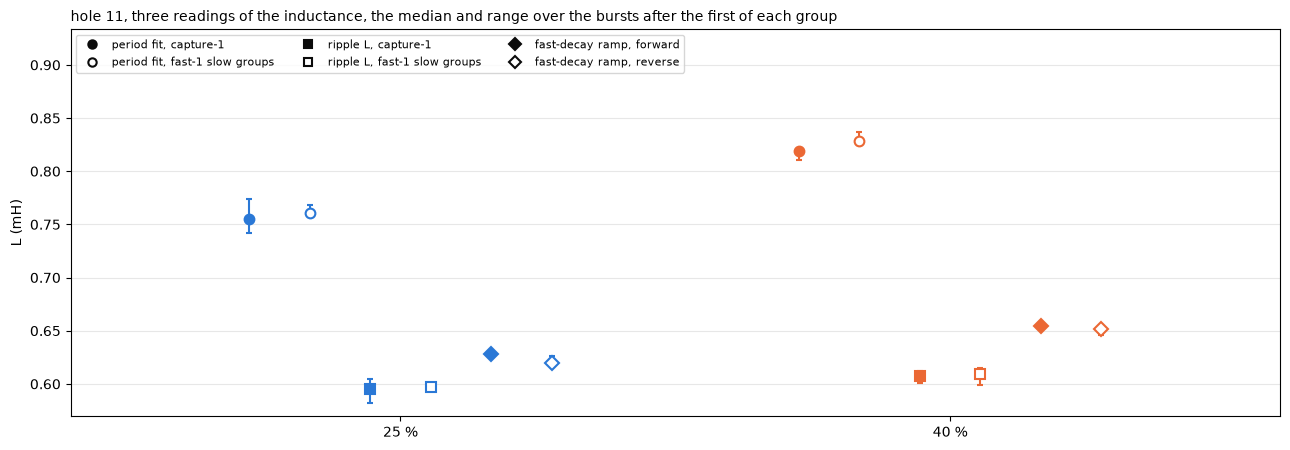

25 %, period fit, capture-1 0.755, period fit, fast-1 slow groups 0.760, ripple L, capture-1 0.595, ripple L, fast-1 slow groups 0.597, fast-decay ramp, forward 0.628, fast-decay ramp, reverse 0.620 mH. The fast ramp over the period fit 0.829, over the ripple L 1.053. With the line from 150 ticks 0.630 mH (+0.5 %). First three periods 0.632, last three 0.618 mH
40 %, period fit, capture-1 0.819, period fit, fast-1 slow groups 0.828, ripple L, capture-1 0.607, ripple L, fast-1 slow groups 0.609, fast-decay ramp, forward 0.654, fast-decay ramp, reverse 0.652 mH. The fast ramp over the period fit 0.797, over the ripple L 1.075. With the line from 150 ticks 0.665 mH (+1.8 %). First three periods 0.659, last three 0.651 mH
the fast ramp with the burst fit's R at hole 11, 4.223 ohm, in place of rest-resistance's 4.497, 0.640 mH against 0.637 (+0.5 %)
on bridge-states' inductors the fast ramp over the period fit 0.962 to 0.999
f1-fwd-25, fast ramp, first burst over the others -0.8 %
f2-fwd-40

In [17]:
# three readings of the inductance at hole 11 by duty: the period fit and the ripple L of capture-1's 25 % or 40 % groups at the hole and
# of fast-1's two slow groups at the same seat, and the fast-decay ramp of fast-1, each the median and range over the bursts after the first
FEDGES = {(p, s): edge_profiles(g)[0] for (p, s), g in FB[FB["decay"] == "slow"].groupby(["pct", "sign"])}
FS, FPER = read_run(FB[FB["decay"] == "slow"], FEDGES)
H11 = C2[C2["hole"] == HOLES[-1]]
READ = []
for pct in DUTIES:
    for lab, v in (("period fit, capture-1", H11[H11["pct"] == pct]["l_mh"]), ("period fit, fast-1 slow groups", FS[~FS["first"] & (FS["pct"] == pct)]["l_mh"]),
                   ("ripple L, capture-1", H11[H11["pct"] == pct]["l_ripple_mh"]), ("ripple L, fast-1 slow groups", FS[~FS["first"] & (FS["pct"] == pct)]["l_ripple_mh"]),
                   ("fast-decay ramp, forward", FRO[(FRO["pct"] == pct) & (FRO["sign"] > 0)]["l_mh"]),
                   ("fast-decay ramp, reverse", FRO[(FRO["pct"] == pct) & (FRO["sign"] < 0)]["l_mh"])):
        READ.append({"pct": pct, "reading": lab, "median": v.median(), "lo": v.min(), "hi": v.max()})
READ = pd.DataFrame(READ)

fig, ax = plt.subplots(figsize=(13, 4.6))
LABS = list(dict.fromkeys(READ["reading"]))
MK = {"period fit": "o", "ripple L": "s", "fast-decay ramp": "D"}
for x, pct in enumerate(DUTIES):
    for j, lab in enumerate(LABS):
        r = READ[(READ["pct"] == pct) & (READ["reading"] == lab)].iloc[0]
        open_ = "fast-1" in lab or "reverse" in lab
        ax.errorbar(x + (j - 2.5) * 0.11, r["median"], yerr=[[r["median"] - r["lo"]], [r["hi"] - r["median"]]], fmt=MK[lab.split(",")[0]], ms=7,
                    color=COLOR[pct], mfc="white" if open_ else COLOR[pct], mew=1.5, capsize=2)
ax.set_xticks(range(len(DUTIES)), [f"{p} %" for p in DUTIES]); ax.set_xlim(-0.6, 1.6)
ax.set_ylabel("L (mH)"); ax.grid(alpha=0.3, axis="y")
ax.legend(handles=[plt.Line2D([], [], ls="none", marker=MK[lab.split(",")[0]], color=INK, mfc="white" if ("fast-1" in lab or "reverse" in lab) else INK,
                              mew=1.5, label=lab) for lab in LABS], fontsize=8, ncol=3, loc="upper left")
lo, hi = ax.get_ylim(); ax.set_ylim(lo, hi + (hi - lo) * 0.3)
ax.set_title("hole 11, three readings of the inductance, the median and range over the bursts after the first of each group", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

FAST_OVER_FIT, FAST_OVER_RIP, FAST_LATE = {}, {}, {}
for pct in DUTIES:
    r = READ[READ["pct"] == pct].set_index("reading")["median"]
    fast_, fit_, rip_ = FRO[FRO["pct"] == pct]["l_mh"].median(), H11[H11["pct"] == pct]["l_mh"].median(), H11[H11["pct"] == pct]["l_ripple_mh"].median()
    late = FR[~FR["first"] & (FR["start"] == 150) & (FR["pct"] == pct)]["l_mh"].median()
    FAST_OVER_FIT[pct], FAST_OVER_RIP[pct], FAST_LATE[pct] = fast_ / fit_, fast_ / rip_, (late / fast_ - 1) * 100
    print(f"{pct} %, " + ", ".join(f"{k} {v:.3f}" for k, v in r.items()) + f" mH. The fast ramp over the period fit {fast_ / fit_:.3f}, over the ripple L "
          f"{fast_ / rip_:.3f}. With the line from 150 ticks {late:.3f} mH ({(late / fast_ - 1) * 100:+.1f} %). First three periods "
          f"{FRO[FRO['pct'] == pct]['l_first3'].median():.3f}, last three {FRO[FRO['pct'] == pct]['l_last3'].median():.3f} mH")
r_fit11 = H11["r_ohm"].median()                                          # the burst fit's R at the hole, against rest-resistance's
alt = np.median([fast_periods(e["df"], e["sign"], r_fit11)["l_mh"].median() for _, e in FAST_B[~FAST_B["first"]].iterrows()])
print(f"the fast ramp with the burst fit's R at hole 11, {r_fit11:.3f} ohm, in place of rest-resistance's {R_SEAT:.3f}, {alt:.3f} mH against "
      f"{FRO['l_mh'].median():.3f} ({(alt / FRO['l_mh'].median() - 1) * 100:+.1f} %)")
ind = {w: BSR["l_fast_ramp_mh"][f"{w}_{p}"]["value"] / BSR["l_fit_mh"][f"{w}_{p}"]["value"] for w in ("ra", "rab", "rb") for p in DUTIES}
print(f"on bridge-states' inductors the fast ramp over the period fit {min(ind.values()):.3f} to {max(ind.values()):.3f}")
# the first burst of each group: the fast ramp after a reversal, and the slow groups after the fast ones
FAST_JUMP, SLOW_JUMP = {}, {}
for g, grp in FR[FR["start"] == SETTLE].groupby("group", sort=False):
    FAST_JUMP[g] = (grp[grp["first"]]["l_mh"].iloc[0] / grp[~grp["first"]]["l_mh"].median() - 1) * 100
    print(f"{g}, fast ramp, first burst over the others {FAST_JUMP[g]:+.1f} %")
for g, grp in FS.groupby("group", sort=False):
    first, rest = grp[grp["first"]].iloc[0], grp[~grp["first"]]
    SLOW_JUMP[g] = {"l_first_jump_pct": (first["l_mh"] / rest["l_mh"].median() - 1) * 100, "leftover_uvs": first["flux_uvs"]}
    print(f"{g}, slow, first burst " + ", ".join(f"{lab} {(first[c] / rest[c].median() - 1) * 100:+.1f} %" for c, lab in QTY.items())
          + f", leftover {first['flux_uvs']:+.1f} uV s, free-rotor bound {travel_bound(FPER[first['idx']]):.1f}")

The fast-decay ramp reads the motor at 0.62 to 0.63 mH at 25 % and 0.65 mH at 40 %, the two signs within about 1 % of each other. That is 5 to 8 % over the ripple $L$ at the same seat and 17 to 20 % under the period fit, where on bridge-states' inductors the same ramp read 0.96 to 1.00 of the fit. Fast-1's slow groups repeat capture-1's period fit and ripple $L$ at the hole within about 1 %, so the seat did not move between the runs. So two readings of the window with different histories in front of it, one after the amplifier's step in slow decay and one from a start with no current in fast decay, put the motor at about 0.6 to 0.65 mH on the time scale of one window, and the period fit puts it at 0.76 to 0.83 mH at the same seat. The gap is the motor's, with high confidence. The ramp also climbs a little within its own window. Drawn from 150 ticks after the commanded start instead of from the shunt's settle, it reads 0.5 % higher at 25 % and 1.8 % at 40 %, the direction an inductance that grows with its time scale gives. The choice of $R$ moves it by 0.5 %.

An inductance that grows with the time scale it is read over is what eddy currents in the rotor iron and the can give, and they are the leading candidate for the gap, with moderate confidence now that the method's own share is a few percent. A burst at a second PWM frequency is the test that is left. An offline analysis ran this notebook's reduction on the teardown's runs on one coil of the bare rotor, and it splits the motor's behavior in two. The gap between the window's $L$ and the period fit's arrives with the can and the magnets, the ripple $L$ over the 8-pair fit reading 1.00 and 0.93 on the bare coil at 25 and 40 %, 0.81 and 0.69 with the coil in the can, and 0.79 and 0.74 on the motor. The slide of the period fit from 150 to 450 us appears only on the assembled motor, not on the single coil bare or in the can, so it needs the brushes or the other two coils. That is one coil at one angle, moderate confidence.

The first bursts in fast decay read within 1.3 % of their groups, the reversal from 40 % forward to 40 % reverse too, as on the inductors, since the ramp reads the window only, as the ripple does. The slow 25 % group after the fast reverse groups reads its first burst's $L$ 9.1 % high with 8.1 uV s of leftover, somewhat under what steps-1 read after its 10 % step, whose last window current, 100 mA, is about where the fast 25 % ramp tops out. So a fast-decay step leaves the iron a history of its own, with moderate confidence on one group.

## Results

The result file carries the inductance from the full-burst fit, the window's own inductance late and early in the burst, and the time constant, each the median over capture-1's bursts after the first of each group, with the range of the group medians as the bounds. It also carries the burst's $R$ with the same bounds, the early fit's $R$ and $L$ over the first three pairs, the window's scale $k$ with its range over the resistor bursts, the first bursts and the others apart, and the quantities by hole, by duty and sign, and $L$ by hole at each duty. For the first burst it carries the jump of $L$, $\tau$, $R$ and $L_\mathrm{ripple}$ keyed by the change before the group, the reversal run's jumps and group $L$ in run order, and the leftover volt-seconds with the rotor angle they equal. The even holes' difference over the odd holes comes with its permutation p.

From steps-1 it carries the old step's current, the first burst's jumps, late current and leftover by the old step, the reversals of the other sign apart, the leftover per amp of the old and the new step together over every reversal of the three runs, and the free-rotor bound. From fast-1 it carries the ramp's $L$ by duty and sign with its ratio to the period fit and to $L_\mathrm{ripple}$ at the seat, the move with a later start of the line, the step and the spike at the ON edge, the return's start over the window's top beside the inductor's, the time at zero before the next window, the slow groups' $L$ and $L_\mathrm{ripple}$, and the first bursts. From the method check it carries the ratio of the ripple to the fit beside bridge-states' inductors, bridge-states' $k$ with the motor's $L$, $L_\mathrm{ripple}$ and burst $R$ at it, and the move with the in-drive offset not taken off a second time. Stage 3 and stage 5 can read the number, how far the time scale moves it, how far the angle moves it, what the step before it does, and how far the choices of the method move it.

In [18]:
def q(col, unit):
    # the median over capture-1's bursts after the first of each group, bounded by the range of the group medians (hole x group)
    g = C2.groupby(["hole", "group"])[col].median()
    return results.quantity(C2[col].median(), lo=g.min(), hi=g.max(), unit=unit)

def by_hole(col, F=C2):
    return [round(float(F[F["hole"] == h][col].median()), 4) for h in HOLES]

def by_duty_sign(col):
    return {f"{p}_{'fwd' if s > 0 else 'rev'}": round(float(v), 4) for (p, s), v in C2.groupby(["pct", "sign"])[col].median().items()}

def by_change(c):
    # the first burst over its group's others, median over the holes with the range, keyed by the change before the group
    key = {"g1-fwd-25": "g1_bar_move_and_reversal", "g2-fwd-40": "g2_duty_25_to_40", "g3-rev-40": "g3_reversal",
           "g4-rev-25": "g4_duty_40_to_25", "g5-rev-25-rested": "g5_rest_20s"}
    return {key[g]: results.quantity(JK[JK["group"] == g][c].median(), lo=JK[JK["group"] == g][c].min(), hi=JK[JK["group"] == g][c].max(), unit="%")
            for g in CHANGE}

RUN_KEY = {"r0-rev-25": "r0_no_reversal", "r1-fwd-25": "r1_reversal_no_rest", "r2-rev-25-5s": "r2_reversal_after_5s",
           "r3-fwd-25-20s": "r3_reversal_after_20s", "r4-rev-25-50s": "r4_reversal_after_50s", "r5-fwd-25": "r5_reversal_no_rest"}
first = FITS[FITS["first"] & ~FITS["excluded"] & (FITS["set"] == "capture-1")]

def span(v, unit):
    # the median of a few values with their range
    v = pd.Series(v, dtype=float)
    return results.quantity(v.median(), lo=v.min(), hi=v.max(), unit=unit)

def at_bs_k(qd):
    # a quantity of this notebook read at bridge-states' k instead, R, L and the ripple L all move by K / K_BS
    return results.quantity(qd["value"] * K_MOVE, lo=qd["lo"] * K_MOVE, hi=qd["hi"] * K_MOVE, unit=qd["unit"])

FWD = STEP[STEP["sign"] > 0].groupby("old_pct")                         # steps-1's forward 25 % groups by the old step
SIGN = {1: "fwd", -1: "rev"}
EF = EMF[EMF["first"] & (EMF["set"] == "capture-1")]
results.write("2-motor", "inductance", CAPTURE, pair=MOTOR.key,
              notes="capture-1: duty steps into the locked rotor at twelve holes 30 degrees apart on a 5 V rail, five groups per hole in the order "
                    "g1 25 % forward (after the bar move, a 20 s rest and the last hole's reverse), g2 40 % forward, g3 40 % reverse, g4 25 % reverse, "
                    "five bursts each, and g5 25 % reverse three bursts after a 20 s rest; reversal-1: hole 11 with nothing moved, six groups of five "
                    "at 25 %, the first keeping capture-1's last sign and each later one reversing it after none, 5, 20, 50 s and none; "
                    "capture-1 hole 9 g5 is excluded from every fit and from the edge pool (a pin screw of the bar was being unscrewed during it), "
                    "its files kept; the winding current per period is the window's level at the middle of the bridge's window (the shunt reads its "
                    "zero between windows under slow decay), the applied volts the period mean of the tap difference with the edge correction pooled "
                    "per run, duty and sign; R and L by least squares of L (i[n+1] - i[n]) = T (V[n] - R (i[n] + i[n+1]) / 2) over the burst's period "
                    "pairs, both divided by the window's scale k, the window's V/I over the 100 % laps on the bare resistor load from stage 1; "
                    "l_ripple_mh is (V_on - R i) over the window's own slope, the median of the last three periods, l_ripple_first_mh of the first three; "
                    "early_* is the same fit over the first three pairs; R and L move with the fit's length (R down, L up), so the burst is not one "
                    "pole and r_burst_ohm is not the winding's resistance; every summary takes capture-1's bursts after the first of each group, the "
                    "value the median over them and the bounds the range of the group medians (hole x group); *_first_capture and *_other_captures "
                    "carry capture-1's first bursts and the others apart with their full range; *_first_jump_pct_by_change is each group's first burst "
                    "over the median of its others, median over the holes (hole 0's g1 follows the power-up and is included); reversal_* the same for "
                    "reversal-1 in run order; leftover_* is the volt-seconds a first burst applies beyond the group's others' R and L, and the rotor "
                    "angle those volt-seconds equal at bemf-coast's Ke; *_by_hole lists run hole 0 to 11; "
                    "steps-1: hole 11, thirteen groups of five, every forward group 25 % after a reverse group at 10, 25 or 40 %, rising then falling, "
                    "steps_* keyed by the old step's duty, the median of its two forward groups with their range, the old step read by its last window "
                    "current as the plain mean of the settled shunt samples (a 10 % window is too short for the line); steps_reverse_25_after_25 the two "
                    "reverse 25 % groups after forward 25 %; leftover_per_amp_uvs_per_a is the leftover over the old and the new step's last window "
                    "currents added, over steps-1's 25 % reversals, capture-1's g3 by hole and reversal-1's reversals; travel_bound_uvs is the most a "
                    "rotor free from rest one period before the grid could add, no friction or stop, Kt = Ke, the smallest J of rest-resistance's "
                    "run-ups, driven by the first burst's measured currents, keyed by the new step; fast-1: hole 11, f1 to f4 in fast decay (window "
                    "on the trough, the grid from the first full window), f5 and f6 slow at the same seat; fast_l_ramp_mh is (V_on - R i_mid) over "
                    "the line through the window's shunt from the shunt's settle, R rest-resistance's at hole 11, divided by k, median and range over "
                    "the bursts after the first, keyed duty_sign; *_over_fit and *_over_ripple against capture-1's hole 11 groups at the same duty; "
                    "fast_l_ramp_late_start_pct is the move with the line from 150 ticks; fast_on_edge_step_ma is that line at the bridge's ON edge, "
                    "kept as it was for the notebooks that read it, at slow decay's ON lag from sample-timing and with the in-drive offset taken "
                    "off the burst's own zero a second time; fast_on_edge_step_corrected_ma is the same windows read as the teardown reads them, "
                    "one line per burst from 150 ticks after the commanded start to 20 before its end, read at the teardown's fast-decay ON lag "
                    "(fast_edge_lags_ticks) over the burst's own zero with nothing more taken off, the mean over the bursts after the first with "
                    "its standard error as the bounds; "
                    "fast_on_edge_spike_* the pooled fold's peak and its charge over the window's line from the commanded start to the settle; "
                    "fast_return_over_top is the return's largest reading over the window's top in the pooled forward fold, *_ra the same for "
                    "bridge-states' ra; fast_zero_before_window_us is the time the fold reads its zero from the return's end to the next commanded "
                    "start; ripple_over_fit is the ripple L over the fit, the mean of the two signs' medians with the range of the group medians, "
                    "*_inductors bridge-states' three inductive wirings; window_scale_bridge_states is bridge-states' k from its own resistor wiring, "
                    "k_bound_pct how much higher R, L and the ripple L read at it, *_bridge_states_k those quantities at it; drive_offset_twice_pct is "
                    "the move of R, L, tau and the ripple L with the in-drive offset not taken off the window level a second time, k read again; "
                    "fast_l_ramp_first_jump_pct and fast_slow_first_burst are each fast-1 group's first burst over its others, f5 the slow 25 % "
                    "group after the fast reverse groups",
              l_mh=q("l_mh", "mH"), l_ripple_mh=q("l_ripple_mh", "mH"), l_ripple_first_mh=q("l_ripple_first_mh", "mH"), tau_us=q("tau_us", "us"),
              r_burst_ohm=q("r_ohm", "ohm"), early_l_mh=q("early_l_mh", "mH"), early_r_ohm=q("early_r_ohm", "ohm"),
              window_scale=results.quantity(K, lo=K_LO, hi=K_HI, unit="ratio"),
              applied_volts_drop_pct=q("v_drop_pct", "%"), captures=results.quantity(len(C2), unit="captures"),
              l_first_capture_mh=results.quantity(first["l_mh"].median(), lo=first["l_mh"].min(), hi=first["l_mh"].max(), unit="mH"),
              l_other_captures_mh=results.quantity(C2["l_mh"].median(), lo=C2["l_mh"].min(), hi=C2["l_mh"].max(), unit="mH"),
              tau_first_capture_us=results.quantity(first["tau_us"].median(), lo=first["tau_us"].min(), hi=first["tau_us"].max(), unit="us"),
              tau_other_captures_us=results.quantity(C2["tau_us"].median(), lo=C2["tau_us"].min(), hi=C2["tau_us"].max(), unit="us"),
              l_mh_by_hole=by_hole("l_mh"), l_ripple_mh_by_hole=by_hole("l_ripple_mh"), tau_us_by_hole=by_hole("tau_us"), r_burst_ohm_by_hole=by_hole("r_ohm"),
              l_mh_25_by_hole=by_hole("l_mh", C2[C2["pct"] == 25]), l_mh_40_by_hole=by_hole("l_mh", C2[C2["pct"] == 40]),
              l_mh_by_duty_sign=by_duty_sign("l_mh"), l_ripple_mh_by_duty_sign=by_duty_sign("l_ripple_mh"),
              tau_us_by_duty_sign=by_duty_sign("tau_us"), r_burst_ohm_by_duty_sign=by_duty_sign("r_ohm"),
              l_first_jump_pct_by_change=by_change("l_mh"), tau_first_jump_pct_by_change=by_change("tau_us"),
              r_first_jump_pct_by_change=by_change("r_ohm"), l_ripple_first_jump_pct_by_change=by_change("l_ripple_mh"),
              reversal_l_first_jump_pct={RUN_KEY[g]: results.quantity(JR.loc[g, "l_mh"], unit="%") for g in RUN},
              reversal_tau_first_jump_pct={RUN_KEY[g]: results.quantity(JR.loc[g, "tau_us"], unit="%") for g in RUN},
              reversal_r_first_jump_pct={RUN_KEY[g]: results.quantity(JR.loc[g, "r_ohm"], unit="%") for g in RUN},
              reversal_l_group_mh={RUN_KEY[g]: results.quantity(RV.loc[g, "median"], lo=RV.loc[g, "min"], hi=RV.loc[g, "max"], unit="mH") for g in RUN},
              leftover_flux_uvs_by_change={g[:2]: results.quantity(EF[EF["group"] == g]["flux_uvs"].median(), lo=EF[EF["group"] == g]["flux_uvs"].min(),
                                                                  hi=EF[EF["group"] == g]["flux_uvs"].max(), unit="uV s") for g in CHANGE},
              leftover_rotor_angle_mrad_by_change={g[:2]: results.quantity(EF[EF["group"] == g]["flux_uvs"].median() * 1e-6 / KE * 1e3, unit="mrad")
                                                   for g in CHANGE},
              even_over_odd_holes_pct={lab: results.quantity(d, unit="%") for lab, (v, d, p) in BYHOLE.items()},
              even_over_odd_holes_p={lab: results.quantity(p, unit="permutation p") for lab, (v, d, p) in BYHOLE.items()},
              steps_old_step_current_ma={str(p): span(g["level_a"] * 1e3, "mA") for p, g in SB.groupby("pct")},
              steps_l_first_jump_pct_by_old_step={str(p): span(g["l_mh"], "%") for p, g in FWD},
              steps_tau_first_jump_pct_by_old_step={str(p): span(g["tau_us"], "%") for p, g in FWD},
              steps_r_first_jump_pct_by_old_step={str(p): span(g["r_ohm"], "%") for p, g in FWD},
              steps_l_ripple_first_jump_pct_by_old_step={str(p): span(g["l_ripple_mh"], "%") for p, g in FWD},
              steps_leftover_uvs_by_old_step={str(p): span(g["flux_uvs"], "uV s") for p, g in FWD},
              steps_late_current_pct_by_old_step={str(p): span(g["late_pct"], "%") for p, g in FWD},
              steps_reverse_25_after_25={"l_first_jump_pct": span(STEP[STEP["sign"] < 0]["l_mh"], "%"),
                                         "leftover_uvs": span(STEP[STEP["sign"] < 0]["flux_uvs"], "uV s")},
              leftover_per_amp_uvs_per_a=span(PER_AMP, "uV s/A"),
              travel_bound_uvs={"25": span(STEP["bound_uvs"], "uV s"), "40": span(REV40["bound_uvs"], "uV s")},
              fast_l_ramp_mh={f"{p}_{SIGN[s]}": span(g["l_mh"], "mH") for (p, s), g in FRO.groupby(["pct", "sign"])},
              fast_l_ramp_over_fit={str(p): results.quantity(v, unit="ratio") for p, v in FAST_OVER_FIT.items()},
              fast_l_ramp_over_ripple={str(p): results.quantity(v, unit="ratio") for p, v in FAST_OVER_RIP.items()},
              fast_l_ramp_late_start_pct={str(p): results.quantity(v, unit="%") for p, v in FAST_LATE.items()},
              fast_on_edge_step_ma={str(p): span(g["i_on_a"] * 1e3, "mA") for p, g in FRO.groupby("pct")},
              fast_on_edge_step_corrected_ma={str(p): results.quantity(r["mean"] * 1e3, lo=(r["mean"] - r["se"]) * 1e3, hi=(r["mean"] + r["se"]) * 1e3,
                                                                     unit="mA") for p, r in STEP_FAST.iterrows()},
              fast_on_edge_spike_ma={str(p): results.quantity(FOLD[("motor", p)]["spike_ma"], unit="mA") for p in DUTIES},
              fast_on_edge_spike_nc={str(p): results.quantity(FOLD[("motor", p)]["spike_nc"], unit="nC") for p in DUTIES},
              fast_return_over_top={str(p): results.quantity(FOLD[("motor", p)]["return_ma"] / FOLD[("motor", p)]["top_ma"], unit="ratio") for p in DUTIES},
              fast_return_over_top_ra={str(p): results.quantity(FOLD[("ra", p)]["return_ma"] / FOLD[("ra", p)]["top_ma"], unit="ratio") for p in DUTIES},
              fast_zero_before_window_us={str(p): results.quantity(FOLD[("motor", p)]["zero_us"], unit="us") for p in DUTIES},
              fast_slow_l_mh={str(p): span(g["l_mh"], "mH") for p, g in FS[~FS["first"]].groupby("pct")},
              fast_slow_l_ripple_mh={str(p): span(g["l_ripple_mh"], "mH") for p, g in FS[~FS["first"]].groupby("pct")},
              fast_l_ramp_first_jump_pct={g: results.quantity(v, unit="%") for g, v in FAST_JUMP.items()},
              fast_slow_first_burst={g: {"l_first_jump_pct": results.quantity(v["l_first_jump_pct"], unit="%"),
                                         "leftover_uvs": results.quantity(v["leftover_uvs"], unit="uV s")} for g, v in SLOW_JUMP.items()},
              ripple_over_fit={str(p): results.quantity(MOT_RATIO[p], lo=GMR[GMR["pct"] == p]["ratio"].min(), hi=GMR[GMR["pct"] == p]["ratio"].max(),
                                                        unit="ratio") for p in DUTIES},
              ripple_over_fit_inductors={str(p): span([IND_RATIO[(w, p)] for w in WIRES], "ratio") for p in DUTIES},
              window_scale_bridge_states=results.quantity(K_BS, lo=BSR["window_scale"]["lo"], hi=BSR["window_scale"]["hi"], unit="ratio"),
              k_bound_pct=results.quantity((K_MOVE - 1) * 100, unit="%"),
              l_mh_bridge_states_k=at_bs_k(q("l_mh", "mH")), l_ripple_mh_bridge_states_k=at_bs_k(q("l_ripple_mh", "mH")),
              r_burst_ohm_bridge_states_k=at_bs_k(q("r_ohm", "ohm")),
              drive_offset_twice_pct={QTY[c]: results.quantity(v, unit="%") for c, v in OFF_MOVE.items()})

PosixPath('stages/2-motor/inductance/results/mg90-b.json')

## Limitations

- The burst holds about ten PWM periods of drive, about two time constants. It shows that $R$ and $L$ move with the time scale, but not where they stop. The slide in the fit has not finished when the burst runs out.
- Twelve holes in 30 degree steps sample a 120 degree pattern at four angles and a 60 degree pattern at two. They show which holes read low but not the pattern's shape between them.
- The fit has no term for a brush drop. Rest-resistance puts it at about 0.06 V with a bracket from 0 to 0.5 V. Fitted as a constant over both duties it comes out negative, so a constant drop is not what the data hold, but a drop that changes over the first milliseconds of a contact's current is not tested.
- The window's scale is read two ways. This notebook's $k$, 1.044, comes from a resistor at 0.6 to 1.2 A in other captures with another wiring, and bridge-states' $k$, 1.011, from its own resistor wiring in one sitting. Every absolute $R$, $L$ and $L_\mathrm{ripple}$ here carries the 3.3 % between them, and the results carry both. $\tau$ and the ratios do not depend on $k$.
- The burst's zero already holds about the in-drive offset, and the method takes the offset off again. On the motor that moves $R$ by 1.3 %, $L$ by 1.1 % and the ratio of the ripple to the fit by at most 0.013, and the results carry the move.
- At every hole of capture-1 the forward groups ran before the reverse groups, so the sign and the order inside a hole go together.
- Each change comes once per hole in capture-1, so a hole gives one first burst per change. Reversal-1, steps-1 and fast-1 cover one hole, and steps-1 has two first bursts per old step.
- Hole 0's first group follows the power-up, and the sign before it is not recorded. Neither is the sign before steps-1's first group.
- The free-rotor bound takes $K_t$ as $K_e$, rest-resistance's smallest inertia, and a rotor at rest when the burst starts. A rotor already turning, or a moving part much lighter than the rotor, is not covered by it.
- The old step's current in steps-1 is the plain mean of the window's settled shunt samples, which reads 0.1 to 2 % over the line at the window's middle at 25 and 40 %.
- On the motor the fast-decay window starts with a spike and a step of current, so the start with nothing in front of it that made the ramp clean on the inductor is only partly there. The line through the window starts at the shunt's settle, after the spike.
- The window's slope on the resistor is not zero, and its share of the motor's ramp is about 4 % at 25 % and 2 % at 40 %. $L_\mathrm{ripple}$ carries that as a floor.
- The volts between windows come from the samples clear of both edges, and the two-part period mean places the bridge's edges by the lags sample-timing found. A tick of error in the edges is a few millivolts on $V_n$.
- 5.0 V sits between the two rails sample-timing graded, so the edge lags are the mean of the two.
- One of capture-1's 60 groups is left out, hole 9's rested group, during which a pin screw of the bar was being unscrewed.
- The DPS is the supply.

## Open questions

- Where the first burst's extra flux after a reversal sits. Magnetic history is the leading hypothesis, and the leftover of about 36 uV s per amp of the old and the new current together fits a remanence of about 4.6 % of the flux per amp. It does not say whether the remanence is in the rotor's laminations, the stator's iron or the magnets' return path, and the duty change from 40 to 25 % does not show the negative leftover the same picture gives it. A few bursts of falling size and alternating sign before a group, the way a core is demagnetized, should remove the jump if it is remanence. The inductors' own jump, 3.8 %, waits on the same question of the set boundary there.
- Why the burst $R$ spreads 13 % over the holes where rest-resistance spreads 3 %, and why the forward groups read it 3 to 5 % over the reverse groups at five holes. The slide of the fit with its length is the leading candidate for the level. A brush contact that reads differently in the first milliseconds of its current at some angles, and the capture order inside a hole, are the candidates for the pattern. A burst held long enough to reach the plateau would read $R$ as volts over amps with no fit, and a capture that alternates which sign runs first from hole to hole would separate the sign from the order.
- What gives the motor an inductance that grows with the time scale, about 0.6 to 0.65 mH over one window, 0.73 to 0.81 mH over the first 150 us and 0.79 to 0.86 mH over half a millisecond. The method's own share is a few percent on a fixed inductor, so the rest is the motor's. Eddy currents in the rotor iron and the can are the leading candidate, and they predict a ripple $L$ and a fast ramp that fall further at a higher PWM frequency and a period fit that keeps rising on a longer burst. The same bursts at a second PWM frequency, and a longer burst, would test both. Through this reduction offline, the teardown's coil runs put the gap between the window and the period fit on a single coil once the can and the magnets are back, and the slide from 150 to 450 us only on the assembled motor, so the slide needs the brushes or the other two coils, moderate confidence. The two cut coils reconnected in the can with no brushes, run through the same groups, split those two.
- What carries the second half of the step at the ON edge. The [teardown](../teardown/teardown.ipynb) answers what the step is, at moderate to high confidence. The spike's charge most likely sits in the varistor ring behind the commutator, which the brushes see as 7.1 to 9.5 nF on the rotor against the spike's 8 to 9 nF. The step is an iron-loss conductance across the magnetizing inductance, about half of it in the rotor's laminations and the rest arriving with the can and the magnets, with the brushes at most a minor share. The can and the magnets came back together, so which of the two carries the second half is open, and so is the part of the step that builds over the first few microseconds of the window. Ohms across one magnet's faces say whether the magnets conduct, the coil in the can with the magnets out splits the two, and the coil without the ring in the can at 10, 15, 25 and 40 % fast decay reads the building part's time constant from the window line's intercept against the window's length.
- Why the fast ramp reads 5 to 8 % over $L_\mathrm{ripple}$. The two read the same window after different histories, and the method's gap on a fixed inductor, a few percent at 25 % and up to 10 % at 40 %, is about that size. The bridge-states questions on the converter's carries and the amplifier's step at the slow-decay ON edge cover it.
- Which $k$ is right for the motor. A resistor wired the way the motor is, with its laps and its bursts in the motor's sitting, would read it, and the absolute $R$ and $L$ here would move to it.
- Why $L$ at 40 % reads about 8 % over $L$ at 25 %. The two duties reach different currents over the same time, and an iron core's incremental inductance moves with the current through it. The window's own $L$ ends near 0.6 mH at both duties, so the difference is in the slower part. A third duty would show whether it follows the current.
- Why holes 3, 7 and 11 read $L$ about 5 % low. A pattern every 120 degrees repeats once per slot, so one coil or one tooth that differs from the other two would give it. The [teardown](../teardown/teardown.ipynb) puts the three coils at 6.02, 6.02 and 6.05 ohm, equal within 0.5 %, and did not count their turns, so a coil that differs in resistance is unlikely and a coil or a tooth that differs in turns or in iron is not ruled out. Bursts at angles between the holes would show the pattern's shape.
- What the window's own $L$ does over its first periods. It starts higher and settles within about 200 us at both duties. Bridge-states' inductors drift down by 3 to 7 % through the burst as well, with the converter's carries as one candidate there, so part of this is the method's. The rest, a real change in the iron after the step, is not separated.

## Conclusion

The winding's current rise into the locked rotor at 5 V has a time constant of about 0.2 ms, and its inductance depends on the time scale it is read over. Over one PWM window, 12 to 20 us, the terminals see about 0.6 mH in slow decay and 0.62 to 0.65 mH from the discontinuous ramp of fast decay. Over the first 150 us of the rise the period fit sees 0.73 to 0.81 mH, with a resistance a few percent over the rest-resistance result, and over the full half millisecond 0.79 to 0.86 mH, with a resistance 4 to 6 % under it in the median. The same method on a fixed inductor leaves a gap of a few percent between the window and the fit and no slide with the fit's length, so the motor's gap of 24 to 29 % and its slide are the motor's, with high confidence. Every absolute $R$ and $L$ here carries 3.3 % from the choice of the window's scale. Across the twelve holes the inductance moves by about 8 %, holes 3, 7 and 11, 120 degrees apart, read about 5 % low, and the two signs agree within 2 %.

The first burst after a change of sign reads the slow part of $L$ and $\tau$ 8 to 13 % high, while $R$ and the window's own $L$ hold still. Its extra volt-seconds grow with the old step, close to 36 uV s per amp of the old and the new step's current together, in all three runs, and a rest of up to 50 s or a bar move does not reliably clear them. A rotor turning freely under the burst's own torque would supply a quarter of the smallest of them at most, so rotor travel in the rig's play is not the bulk of the jump, with high confidence. Magnetic history in the iron is the leading hypothesis, with moderate to high confidence, and the fixed inductors show the same signature at a third of the size with no rotor.

In fast decay below 50 % the motor's current reaches zero well before every window, at both duties. Its windows start with a spike, the varistor ring's charge, and a step of 18.0 mA at 25 % and 23.2 mA at 40 % at the fast-decay ON edge that the inductor does not show, which the teardown puts on an iron-loss conductance across the inductance.

So the motor is not one pole on these time scales, and the growth of $L$ with the time scale belongs to the motor, with eddy currents in the iron as the leading candidate.

Later experiments should take five things from this run.

- Read the winding current inside the window under slow decay. Between windows the shunt reads its zero, so a period mean of the shunt is the duty's share of the current, not the current.
- Take $L$ at the time scale that matters to the design. The ripple inside a window sees about 0.6 mH. A current loop that updates once per PWM period and acts over a few periods sees the change of the period current under the period's volt-seconds, which is what the period fit reads, so its plant is most likely the period fit's 0.73 to 0.86 mH, a hypothesis with moderate confidence until a closed loop is tried. A single $L$ fitted to a whole step falls between them, closer to whichever stretch dominates the fit.
- After a change of sign, leave the first step out or read it apart. It reads the slow part of $L$ about a tenth high, by an amount that grows with the old step, and neither a 50 s rest nor a bar move reliably resets it.
- Do not take $R$ from a short burst. Over half a millisecond a constant-parameter fit trades $R$ against $L$, and the burst $R$ spreads 13 % over the holes where rest-resistance spreads 3 %. The resistance comes from rest-resistance.
- In fast decay, read the window's ramp after the motor's ON-edge spike, and expect the shunt's largest readings to come from the spike, not from the current that builds flux.